In [1]:
# Customer Churn Prediction - Cell2Cell
# Step 1: Project Overview

In [2]:
# Step 1: Import Data and Plotting Libraries
from pathlib import Path
import shutil

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost


In [3]:
# Step 1: Import Machine Learning Libraries
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")



In [4]:
# Step 1: Set the Random Seed and Project Paths
# Resolve paths whether the notebook is started from the project root or notebooks/.
working_dir = Path.cwd()
NOTEBOOK_DIR = working_dir if working_dir.name == "notebooks" else working_dir / "notebooks"
if not NOTEBOOK_DIR.exists():
    raise FileNotFoundError(f"Could not locate notebooks/ from {working_dir}")
PROJECT_ROOT = NOTEBOOK_DIR.parent
DATASET_DIR = PROJECT_ROOT / "dataset"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_PATH = DATASET_DIR / "cell2celltrain.csv"
HOLDOUT_PATH = DATASET_DIR / "cell2cellholdout.csv"
MODEL_PATH = MODEL_DIR / "churn_model.pkl"
MODEL_BACKUP_PATH = MODEL_DIR / "churn_model_cell2cell_accuracy_backup.pkl"

print(f"Project root: {PROJECT_ROOT}")
print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | XGBoost {xgboost.__version__}")

Project root: C:\Users\dell\Downloads\Customer-Churn-Prediction
pandas 3.0.5 | scikit-learn 1.9.0 | XGBoost 3.4.1


In [5]:
# Step 2: Load Dataset

In [6]:
for path in (TRAIN_PATH, HOLDOUT_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Required dataset file was not found: {path}")

train_data = pd.read_csv(TRAIN_PATH, low_memory=False)
holdout_data = pd.read_csv(HOLDOUT_PATH, low_memory=False)

ORIGINAL_TRAIN_SHAPE = train_data.shape
ORIGINAL_HOLDOUT_SHAPE = holdout_data.shape
print(f"Training file original shape: {ORIGINAL_TRAIN_SHAPE[0]:,} rows x {ORIGINAL_TRAIN_SHAPE[1]} columns")
print(f"Holdout file original shape: {ORIGINAL_HOLDOUT_SHAPE[0]:,} rows x {ORIGINAL_HOLDOUT_SHAPE[1]} columns")
print("Training columns:", train_data.columns.tolist())
print("Holdout columns:", holdout_data.columns.tolist())
print("\nTraining data types:\n", train_data.dtypes.to_string())
print("\nHoldout data types:\n", holdout_data.dtypes.to_string())

Training file original shape: 51,047 rows x 58 columns
Holdout file original shape: 20,000 rows x 58 columns
Training columns: ['CustomerID', 'Churn', 'MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'ServiceArea', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'RetentionCalls', 'RetentionOffersAccepted', 'NewCellphoneUser', 'NotNewCellphoneUser', 'Referral

In [7]:
# Step 3: Inspect Data Quality

In [8]:
def profile_dataset(frame, name):
    print(f"\n{name}: {frame.shape[0]:,} rows x {frame.shape[1]} columns")
    print(f"Exact duplicate rows: {int(frame.duplicated().sum()):,}")
    missing = frame.isna().sum()
    print(f"Missing cells: {int(missing.sum()):,}")
    print("Missing values by column (nonzero only):")
    print(missing[missing.gt(0)].to_string() if missing.any() else "None")
    if "CustomerID" in frame.columns:
        print(
            "CustomerID: "
            f"{frame['CustomerID'].nunique(dropna=True):,} unique; "
            f"{int(frame['CustomerID'].isna().sum()):,} missing; "
            f"{int(frame['CustomerID'].duplicated().sum()):,} repeated values"
        )
    if "Churn" in frame.columns:
        print("Churn values:", frame["Churn"].value_counts(dropna=False).to_dict())
        print(f"Non-missing Churn labels: {int(frame['Churn'].notna().sum()):,}")

profile_dataset(train_data, "Training file")
profile_dataset(holdout_data, "Holdout file")

if "Churn" not in train_data.columns:
    raise ValueError("Training data must contain the Churn target column.")
if train_data["Churn"].isna().any():
    raise ValueError("Training data contains missing Churn labels; resolve them before supervised training.")
labels = set(train_data["Churn"].astype(str).str.strip().unique())
if labels != {"Yes", "No"}:
    raise ValueError(f"Expected exactly the validated Yes/No target labels; found {sorted(labels)}")

holdout_has_observed_target = (
    "Churn" in holdout_data.columns and holdout_data["Churn"].notna().any()
)
print(f"\nHoldout has any observed target labels: {holdout_has_observed_target}")
if "CustomerID" in train_data.columns and "CustomerID" in holdout_data.columns:
    overlap = set(train_data["CustomerID"].dropna()).intersection(holdout_data["CustomerID"].dropna())
    print(f"CustomerID overlap between train and holdout: {len(overlap):,}")

train_predictors = [c for c in train_data.columns if c not in {"CustomerID", "Churn"}]
holdout_predictors = [c for c in holdout_data.columns if c not in {"CustomerID", "Churn"}]
if train_predictors != holdout_predictors:
    raise ValueError("Training and holdout predictor schemas differ; reconcile columns before inference.")
if holdout_has_observed_target:
    print("Observed holdout labels exist; this notebook still reserves evaluation for the stratified train/test split.")
else:
    print("Holdout Churn is entirely missing and will be reserved for inference only.")


Training file: 51,047 rows x 58 columns
Exact duplicate rows: 0
Missing cells: 3,515
Missing values by column (nonzero only):
MonthlyRevenue           156
MonthlyMinutes           156
TotalRecurringCharge     156
DirectorAssistedCalls    156
OverageMinutes           156
RoamingCalls             156
PercChangeMinutes        367
PercChangeRevenues       367
ServiceArea               24
Handsets                   1
HandsetModels              1
CurrentEquipmentDays       1
AgeHH1                   909
AgeHH2                   909
CustomerID: 51,047 unique; 0 missing; 0 repeated values
Churn values: {'No': 36336, 'Yes': 14711}
Non-missing Churn labels: 51,047

Holdout file: 20,000 rows x 58 columns
Exact duplicate rows: 0
Missing cells: 21,304
Missing values by column (nonzero only):
Churn                    20000
MonthlyRevenue              60
MonthlyMinutes              60
TotalRecurringCharge        60
DirectorAssistedCalls       60
OverageMinutes              60
RoamingCalls           

In [9]:
# Step 4: Clean Data

In [10]:
# Keep untouched source frames for provenance; use a working copy for analysis.
clean_train = train_data.copy()
clean_holdout = holdout_data.copy()
clean_train["Churn"] = clean_train["Churn"].astype(str).str.strip()
clean_train_shape = clean_train.shape
print(f"Original training shape: {ORIGINAL_TRAIN_SHAPE}")
print(f"Final cleaned training shape: {clean_train_shape}")
print(f"Rows removed: {ORIGINAL_TRAIN_SHAPE[0] - clean_train_shape[0]}")
print(f"Columns removed from source copy: {ORIGINAL_TRAIN_SHAPE[1] - clean_train_shape[1]}")
print("Cleaning decision: no rows or source columns removed; identifiers/target are excluded only when constructing X.")

Original training shape: (51047, 58)
Final cleaned training shape: (51047, 58)
Rows removed: 0
Columns removed from source copy: 0
Cleaning decision: no rows or source columns removed; identifiers/target are excluded only when constructing X.


In [11]:
# Step 5: Explore Data

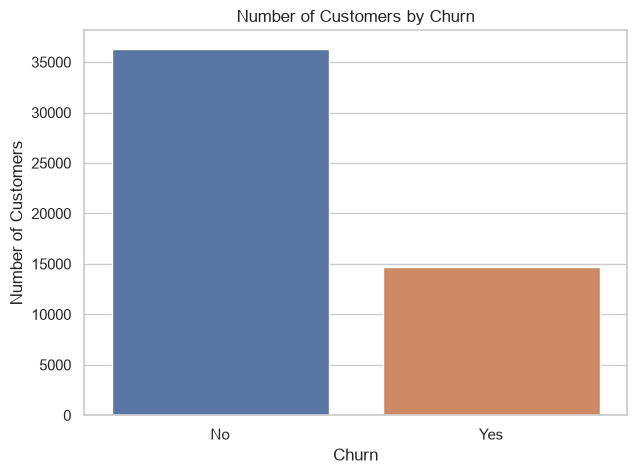

In [12]:
# Step 5: Count Customers by Churn
churn_counts = clean_train["Churn"].value_counts().reindex(["No", "Yes"])
plt.figure(figsize=(7, 5))
sns.barplot(x=churn_counts.index, y=churn_counts.values, hue=churn_counts.index, legend=False)
plt.title("Number of Customers by Churn")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [13]:
# Step 5: Calculate the Churn Percentages
churn_percentages = clean_train["Churn"].value_counts(normalize=True).mul(100)
print(churn_percentages.round(2))

Churn
No     71.18
Yes    28.82
Name: proportion, dtype: float64


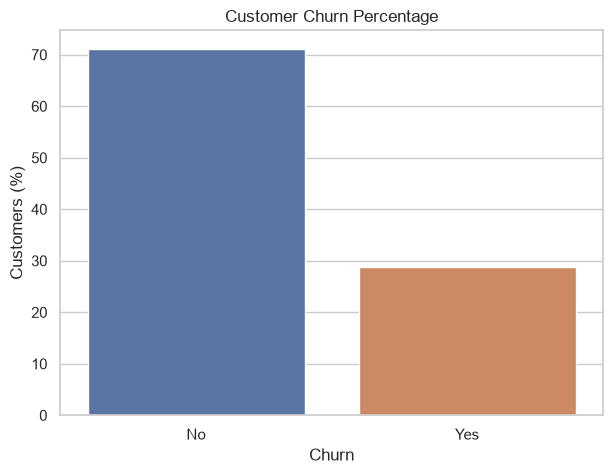

In [14]:
# Step 5: Plot the Churn Percentages
plt.figure(figsize=(7, 5))
sns.barplot(x=churn_percentages.index, y=churn_percentages.values, hue=churn_percentages.index, legend=False)
plt.title("Customer Churn Percentage")
plt.xlabel("Churn")
plt.ylabel("Customers (%)")
plt.show()

In [15]:
# Step 5: Select Numeric Features to Explore
eda_numeric_features = clean_train.drop(columns=["CustomerID", "Churn"]).select_dtypes(include="number").columns.tolist()
print("Numeric features:", len(eda_numeric_features))
print(eda_numeric_features)

Numeric features: 34
['MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'RetentionCalls', 'RetentionOffersAccepted', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'AdjustmentsToCreditRating']


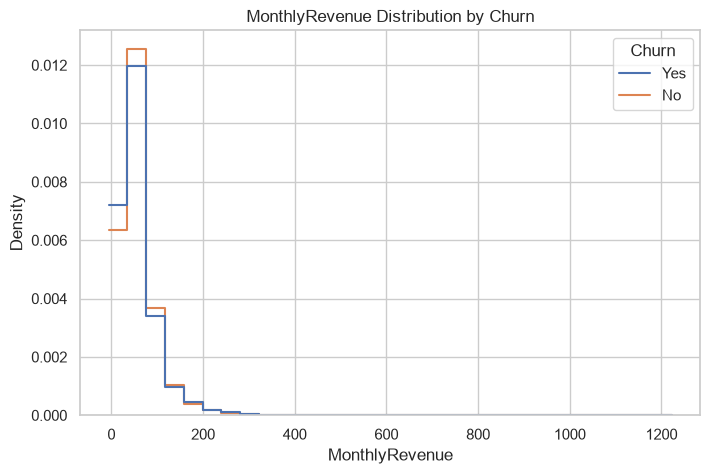

In [16]:
# Step 5: View MonthlyRevenue Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='MonthlyRevenue',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('MonthlyRevenue Distribution by Churn')
plt.xlabel('MonthlyRevenue')
plt.ylabel("Density")
plt.show()

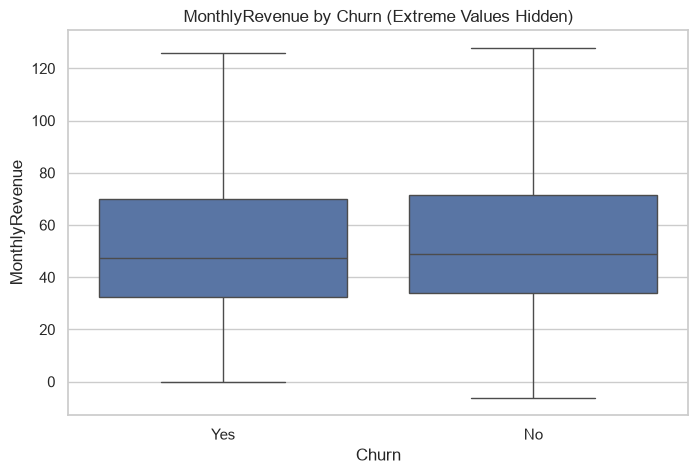

In [17]:
# Step 5: Compare MonthlyRevenue Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='MonthlyRevenue', showfliers=False)
plt.title('MonthlyRevenue by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('MonthlyRevenue')
plt.show()

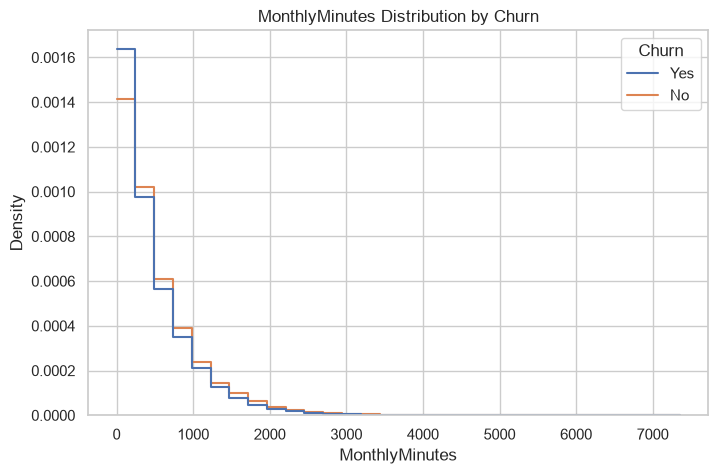

In [18]:
# Step 5: View MonthlyMinutes Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='MonthlyMinutes',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('MonthlyMinutes Distribution by Churn')
plt.xlabel('MonthlyMinutes')
plt.ylabel("Density")
plt.show()

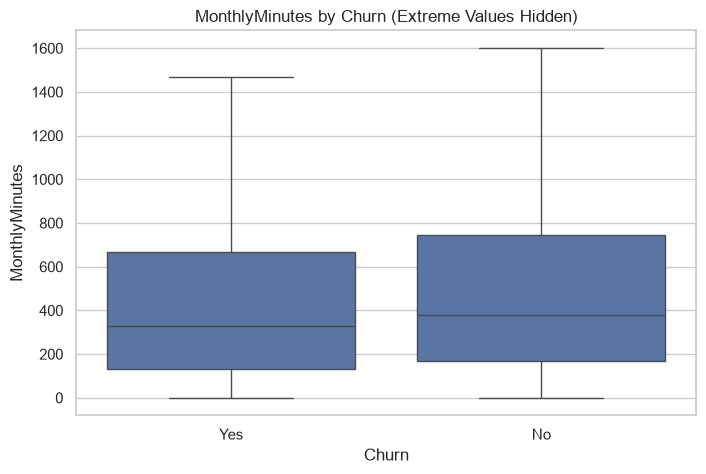

In [19]:
# Step 5: Compare MonthlyMinutes Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='MonthlyMinutes', showfliers=False)
plt.title('MonthlyMinutes by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('MonthlyMinutes')
plt.show()

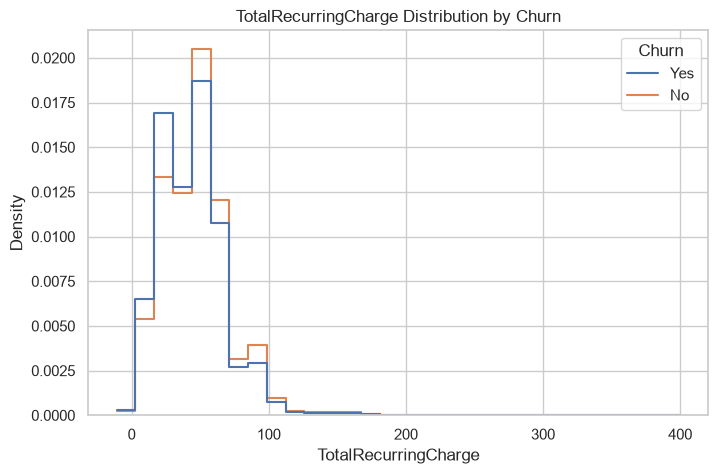

In [20]:
# Step 5: View TotalRecurringCharge Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='TotalRecurringCharge',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('TotalRecurringCharge Distribution by Churn')
plt.xlabel('TotalRecurringCharge')
plt.ylabel("Density")
plt.show()

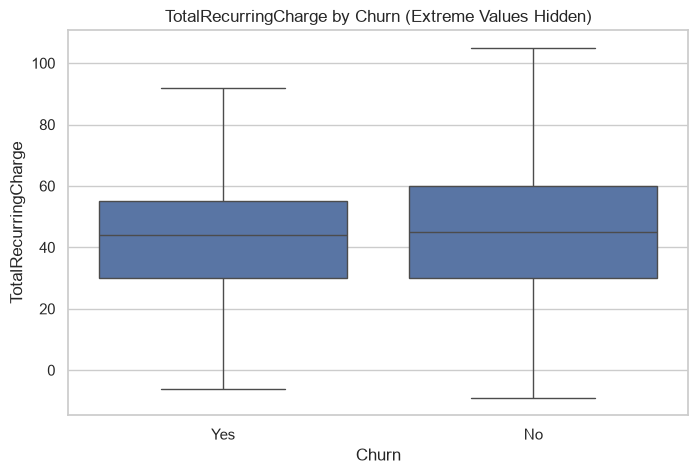

In [21]:
# Step 5: Compare TotalRecurringCharge Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='TotalRecurringCharge', showfliers=False)
plt.title('TotalRecurringCharge by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('TotalRecurringCharge')
plt.show()

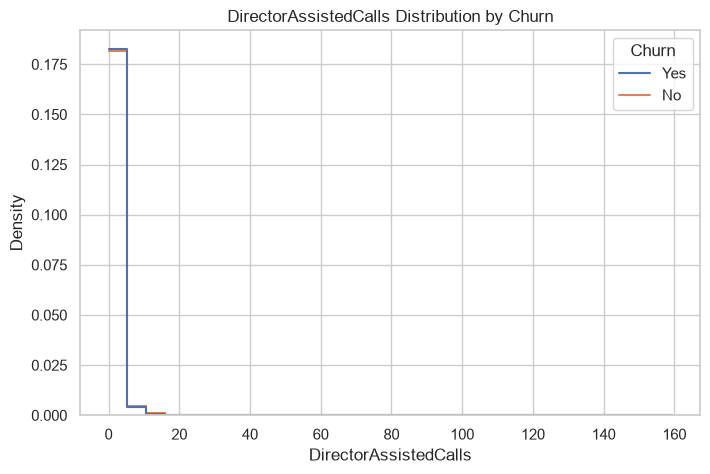

In [22]:
# Step 5: View DirectorAssistedCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='DirectorAssistedCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('DirectorAssistedCalls Distribution by Churn')
plt.xlabel('DirectorAssistedCalls')
plt.ylabel("Density")
plt.show()

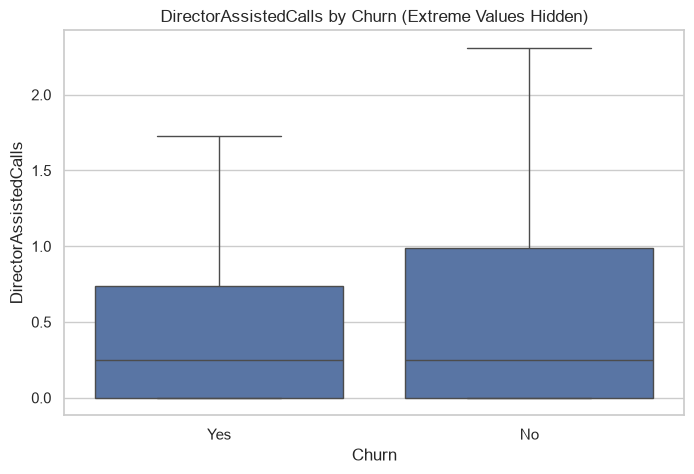

In [23]:
# Step 5: Compare DirectorAssistedCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='DirectorAssistedCalls', showfliers=False)
plt.title('DirectorAssistedCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('DirectorAssistedCalls')
plt.show()

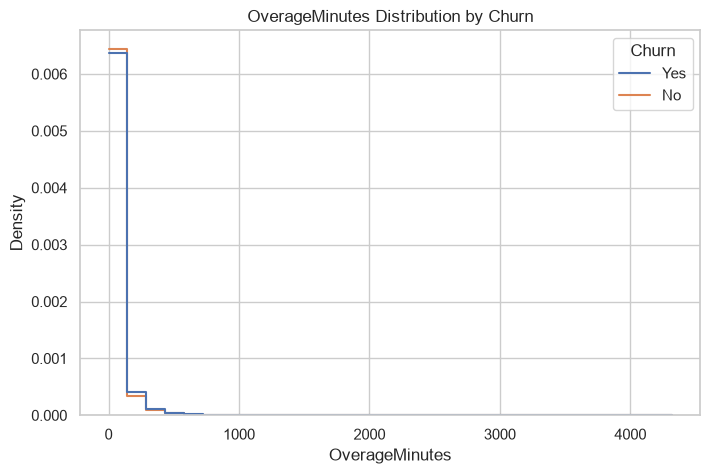

In [24]:
# Step 5: View OverageMinutes Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='OverageMinutes',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('OverageMinutes Distribution by Churn')
plt.xlabel('OverageMinutes')
plt.ylabel("Density")
plt.show()

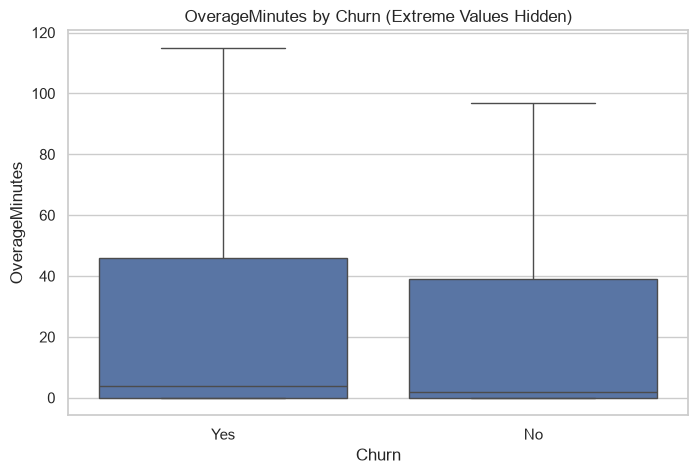

In [25]:
# Step 5: Compare OverageMinutes Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='OverageMinutes', showfliers=False)
plt.title('OverageMinutes by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('OverageMinutes')
plt.show()

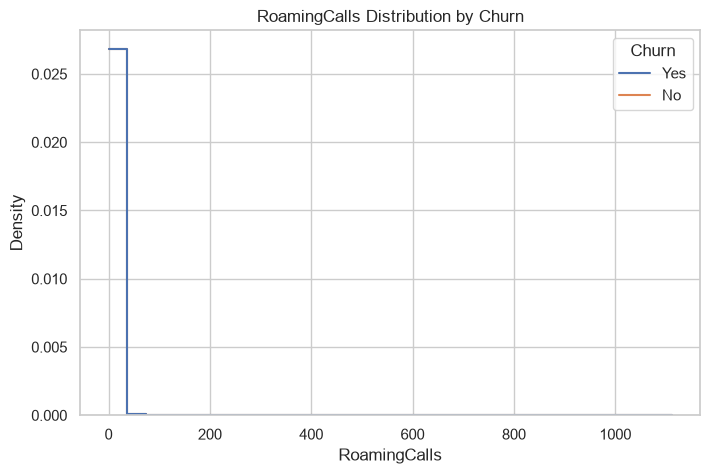

In [26]:
# Step 5: View RoamingCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='RoamingCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('RoamingCalls Distribution by Churn')
plt.xlabel('RoamingCalls')
plt.ylabel("Density")
plt.show()

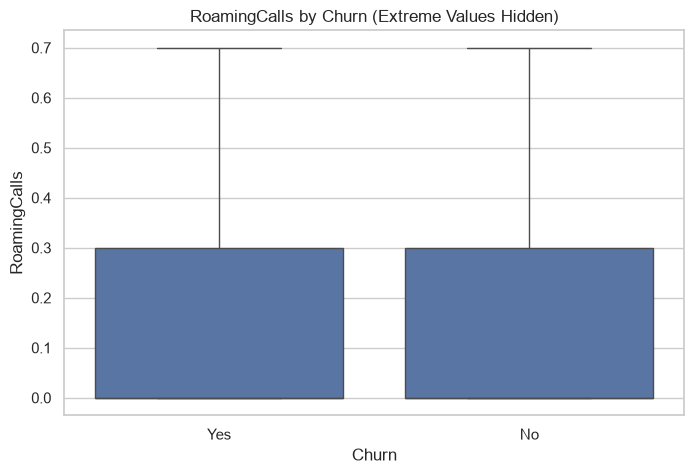

In [27]:
# Step 5: Compare RoamingCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='RoamingCalls', showfliers=False)
plt.title('RoamingCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('RoamingCalls')
plt.show()

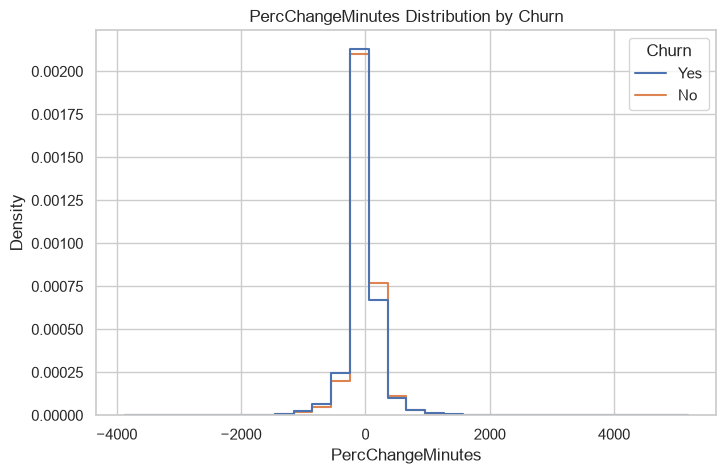

In [28]:
# Step 5: View PercChangeMinutes Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='PercChangeMinutes',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('PercChangeMinutes Distribution by Churn')
plt.xlabel('PercChangeMinutes')
plt.ylabel("Density")
plt.show()

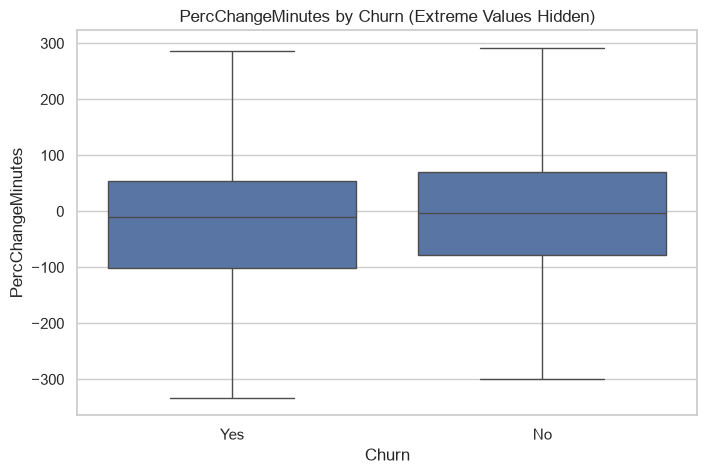

In [29]:
# Step 5: Compare PercChangeMinutes Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='PercChangeMinutes', showfliers=False)
plt.title('PercChangeMinutes by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('PercChangeMinutes')
plt.show()

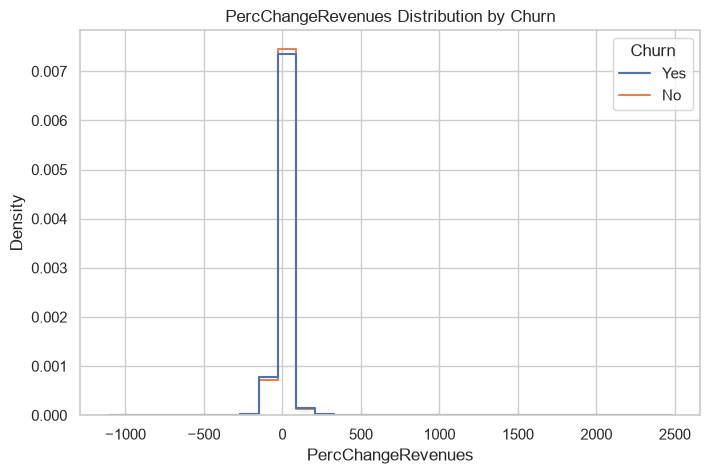

In [30]:
# Step 5: View PercChangeRevenues Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='PercChangeRevenues',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('PercChangeRevenues Distribution by Churn')
plt.xlabel('PercChangeRevenues')
plt.ylabel("Density")
plt.show()

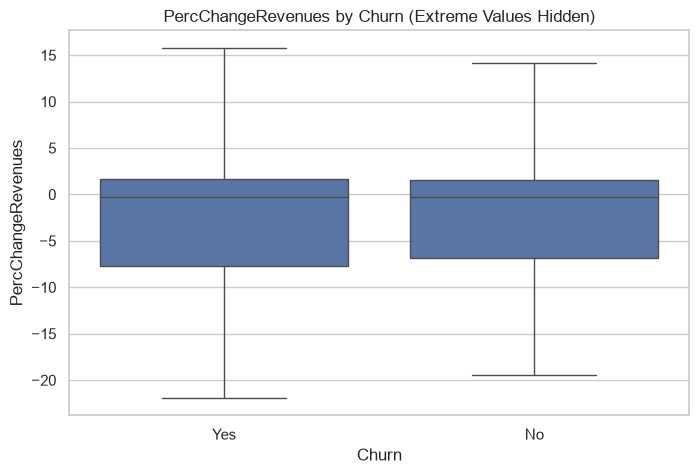

In [31]:
# Step 5: Compare PercChangeRevenues Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='PercChangeRevenues', showfliers=False)
plt.title('PercChangeRevenues by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('PercChangeRevenues')
plt.show()

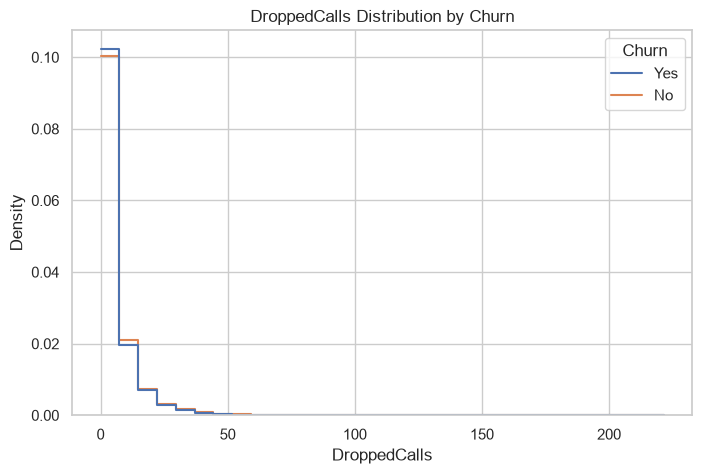

In [32]:
# Step 5: View DroppedCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='DroppedCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('DroppedCalls Distribution by Churn')
plt.xlabel('DroppedCalls')
plt.ylabel("Density")
plt.show()

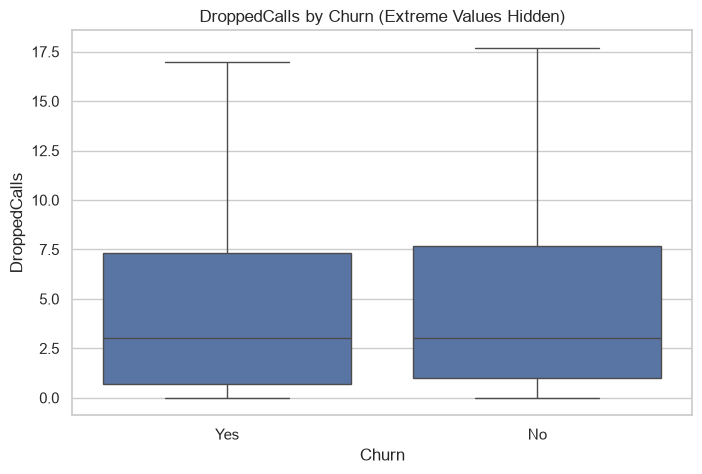

In [33]:
# Step 5: Compare DroppedCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='DroppedCalls', showfliers=False)
plt.title('DroppedCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('DroppedCalls')
plt.show()

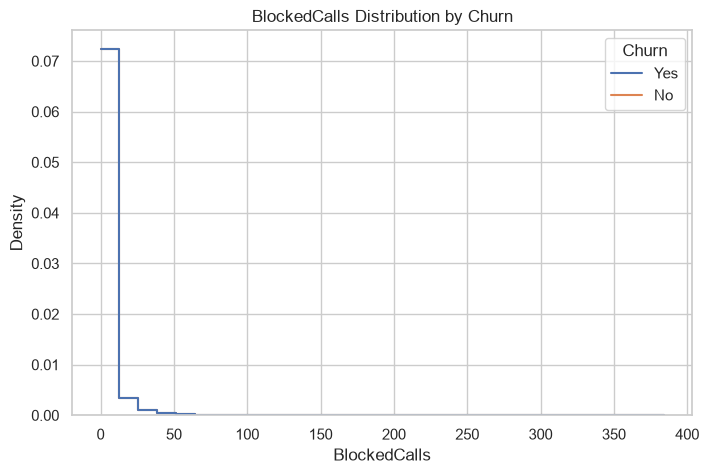

In [34]:
# Step 5: View BlockedCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='BlockedCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('BlockedCalls Distribution by Churn')
plt.xlabel('BlockedCalls')
plt.ylabel("Density")
plt.show()

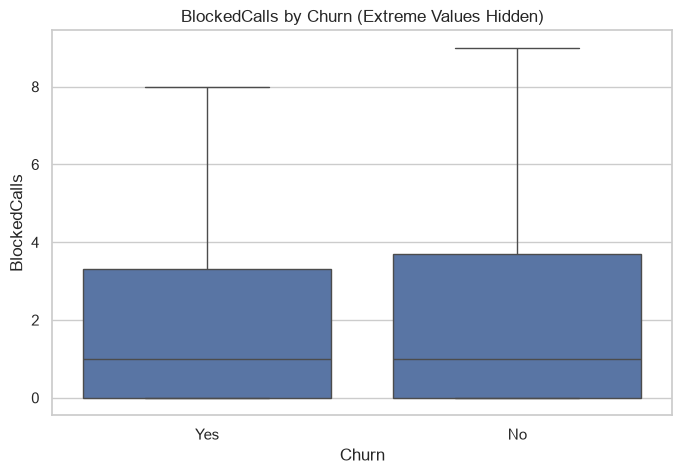

In [35]:
# Step 5: Compare BlockedCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='BlockedCalls', showfliers=False)
plt.title('BlockedCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('BlockedCalls')
plt.show()

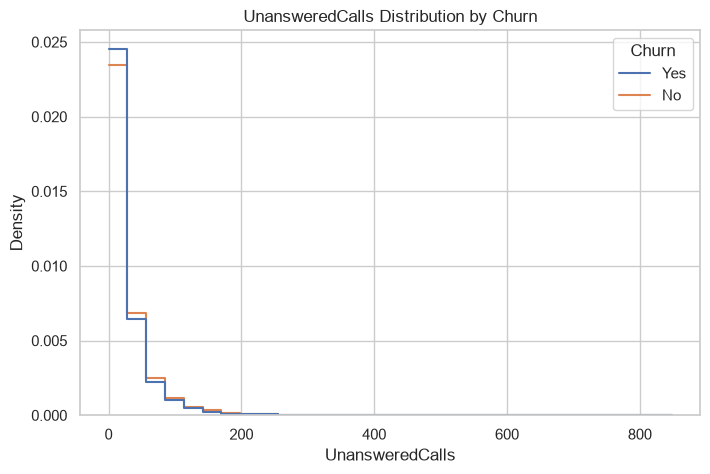

In [36]:
# Step 5: View UnansweredCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='UnansweredCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('UnansweredCalls Distribution by Churn')
plt.xlabel('UnansweredCalls')
plt.ylabel("Density")
plt.show()

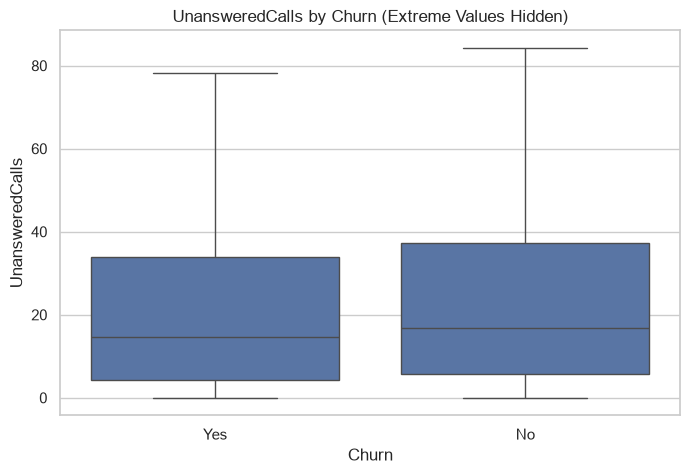

In [37]:
# Step 5: Compare UnansweredCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='UnansweredCalls', showfliers=False)
plt.title('UnansweredCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('UnansweredCalls')
plt.show()

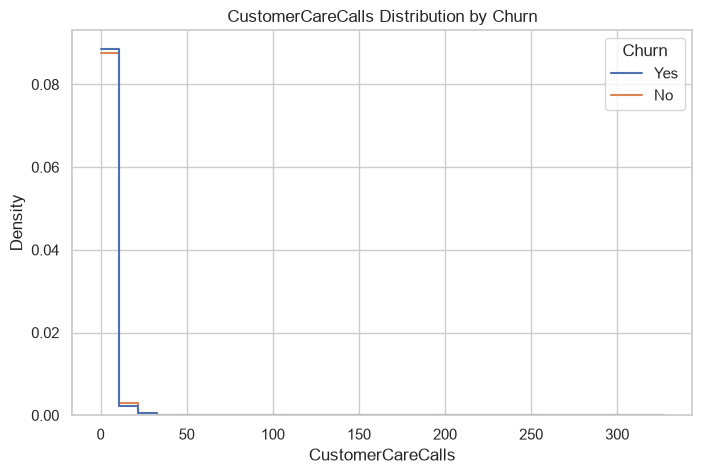

In [38]:
# Step 5: View CustomerCareCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='CustomerCareCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('CustomerCareCalls Distribution by Churn')
plt.xlabel('CustomerCareCalls')
plt.ylabel("Density")
plt.show()

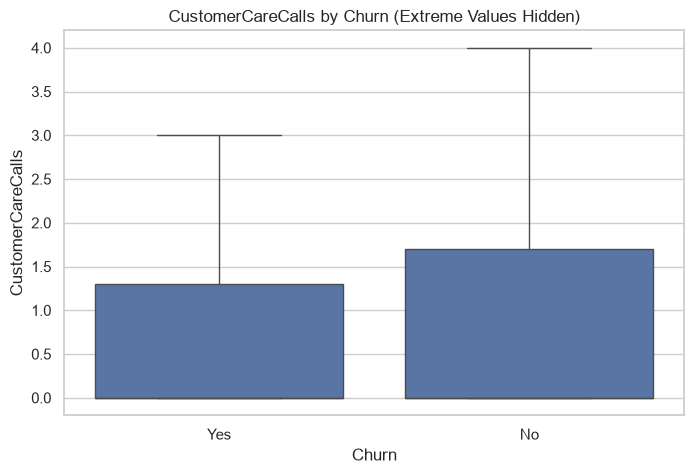

In [39]:
# Step 5: Compare CustomerCareCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='CustomerCareCalls', showfliers=False)
plt.title('CustomerCareCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('CustomerCareCalls')
plt.show()

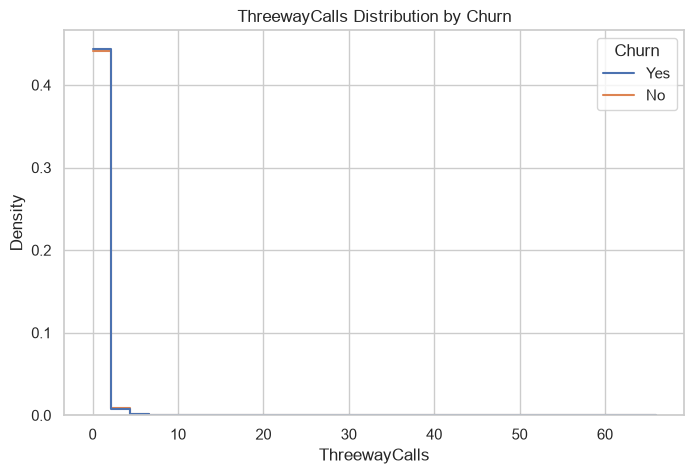

In [40]:
# Step 5: View ThreewayCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='ThreewayCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('ThreewayCalls Distribution by Churn')
plt.xlabel('ThreewayCalls')
plt.ylabel("Density")
plt.show()

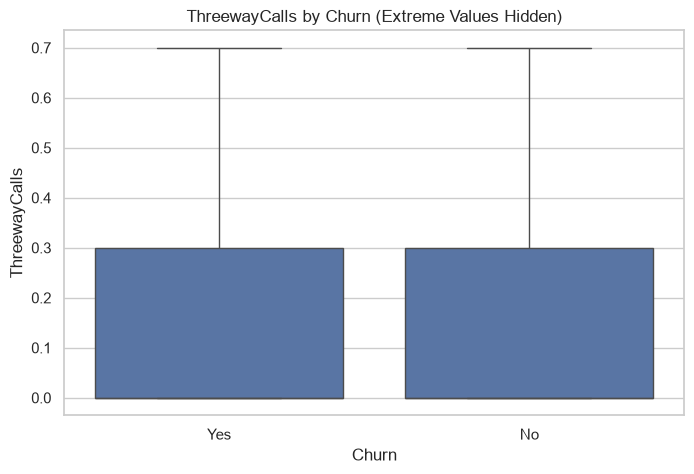

In [41]:
# Step 5: Compare ThreewayCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='ThreewayCalls', showfliers=False)
plt.title('ThreewayCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('ThreewayCalls')
plt.show()

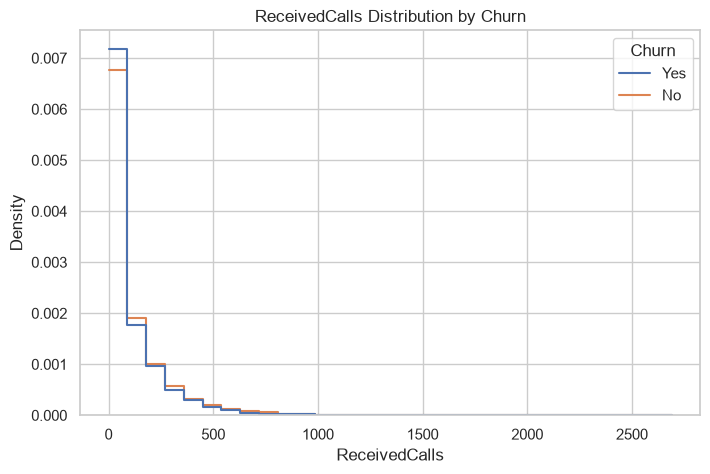

In [42]:
# Step 5: View ReceivedCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='ReceivedCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('ReceivedCalls Distribution by Churn')
plt.xlabel('ReceivedCalls')
plt.ylabel("Density")
plt.show()

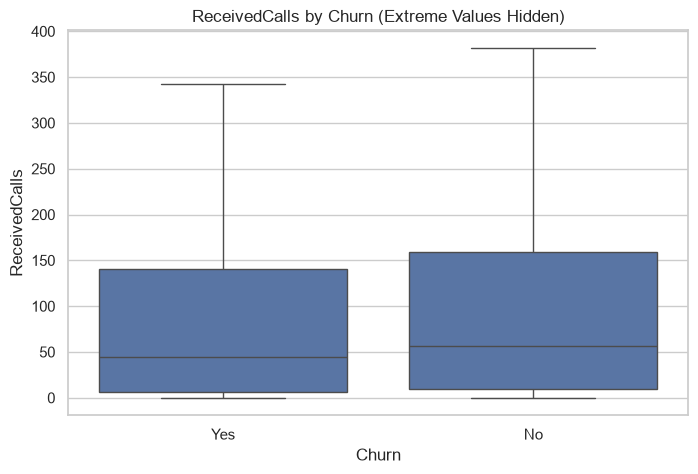

In [43]:
# Step 5: Compare ReceivedCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='ReceivedCalls', showfliers=False)
plt.title('ReceivedCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('ReceivedCalls')
plt.show()

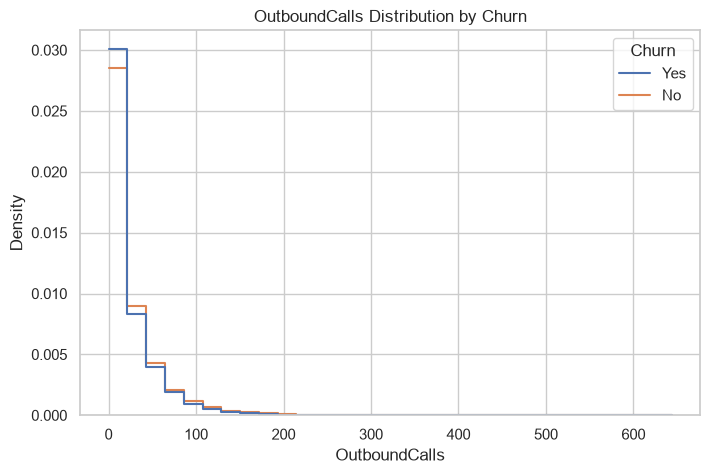

In [44]:
# Step 5: View OutboundCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='OutboundCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('OutboundCalls Distribution by Churn')
plt.xlabel('OutboundCalls')
plt.ylabel("Density")
plt.show()

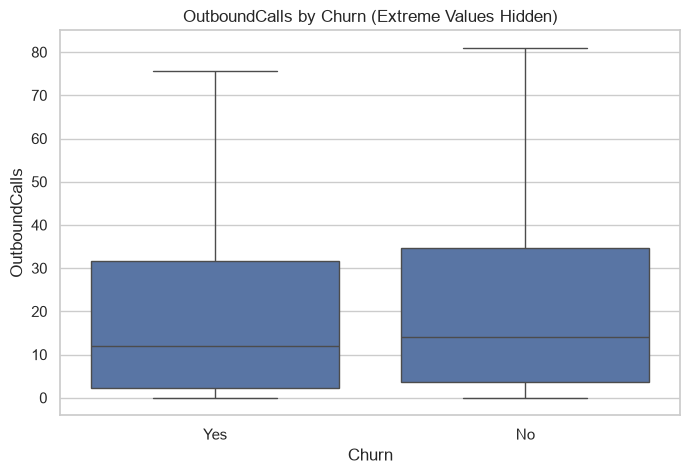

In [45]:
# Step 5: Compare OutboundCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='OutboundCalls', showfliers=False)
plt.title('OutboundCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('OutboundCalls')
plt.show()

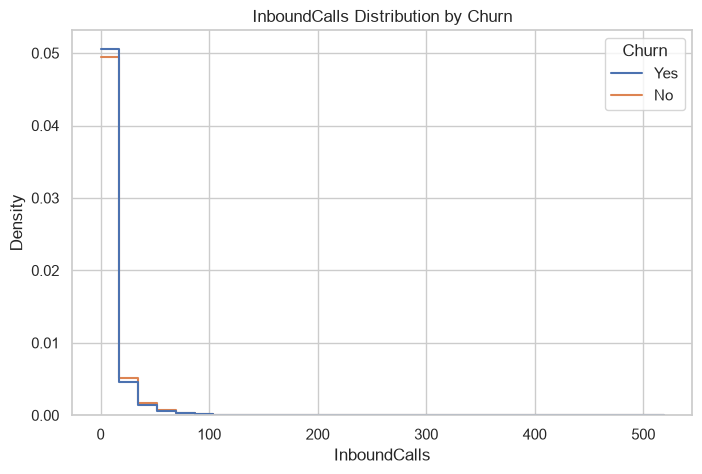

In [46]:
# Step 5: View InboundCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='InboundCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('InboundCalls Distribution by Churn')
plt.xlabel('InboundCalls')
plt.ylabel("Density")
plt.show()

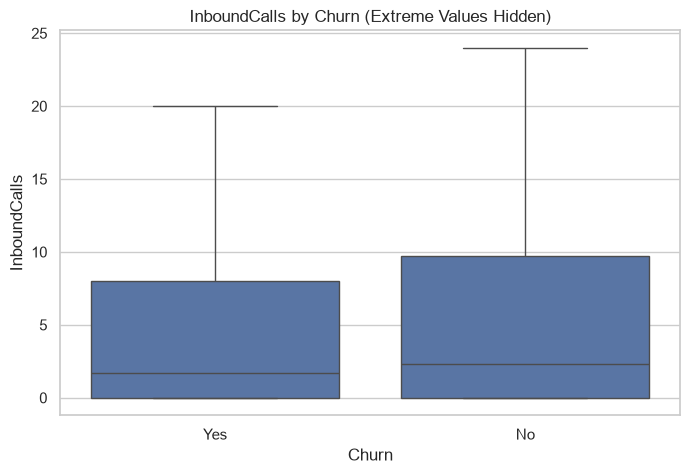

In [47]:
# Step 5: Compare InboundCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='InboundCalls', showfliers=False)
plt.title('InboundCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('InboundCalls')
plt.show()

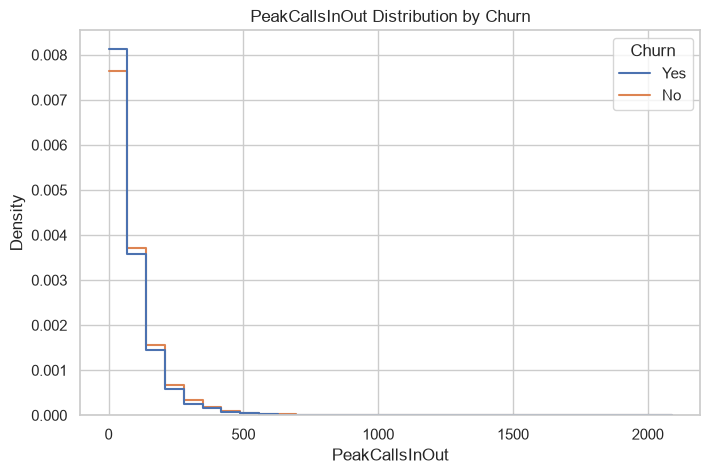

In [48]:
# Step 5: View PeakCallsInOut Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='PeakCallsInOut',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('PeakCallsInOut Distribution by Churn')
plt.xlabel('PeakCallsInOut')
plt.ylabel("Density")
plt.show()

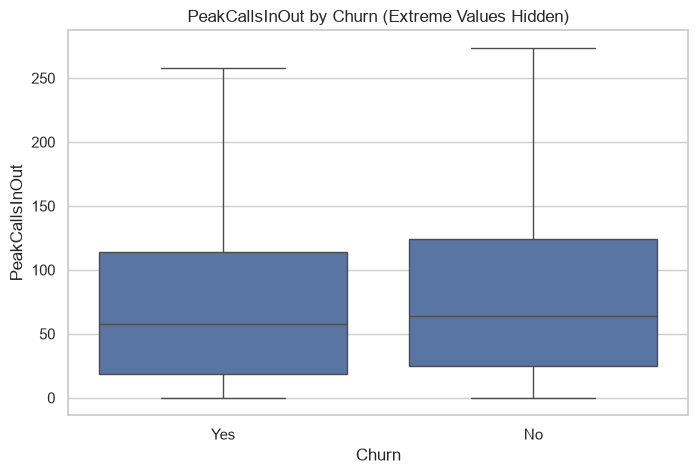

In [49]:
# Step 5: Compare PeakCallsInOut Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='PeakCallsInOut', showfliers=False)
plt.title('PeakCallsInOut by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('PeakCallsInOut')
plt.show()

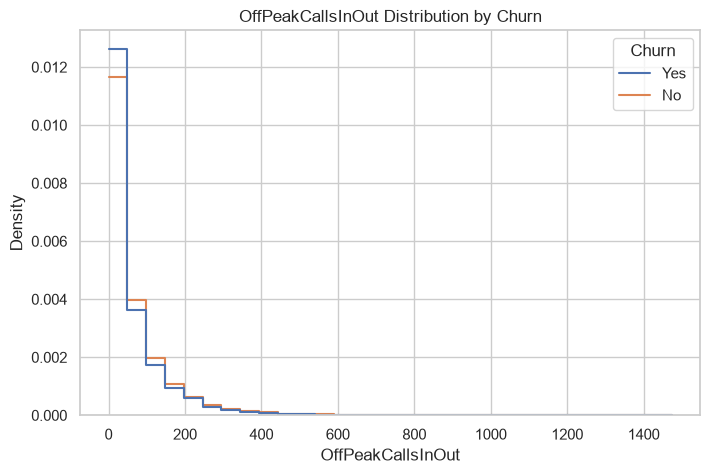

In [50]:
# Step 5: View OffPeakCallsInOut Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='OffPeakCallsInOut',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('OffPeakCallsInOut Distribution by Churn')
plt.xlabel('OffPeakCallsInOut')
plt.ylabel("Density")
plt.show()

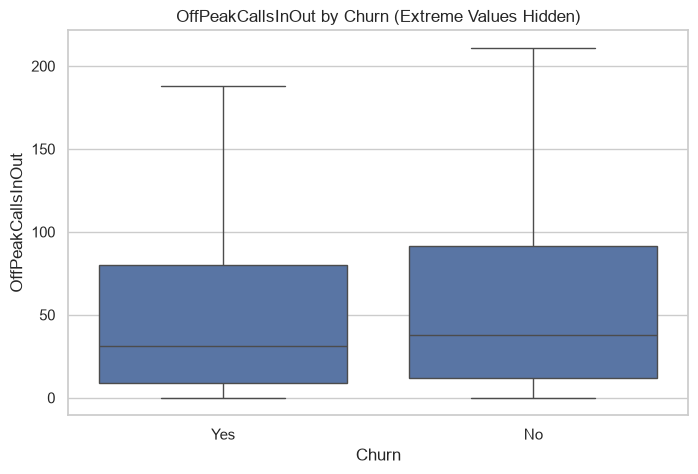

In [51]:
# Step 5: Compare OffPeakCallsInOut Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='OffPeakCallsInOut', showfliers=False)
plt.title('OffPeakCallsInOut by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('OffPeakCallsInOut')
plt.show()

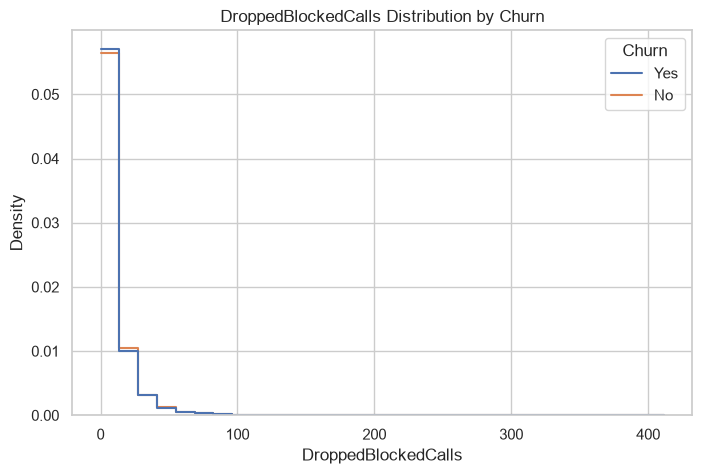

In [52]:
# Step 5: View DroppedBlockedCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='DroppedBlockedCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('DroppedBlockedCalls Distribution by Churn')
plt.xlabel('DroppedBlockedCalls')
plt.ylabel("Density")
plt.show()

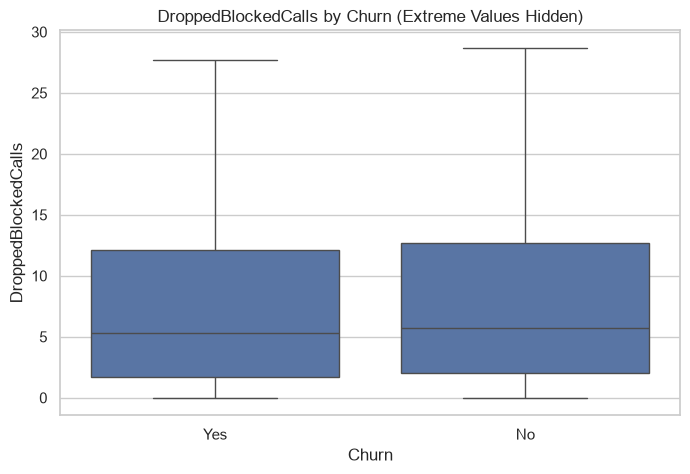

In [53]:
# Step 5: Compare DroppedBlockedCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='DroppedBlockedCalls', showfliers=False)
plt.title('DroppedBlockedCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('DroppedBlockedCalls')
plt.show()

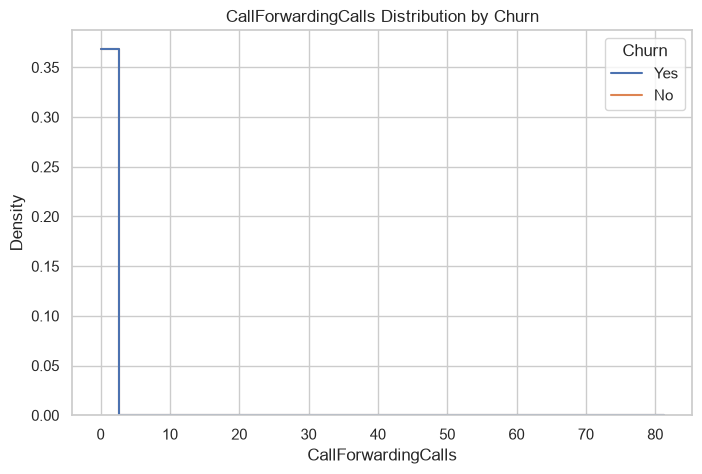

In [54]:
# Step 5: View CallForwardingCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='CallForwardingCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('CallForwardingCalls Distribution by Churn')
plt.xlabel('CallForwardingCalls')
plt.ylabel("Density")
plt.show()

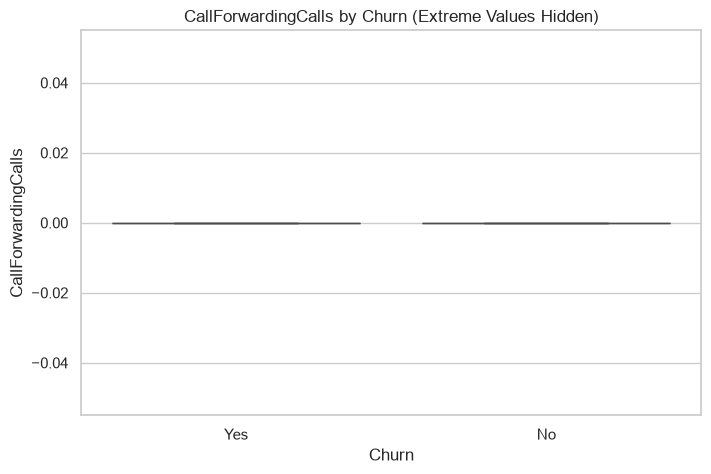

In [55]:
# Step 5: Compare CallForwardingCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='CallForwardingCalls', showfliers=False)
plt.title('CallForwardingCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('CallForwardingCalls')
plt.show()

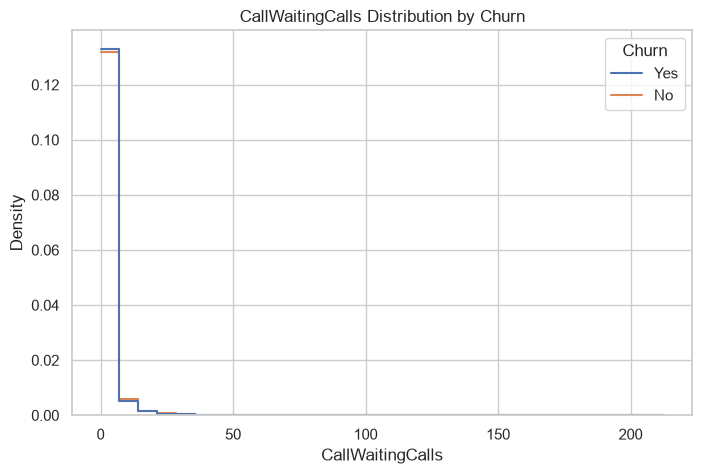

In [56]:
# Step 5: View CallWaitingCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='CallWaitingCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('CallWaitingCalls Distribution by Churn')
plt.xlabel('CallWaitingCalls')
plt.ylabel("Density")
plt.show()

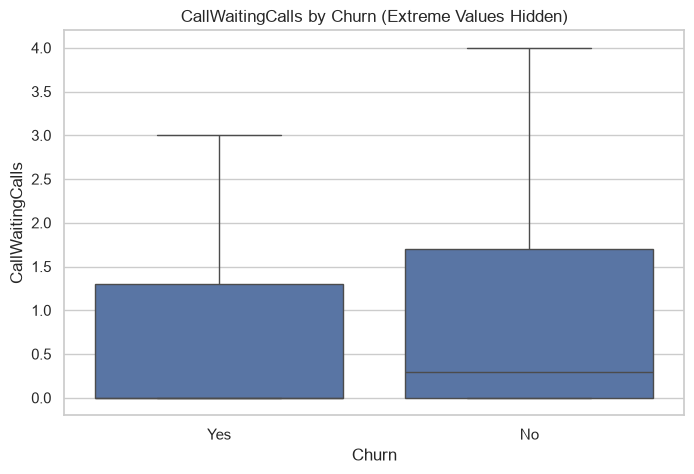

In [57]:
# Step 5: Compare CallWaitingCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='CallWaitingCalls', showfliers=False)
plt.title('CallWaitingCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('CallWaitingCalls')
plt.show()

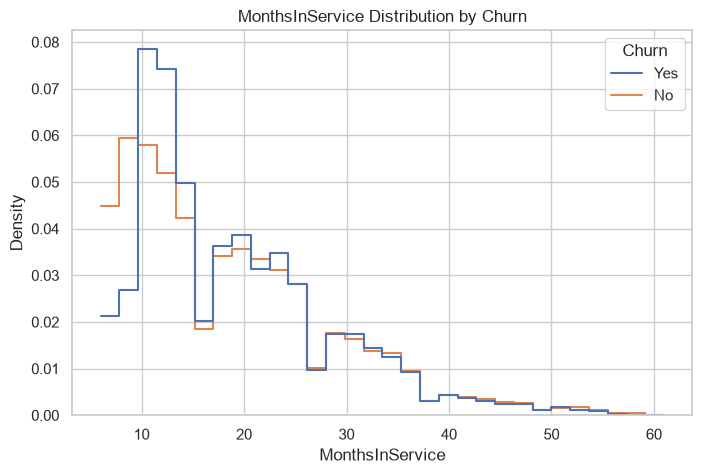

In [58]:
# Step 5: View MonthsInService Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='MonthsInService',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('MonthsInService Distribution by Churn')
plt.xlabel('MonthsInService')
plt.ylabel("Density")
plt.show()

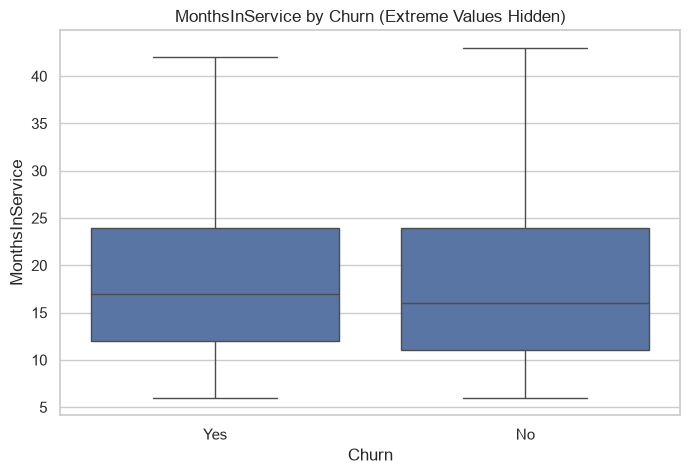

In [59]:
# Step 5: Compare MonthsInService Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='MonthsInService', showfliers=False)
plt.title('MonthsInService by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('MonthsInService')
plt.show()

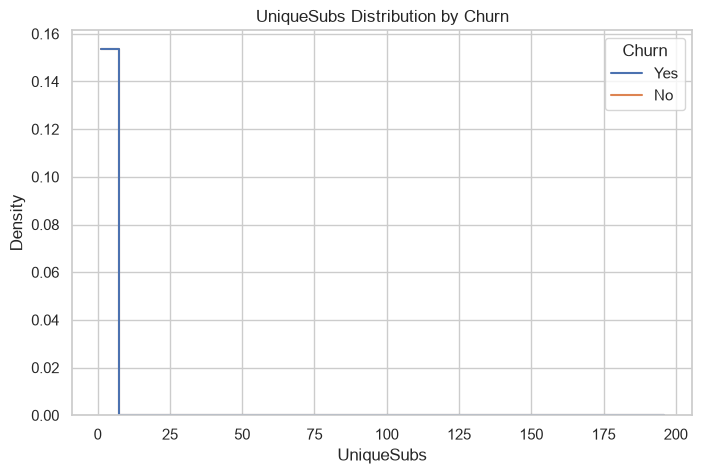

In [60]:
# Step 5: View UniqueSubs Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='UniqueSubs',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('UniqueSubs Distribution by Churn')
plt.xlabel('UniqueSubs')
plt.ylabel("Density")
plt.show()

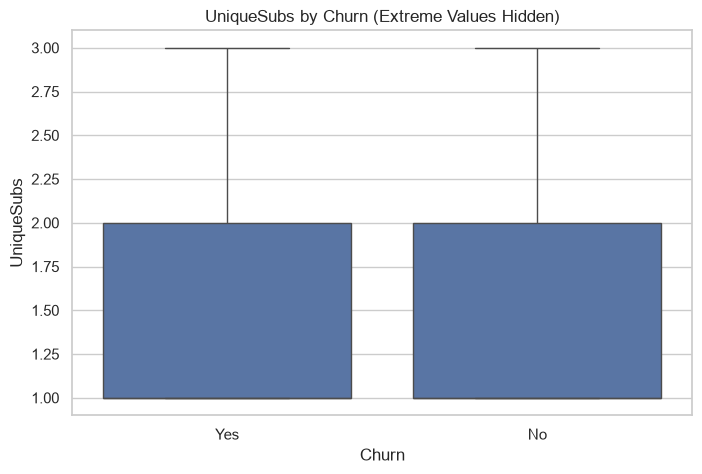

In [61]:
# Step 5: Compare UniqueSubs Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='UniqueSubs', showfliers=False)
plt.title('UniqueSubs by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('UniqueSubs')
plt.show()

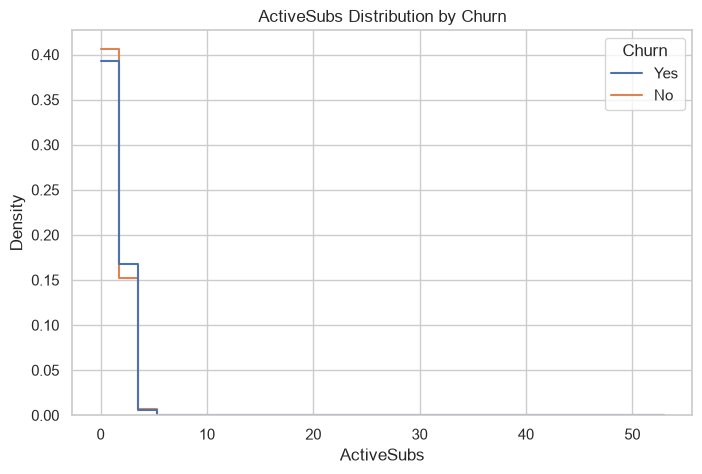

In [62]:
# Step 5: View ActiveSubs Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='ActiveSubs',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('ActiveSubs Distribution by Churn')
plt.xlabel('ActiveSubs')
plt.ylabel("Density")
plt.show()

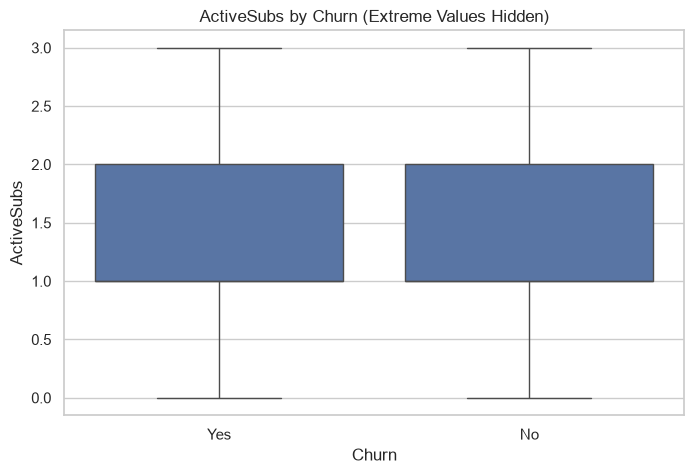

In [63]:
# Step 5: Compare ActiveSubs Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='ActiveSubs', showfliers=False)
plt.title('ActiveSubs by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('ActiveSubs')
plt.show()

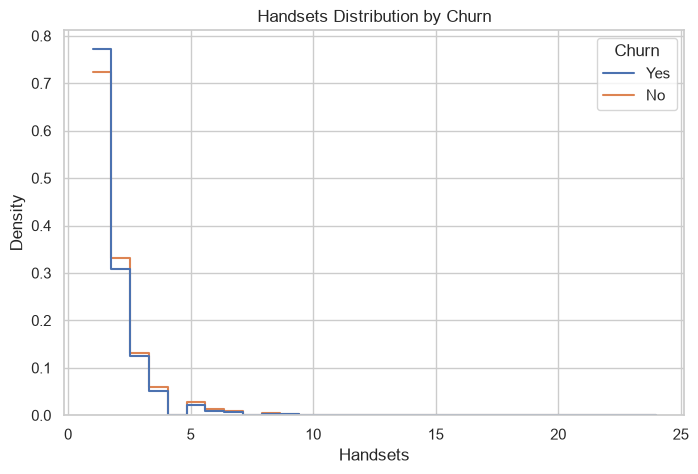

In [64]:
# Step 5: View Handsets Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='Handsets',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('Handsets Distribution by Churn')
plt.xlabel('Handsets')
plt.ylabel("Density")
plt.show()

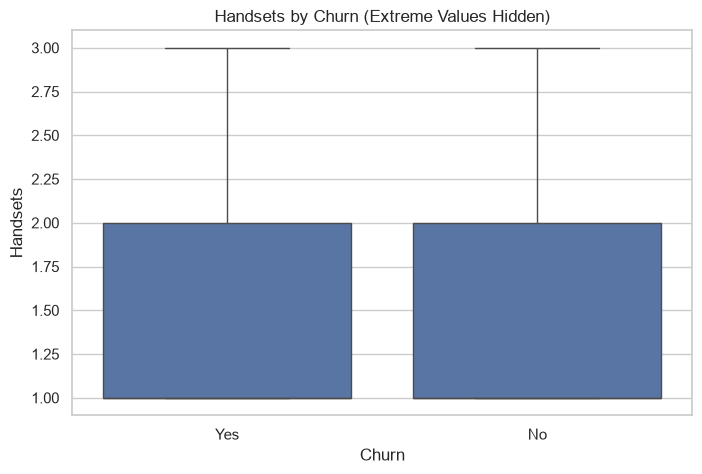

In [65]:
# Step 5: Compare Handsets Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='Handsets', showfliers=False)
plt.title('Handsets by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('Handsets')
plt.show()

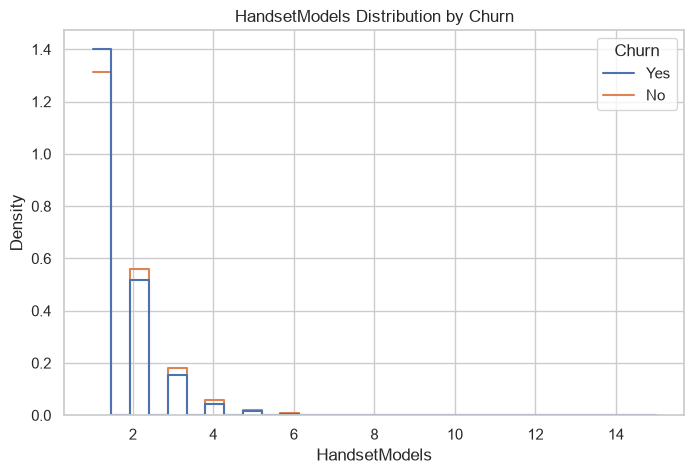

In [66]:
# Step 5: View HandsetModels Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='HandsetModels',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('HandsetModels Distribution by Churn')
plt.xlabel('HandsetModels')
plt.ylabel("Density")
plt.show()

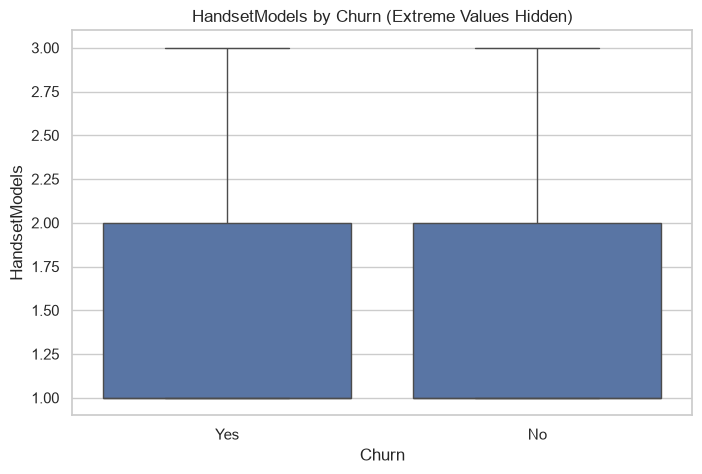

In [67]:
# Step 5: Compare HandsetModels Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='HandsetModels', showfliers=False)
plt.title('HandsetModels by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('HandsetModels')
plt.show()

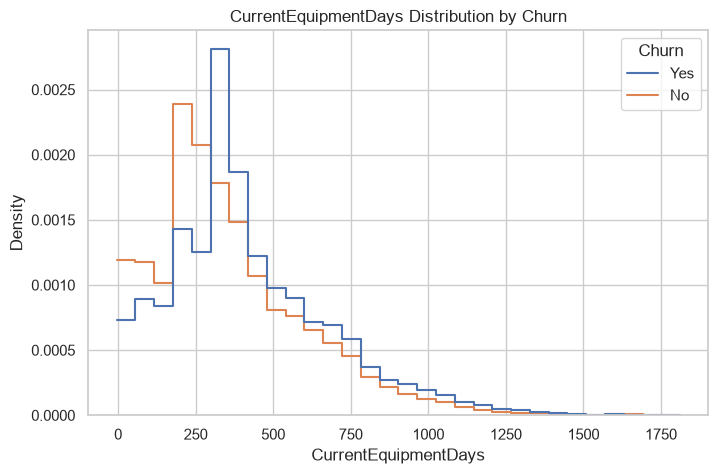

In [68]:
# Step 5: View CurrentEquipmentDays Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='CurrentEquipmentDays',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('CurrentEquipmentDays Distribution by Churn')
plt.xlabel('CurrentEquipmentDays')
plt.ylabel("Density")
plt.show()

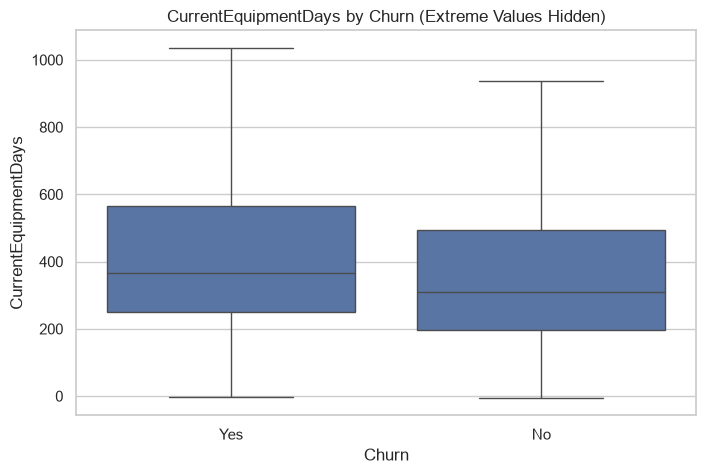

In [69]:
# Step 5: Compare CurrentEquipmentDays Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='CurrentEquipmentDays', showfliers=False)
plt.title('CurrentEquipmentDays by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('CurrentEquipmentDays')
plt.show()

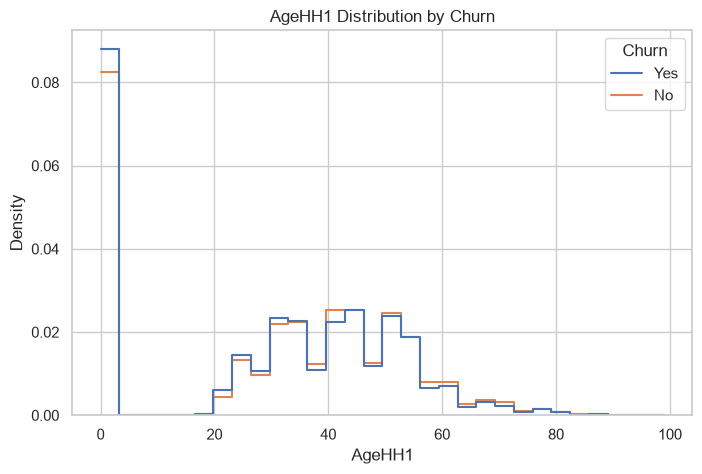

In [70]:
# Step 5: View AgeHH1 Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='AgeHH1',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('AgeHH1 Distribution by Churn')
plt.xlabel('AgeHH1')
plt.ylabel("Density")
plt.show()

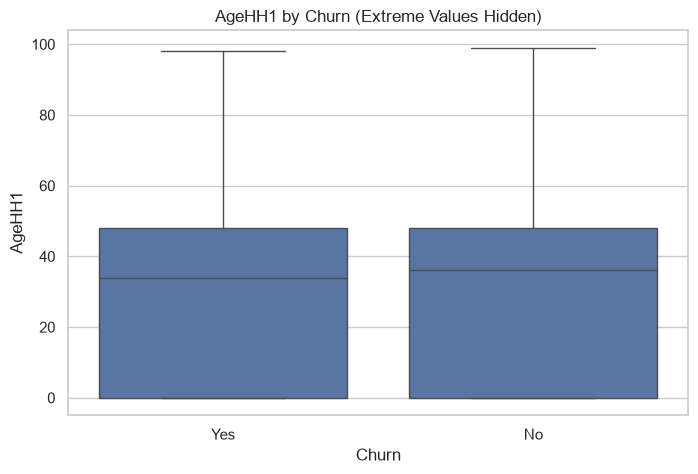

In [71]:
# Step 5: Compare AgeHH1 Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='AgeHH1', showfliers=False)
plt.title('AgeHH1 by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('AgeHH1')
plt.show()

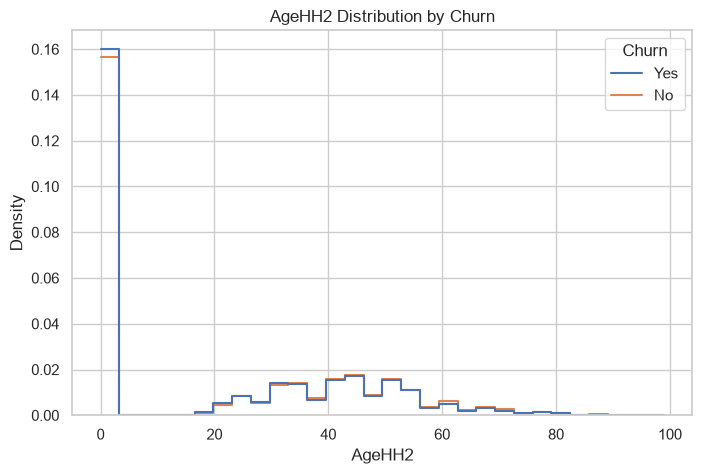

In [72]:
# Step 5: View AgeHH2 Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='AgeHH2',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('AgeHH2 Distribution by Churn')
plt.xlabel('AgeHH2')
plt.ylabel("Density")
plt.show()

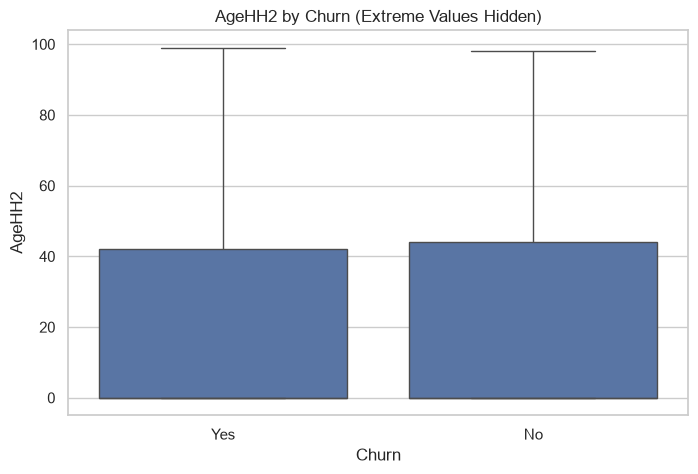

In [73]:
# Step 5: Compare AgeHH2 Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='AgeHH2', showfliers=False)
plt.title('AgeHH2 by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('AgeHH2')
plt.show()

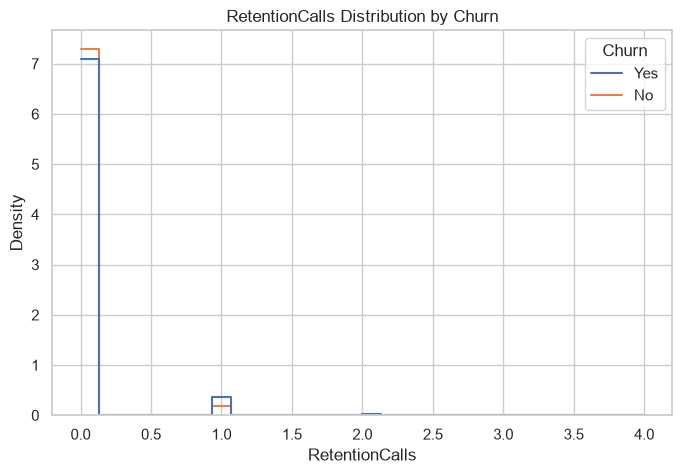

In [74]:
# Step 5: View RetentionCalls Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='RetentionCalls',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('RetentionCalls Distribution by Churn')
plt.xlabel('RetentionCalls')
plt.ylabel("Density")
plt.show()

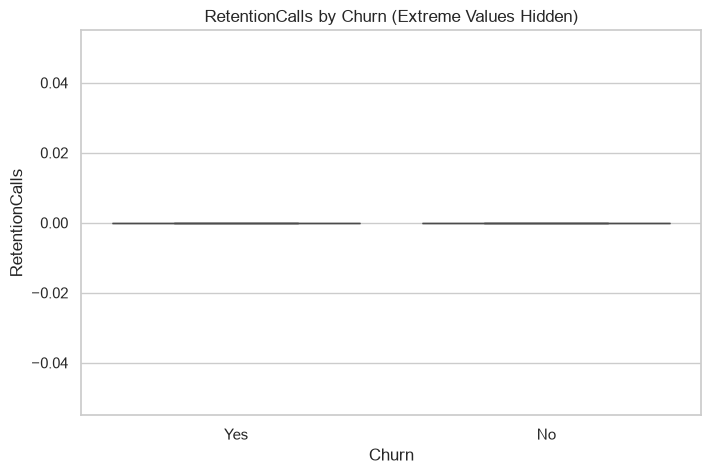

In [75]:
# Step 5: Compare RetentionCalls Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='RetentionCalls', showfliers=False)
plt.title('RetentionCalls by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('RetentionCalls')
plt.show()

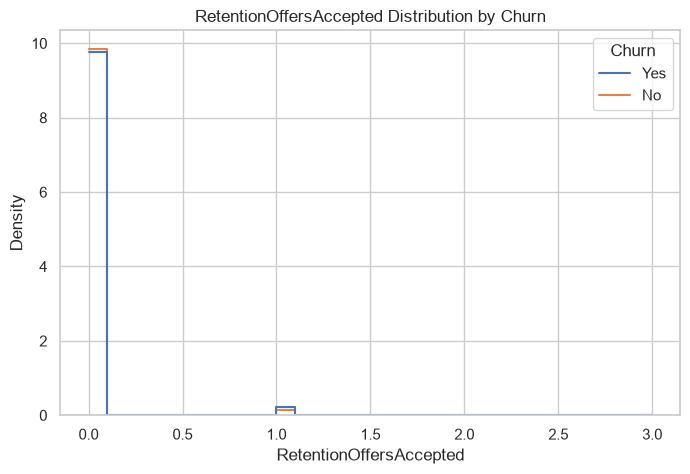

In [76]:
# Step 5: View RetentionOffersAccepted Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='RetentionOffersAccepted',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('RetentionOffersAccepted Distribution by Churn')
plt.xlabel('RetentionOffersAccepted')
plt.ylabel("Density")
plt.show()

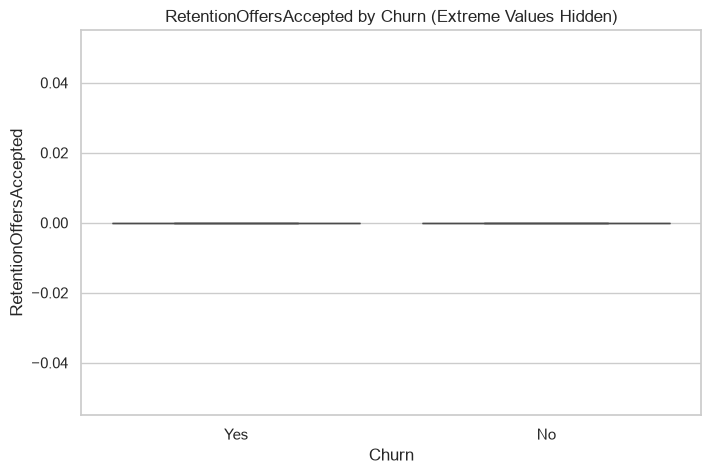

In [77]:
# Step 5: Compare RetentionOffersAccepted Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='RetentionOffersAccepted', showfliers=False)
plt.title('RetentionOffersAccepted by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('RetentionOffersAccepted')
plt.show()

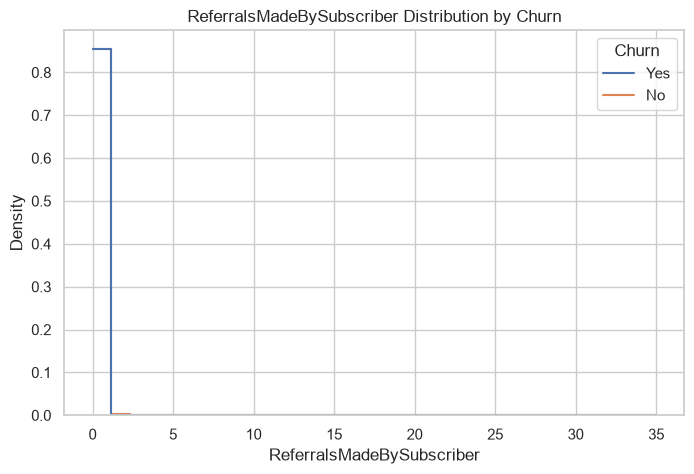

In [78]:
# Step 5: View ReferralsMadeBySubscriber Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='ReferralsMadeBySubscriber',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('ReferralsMadeBySubscriber Distribution by Churn')
plt.xlabel('ReferralsMadeBySubscriber')
plt.ylabel("Density")
plt.show()

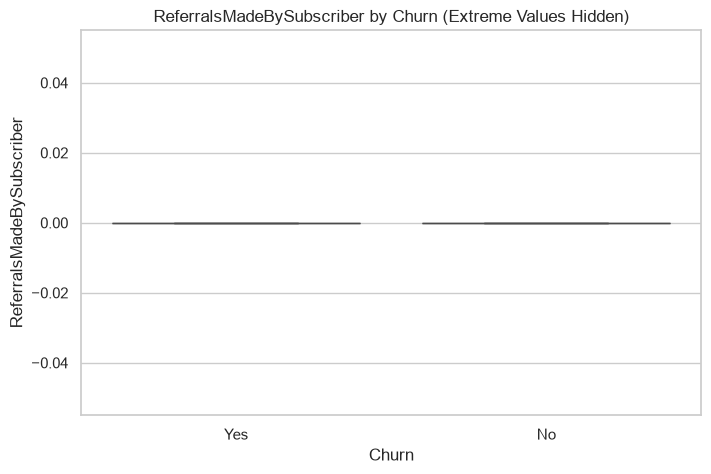

In [79]:
# Step 5: Compare ReferralsMadeBySubscriber Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='ReferralsMadeBySubscriber', showfliers=False)
plt.title('ReferralsMadeBySubscriber by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('ReferralsMadeBySubscriber')
plt.show()

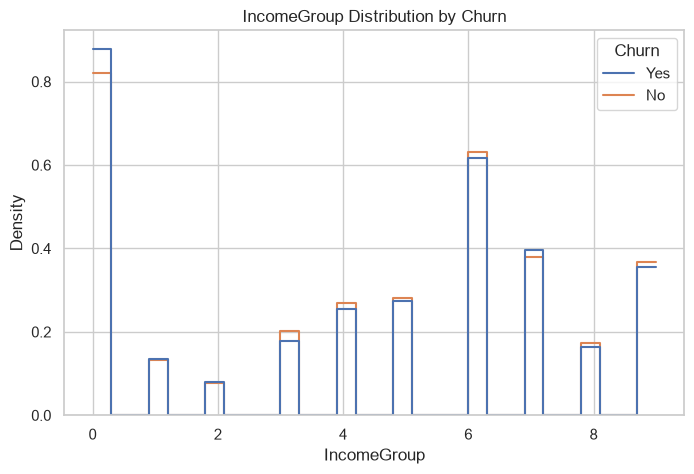

In [80]:
# Step 5: View IncomeGroup Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='IncomeGroup',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('IncomeGroup Distribution by Churn')
plt.xlabel('IncomeGroup')
plt.ylabel("Density")
plt.show()

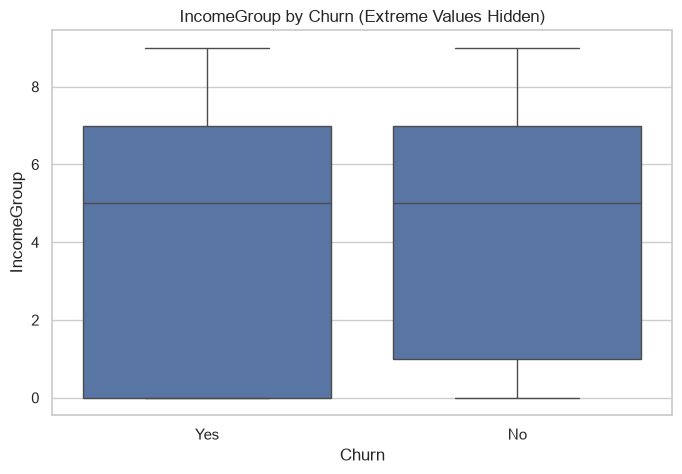

In [81]:
# Step 5: Compare IncomeGroup Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='IncomeGroup', showfliers=False)
plt.title('IncomeGroup by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('IncomeGroup')
plt.show()

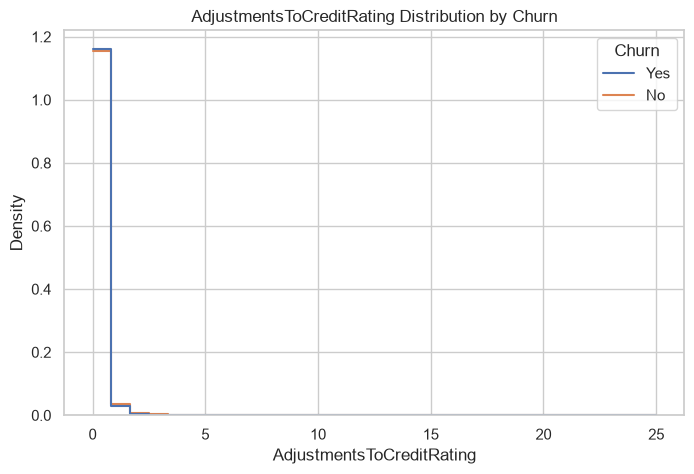

In [82]:
# Step 5: View AdjustmentsToCreditRating Distribution by Churn
plt.figure(figsize=(8, 5))
sns.histplot(
    data=clean_train,
    x='AdjustmentsToCreditRating',
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
)
plt.title('AdjustmentsToCreditRating Distribution by Churn')
plt.xlabel('AdjustmentsToCreditRating')
plt.ylabel("Density")
plt.show()

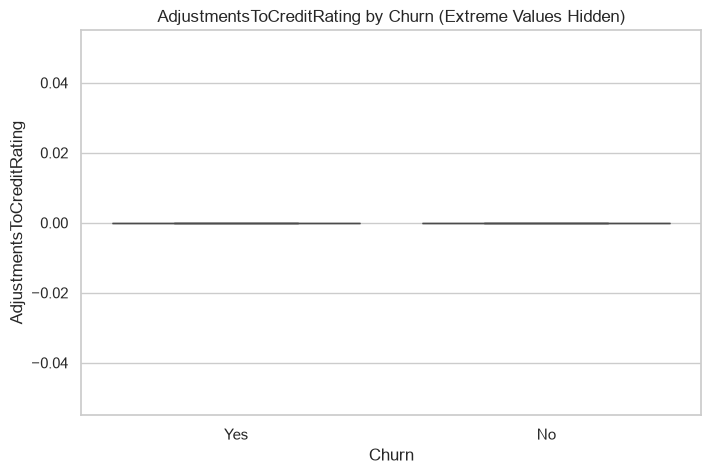

In [83]:
# Step 5: Compare AdjustmentsToCreditRating Across Churn Groups
plt.figure(figsize=(8, 5))
sns.boxplot(data=clean_train, x="Churn", y='AdjustmentsToCreditRating', showfliers=False)
plt.title('AdjustmentsToCreditRating by Churn (Extreme Values Hidden)')
plt.xlabel("Churn")
plt.ylabel('AdjustmentsToCreditRating')
plt.show()

In [84]:
# Step 5: Select Categorical Features to Explore
eda_categorical_features = clean_train.drop(columns=["CustomerID", "Churn"]).select_dtypes(exclude="number").columns.tolist()
print("Categorical features:", len(eda_categorical_features))
print(eda_categorical_features)

Categorical features: 22
['ServiceArea', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'NewCellphoneUser', 'NotNewCellphoneUser', 'OwnsMotorcycle', 'HandsetPrice', 'MadeCallToRetentionTeam', 'CreditRating', 'PrizmCode', 'Occupation', 'MaritalStatus']


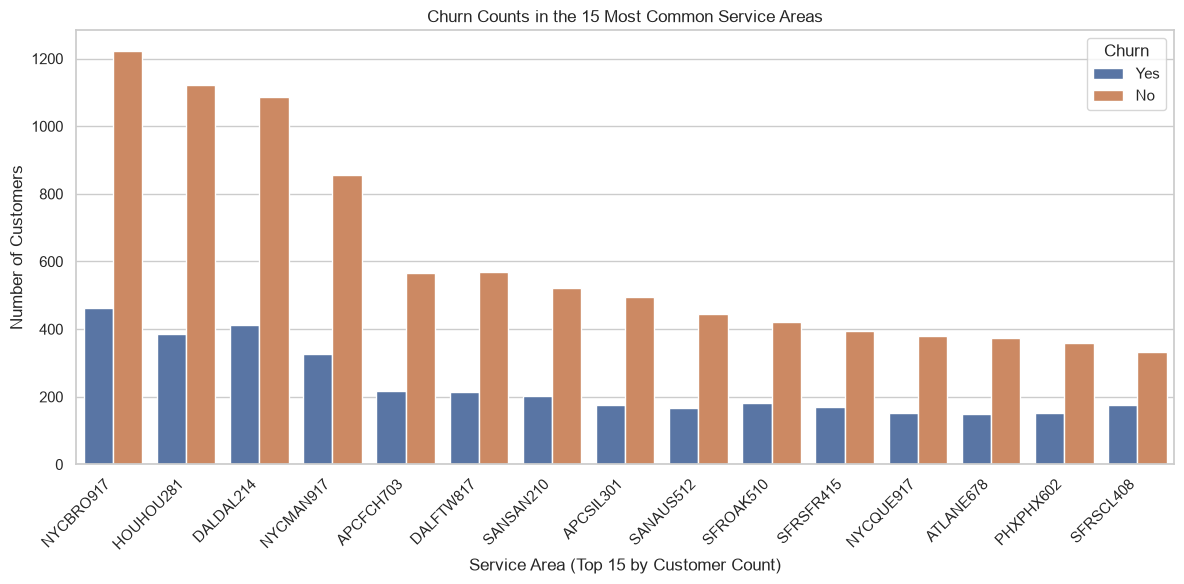

In [85]:
# Step 5: Compare Churn Counts in the 15 Most Common Service Areas
service_area_order = clean_train["ServiceArea"].value_counts().head(15).index
service_area_data = clean_train[clean_train["ServiceArea"].isin(service_area_order)]
plt.figure(figsize=(12, 6))
sns.countplot(data=service_area_data, x="ServiceArea", hue="Churn", order=service_area_order)
plt.title("Churn Counts in the 15 Most Common Service Areas")
plt.xlabel("Service Area (Top 15 by Customer Count)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

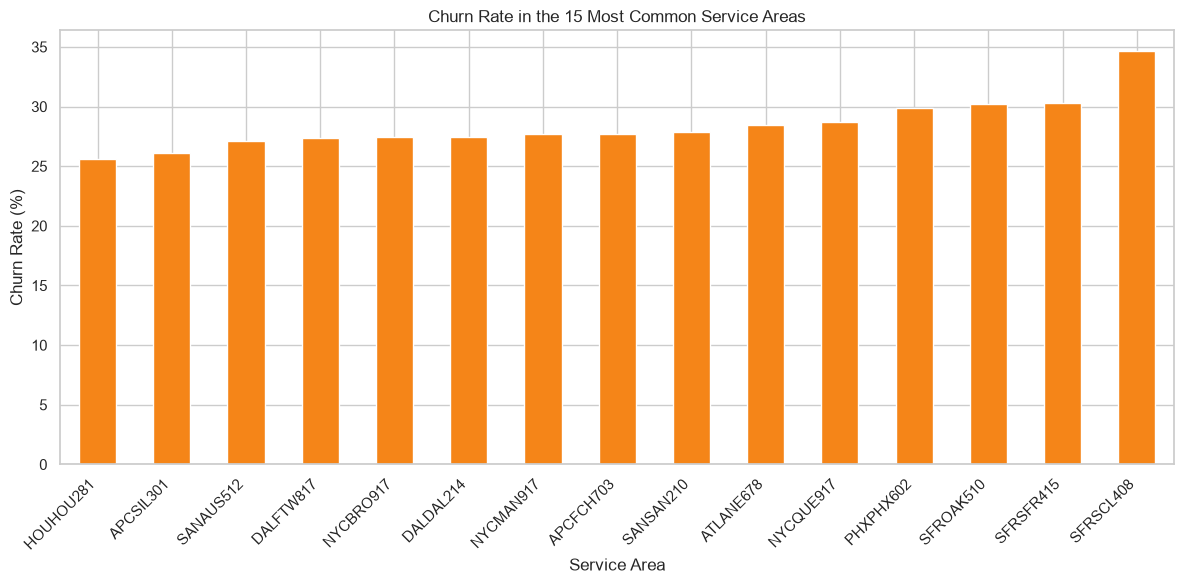

In [86]:
# Step 5: Compare Churn Rates in the 15 Most Common Service Areas
service_area_rates = service_area_data.groupby("ServiceArea", observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
)
service_area_rates = service_area_rates.reindex(service_area_order).sort_values()
plt.figure(figsize=(12, 6))
service_area_rates.plot(kind="bar", color="#F58518")
plt.title("Churn Rate in the 15 Most Common Service Areas")
plt.xlabel("Service Area")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

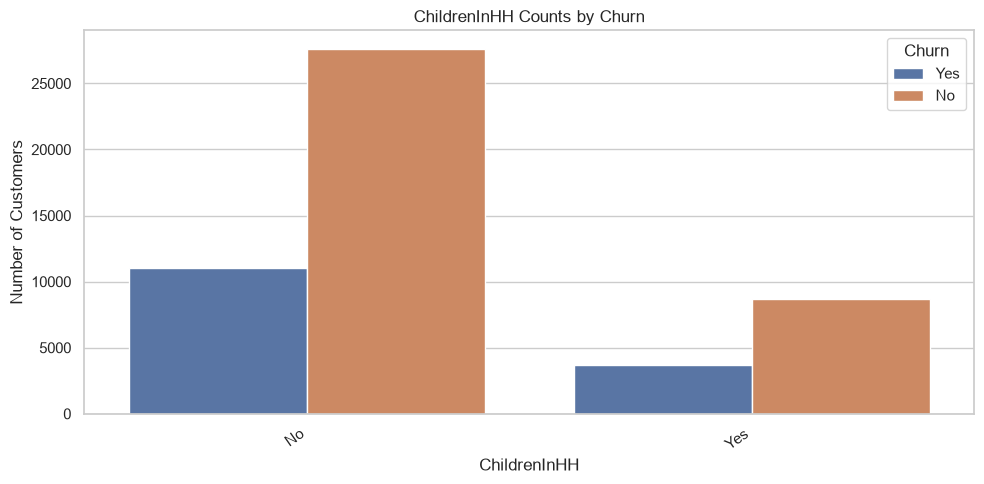

In [87]:
# Step 5: Compare ChildrenInHH Counts by Churn
category_order = clean_train['ChildrenInHH'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='ChildrenInHH', hue="Churn", order=category_order)
plt.title('ChildrenInHH Counts by Churn')
plt.xlabel('ChildrenInHH')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

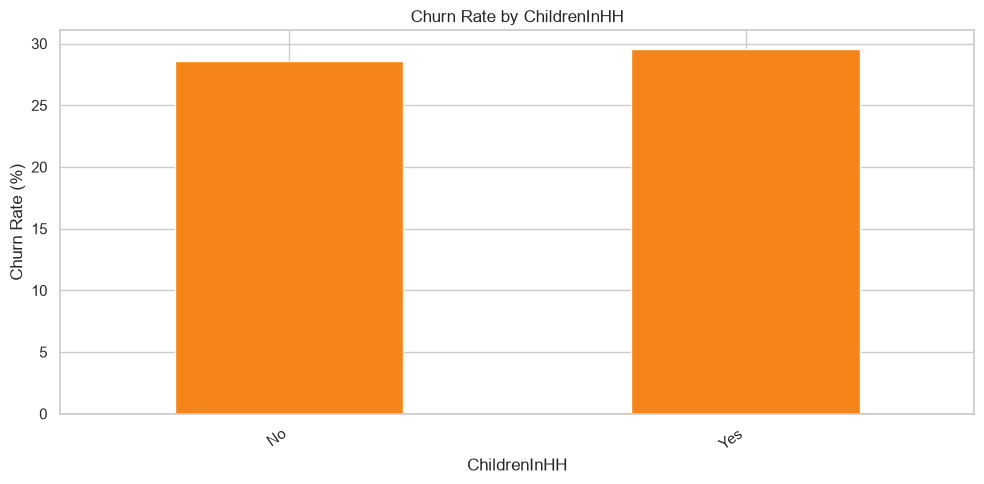

In [88]:
# Step 5: Compare Churn Rates by ChildrenInHH
category_churn_rate = clean_train.groupby('ChildrenInHH', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by ChildrenInHH')
plt.xlabel('ChildrenInHH')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

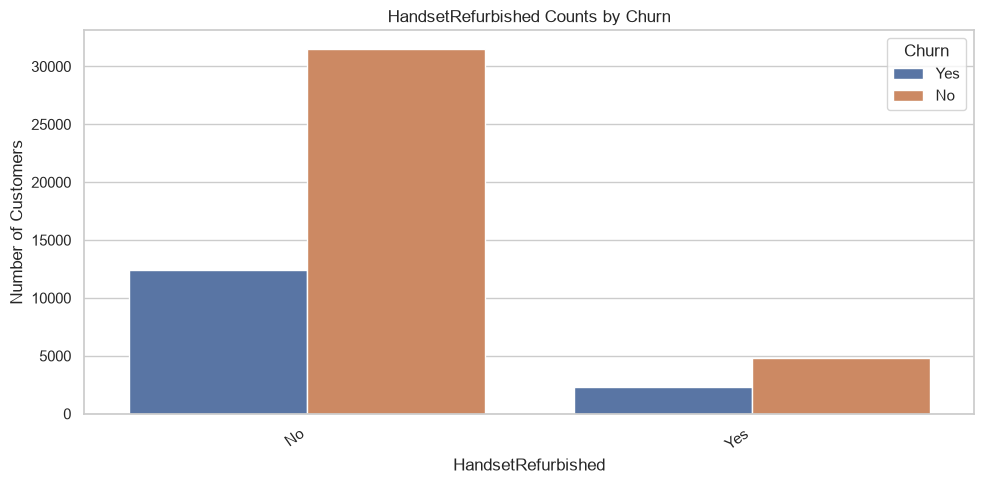

In [89]:
# Step 5: Compare HandsetRefurbished Counts by Churn
category_order = clean_train['HandsetRefurbished'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='HandsetRefurbished', hue="Churn", order=category_order)
plt.title('HandsetRefurbished Counts by Churn')
plt.xlabel('HandsetRefurbished')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

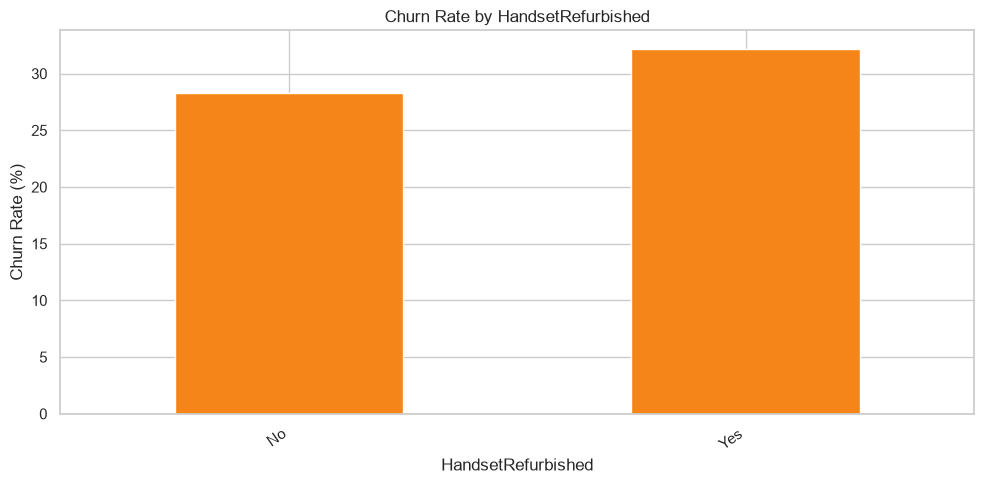

In [90]:
# Step 5: Compare Churn Rates by HandsetRefurbished
category_churn_rate = clean_train.groupby('HandsetRefurbished', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by HandsetRefurbished')
plt.xlabel('HandsetRefurbished')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

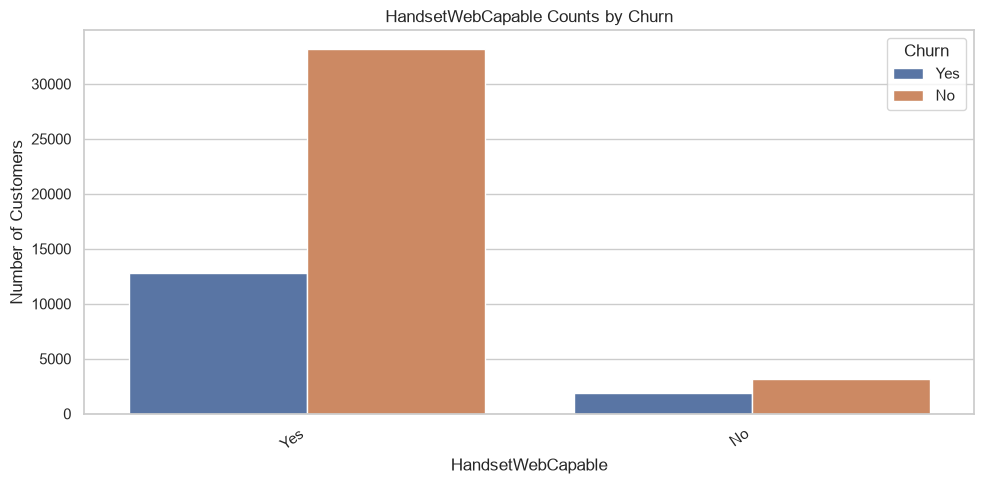

In [91]:
# Step 5: Compare HandsetWebCapable Counts by Churn
category_order = clean_train['HandsetWebCapable'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='HandsetWebCapable', hue="Churn", order=category_order)
plt.title('HandsetWebCapable Counts by Churn')
plt.xlabel('HandsetWebCapable')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

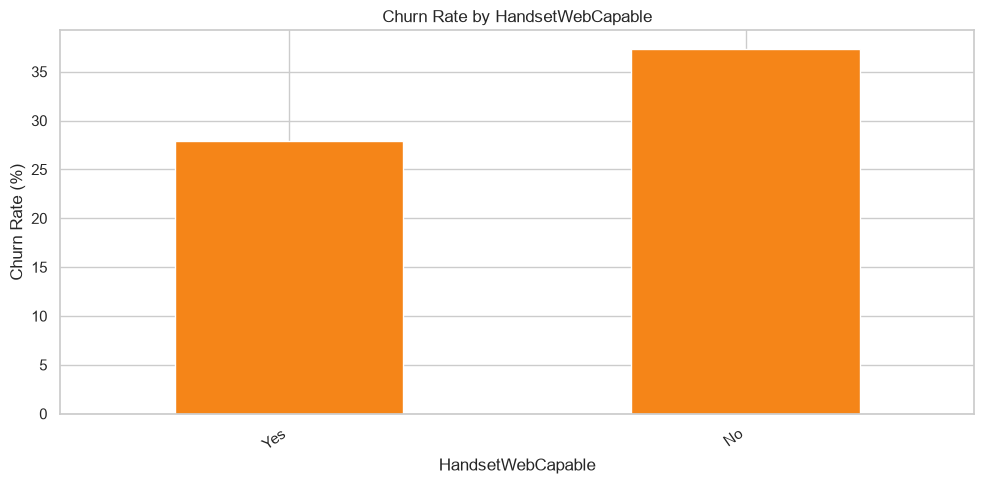

In [92]:
# Step 5: Compare Churn Rates by HandsetWebCapable
category_churn_rate = clean_train.groupby('HandsetWebCapable', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by HandsetWebCapable')
plt.xlabel('HandsetWebCapable')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

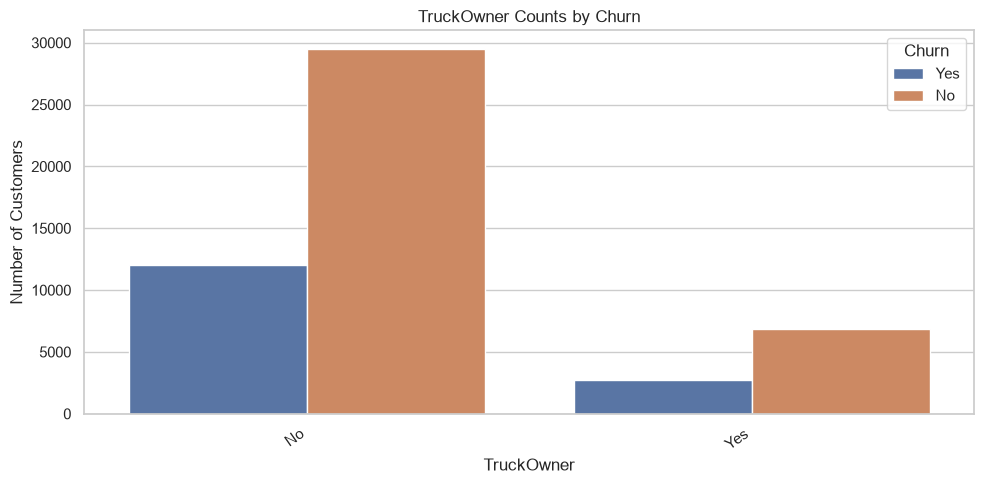

In [93]:
# Step 5: Compare TruckOwner Counts by Churn
category_order = clean_train['TruckOwner'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='TruckOwner', hue="Churn", order=category_order)
plt.title('TruckOwner Counts by Churn')
plt.xlabel('TruckOwner')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

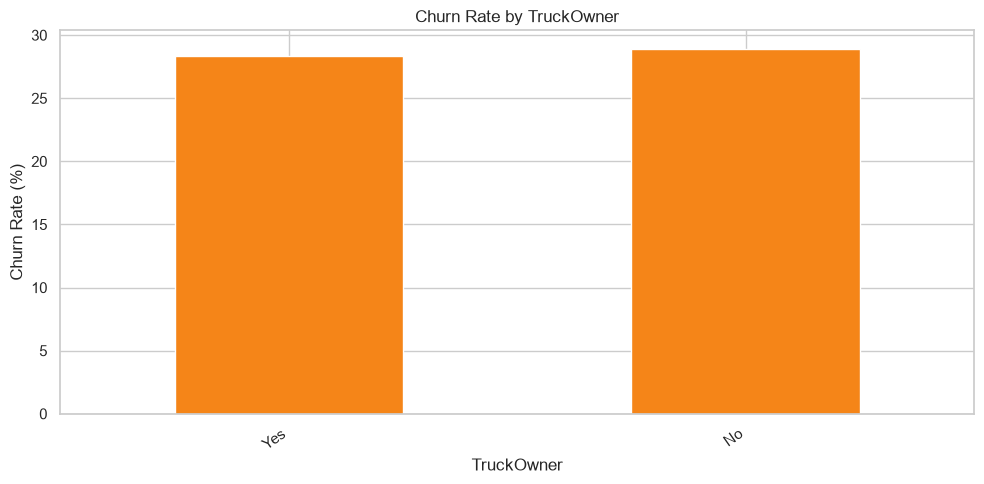

In [94]:
# Step 5: Compare Churn Rates by TruckOwner
category_churn_rate = clean_train.groupby('TruckOwner', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by TruckOwner')
plt.xlabel('TruckOwner')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

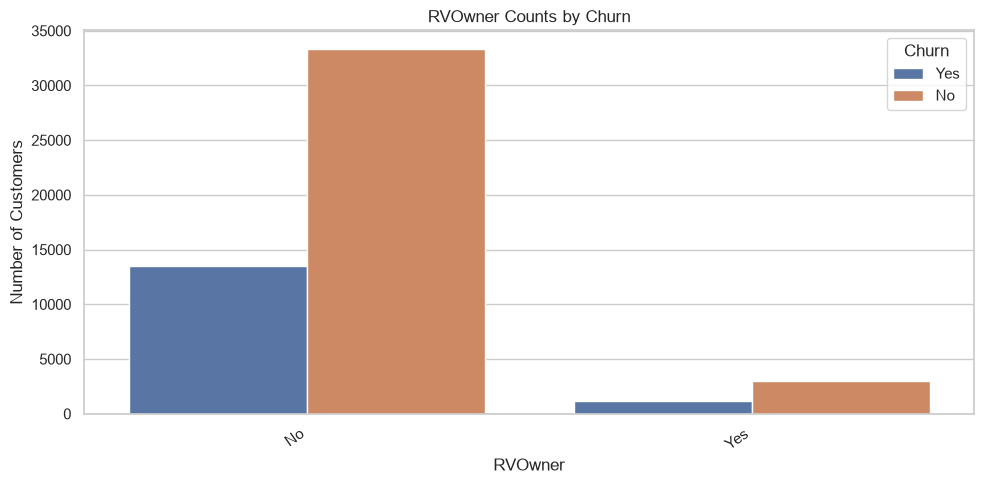

In [95]:
# Step 5: Compare RVOwner Counts by Churn
category_order = clean_train['RVOwner'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='RVOwner', hue="Churn", order=category_order)
plt.title('RVOwner Counts by Churn')
plt.xlabel('RVOwner')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

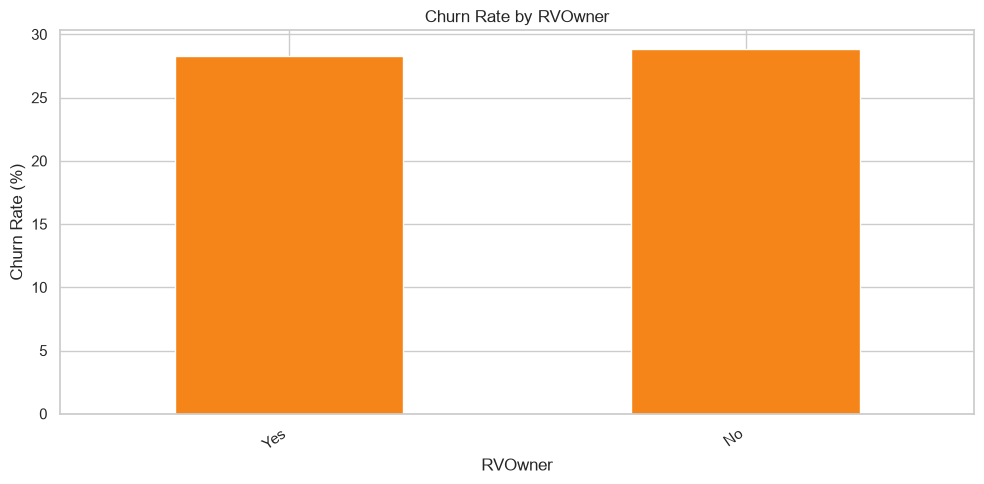

In [96]:
# Step 5: Compare Churn Rates by RVOwner
category_churn_rate = clean_train.groupby('RVOwner', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by RVOwner')
plt.xlabel('RVOwner')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

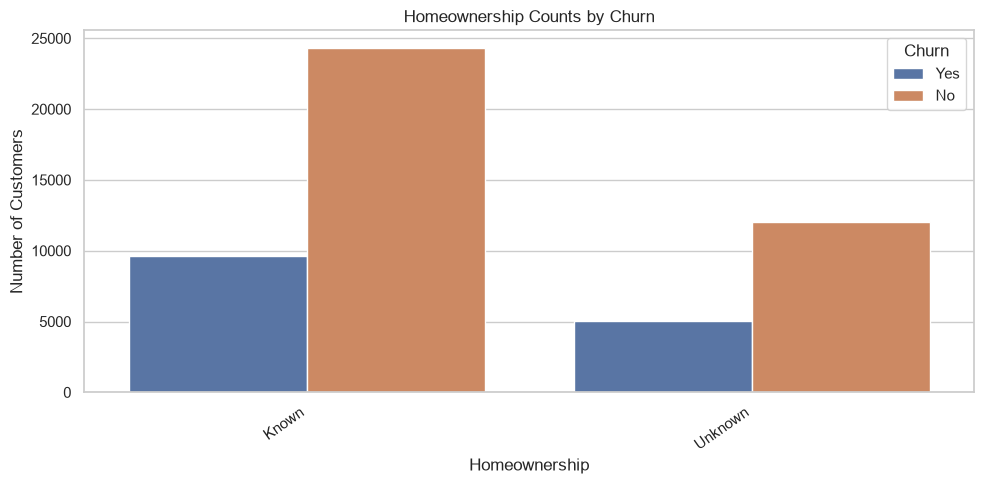

In [97]:
# Step 5: Compare Homeownership Counts by Churn
category_order = clean_train['Homeownership'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='Homeownership', hue="Churn", order=category_order)
plt.title('Homeownership Counts by Churn')
plt.xlabel('Homeownership')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

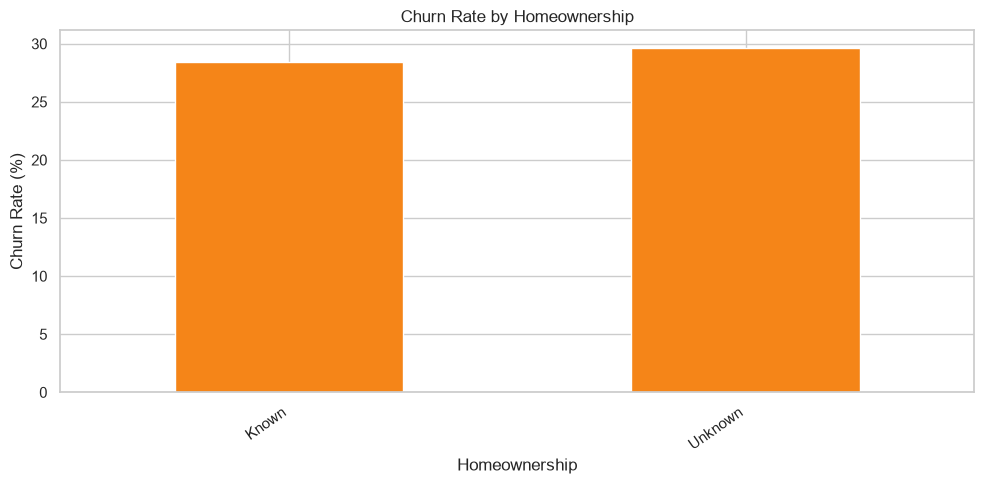

In [98]:
# Step 5: Compare Churn Rates by Homeownership
category_churn_rate = clean_train.groupby('Homeownership', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by Homeownership')
plt.xlabel('Homeownership')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

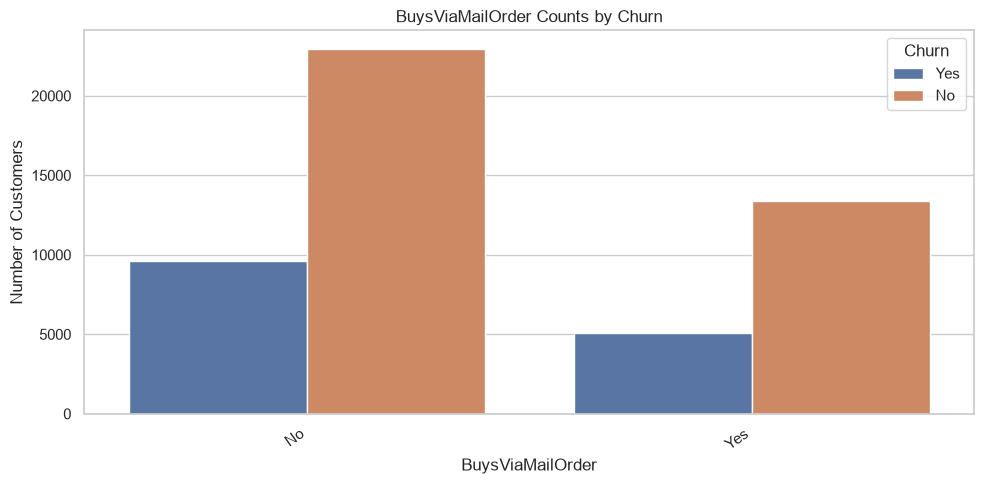

In [99]:
# Step 5: Compare BuysViaMailOrder Counts by Churn
category_order = clean_train['BuysViaMailOrder'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='BuysViaMailOrder', hue="Churn", order=category_order)
plt.title('BuysViaMailOrder Counts by Churn')
plt.xlabel('BuysViaMailOrder')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

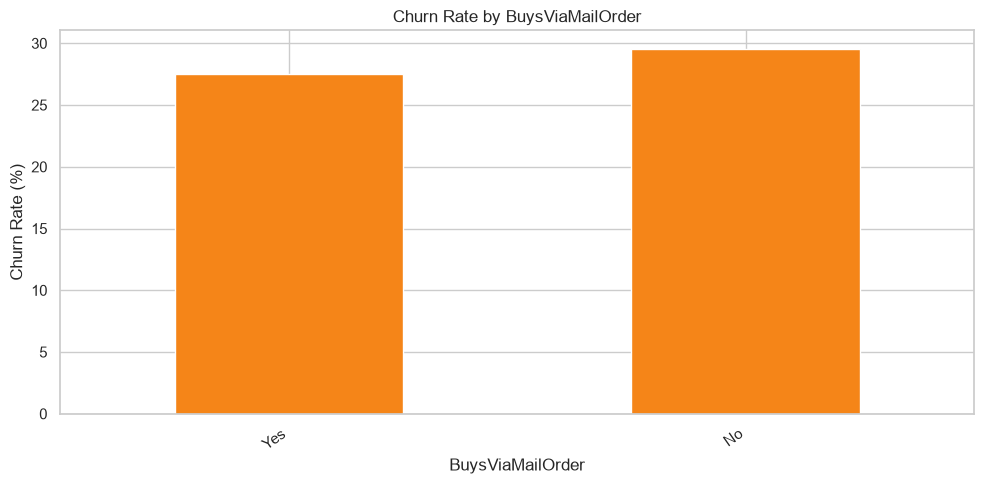

In [100]:
# Step 5: Compare Churn Rates by BuysViaMailOrder
category_churn_rate = clean_train.groupby('BuysViaMailOrder', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by BuysViaMailOrder')
plt.xlabel('BuysViaMailOrder')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

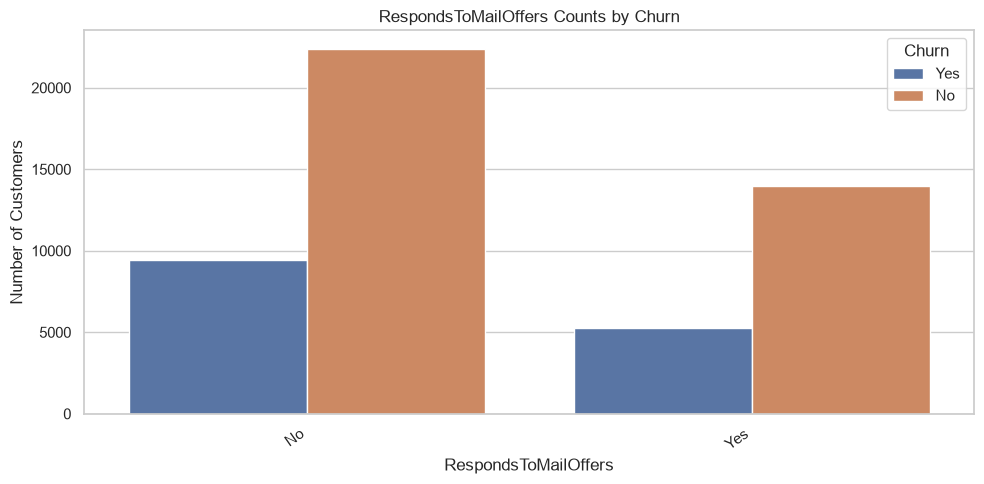

In [101]:
# Step 5: Compare RespondsToMailOffers Counts by Churn
category_order = clean_train['RespondsToMailOffers'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='RespondsToMailOffers', hue="Churn", order=category_order)
plt.title('RespondsToMailOffers Counts by Churn')
plt.xlabel('RespondsToMailOffers')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

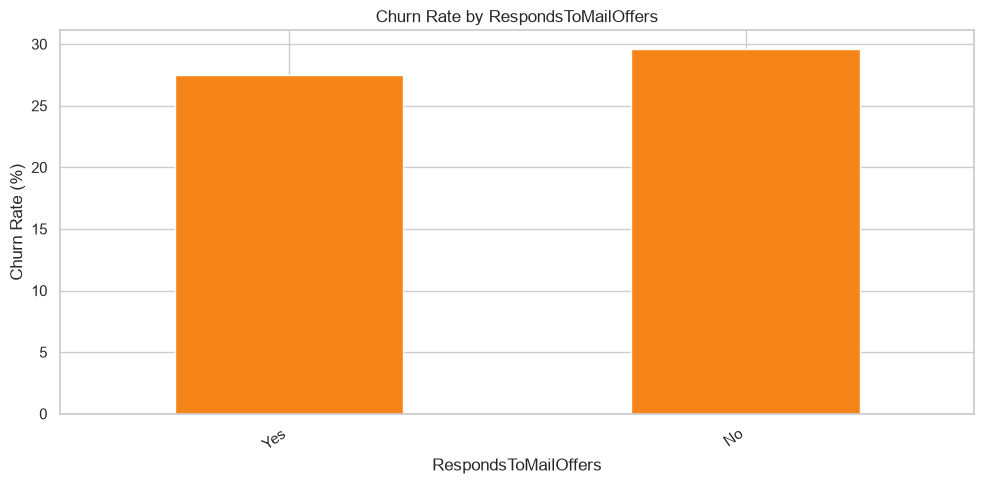

In [102]:
# Step 5: Compare Churn Rates by RespondsToMailOffers
category_churn_rate = clean_train.groupby('RespondsToMailOffers', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by RespondsToMailOffers')
plt.xlabel('RespondsToMailOffers')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

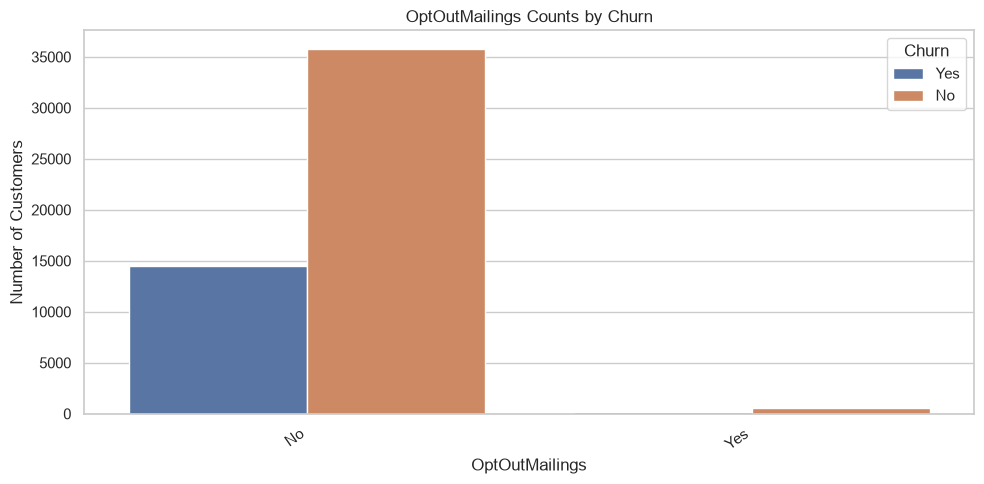

In [103]:
# Step 5: Compare OptOutMailings Counts by Churn
category_order = clean_train['OptOutMailings'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='OptOutMailings', hue="Churn", order=category_order)
plt.title('OptOutMailings Counts by Churn')
plt.xlabel('OptOutMailings')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

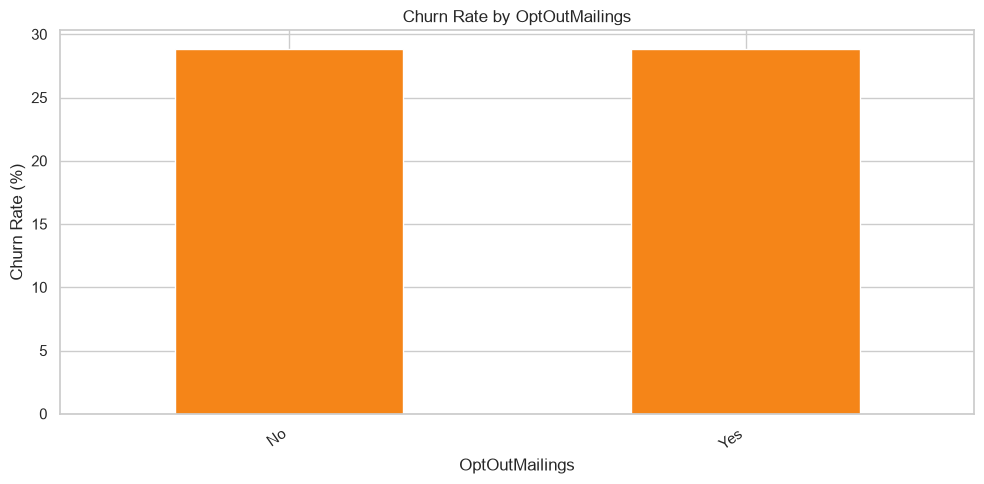

In [104]:
# Step 5: Compare Churn Rates by OptOutMailings
category_churn_rate = clean_train.groupby('OptOutMailings', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by OptOutMailings')
plt.xlabel('OptOutMailings')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

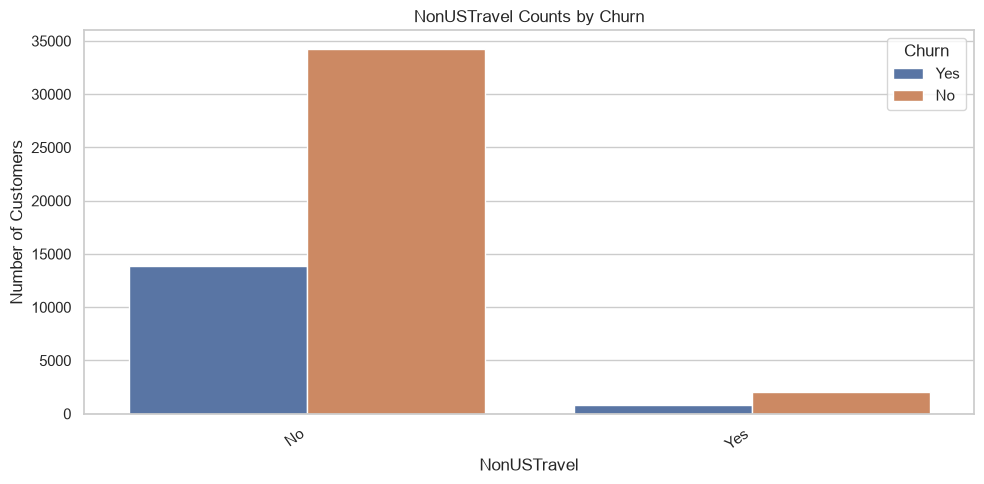

In [105]:
# Step 5: Compare NonUSTravel Counts by Churn
category_order = clean_train['NonUSTravel'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='NonUSTravel', hue="Churn", order=category_order)
plt.title('NonUSTravel Counts by Churn')
plt.xlabel('NonUSTravel')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

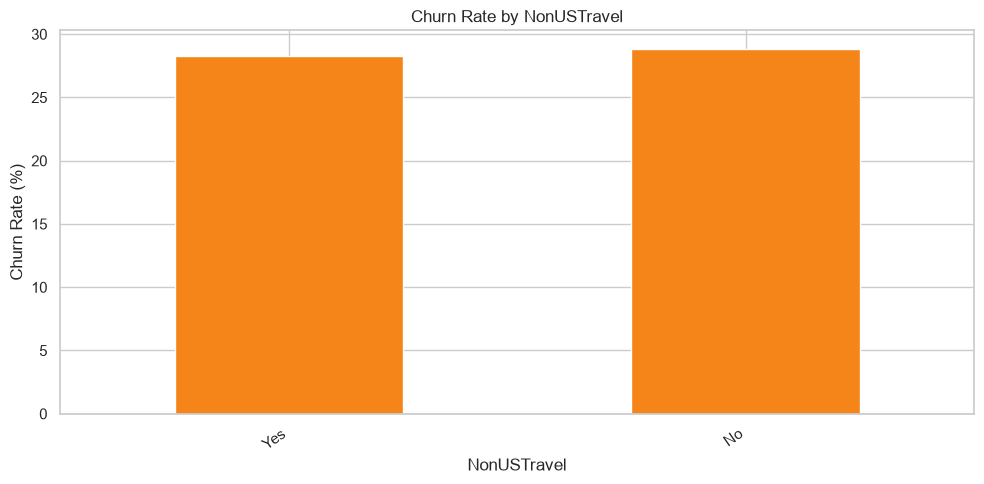

In [106]:
# Step 5: Compare Churn Rates by NonUSTravel
category_churn_rate = clean_train.groupby('NonUSTravel', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by NonUSTravel')
plt.xlabel('NonUSTravel')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

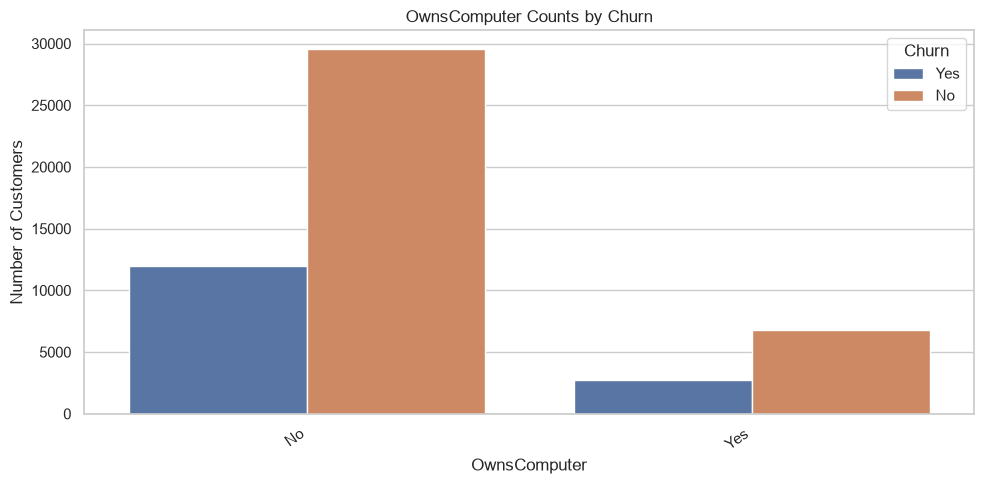

In [107]:
# Step 5: Compare OwnsComputer Counts by Churn
category_order = clean_train['OwnsComputer'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='OwnsComputer', hue="Churn", order=category_order)
plt.title('OwnsComputer Counts by Churn')
plt.xlabel('OwnsComputer')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

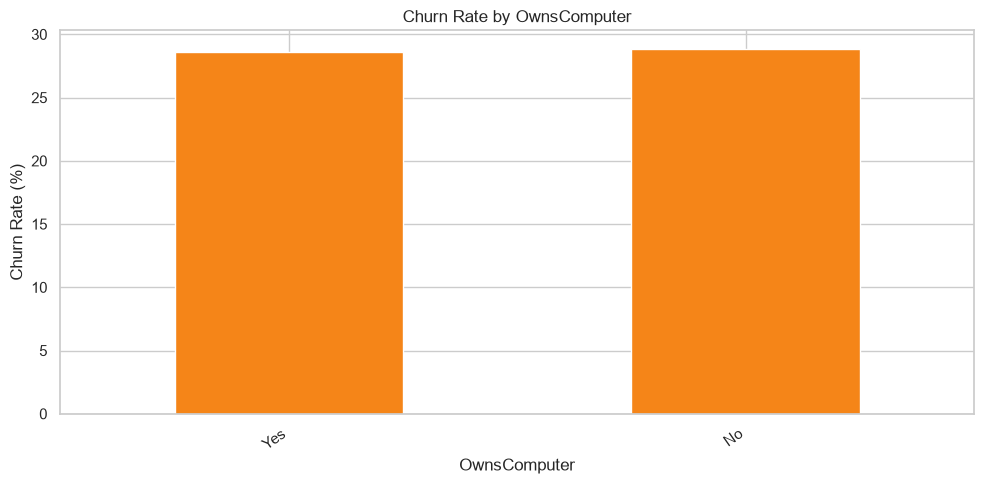

In [108]:
# Step 5: Compare Churn Rates by OwnsComputer
category_churn_rate = clean_train.groupby('OwnsComputer', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by OwnsComputer')
plt.xlabel('OwnsComputer')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

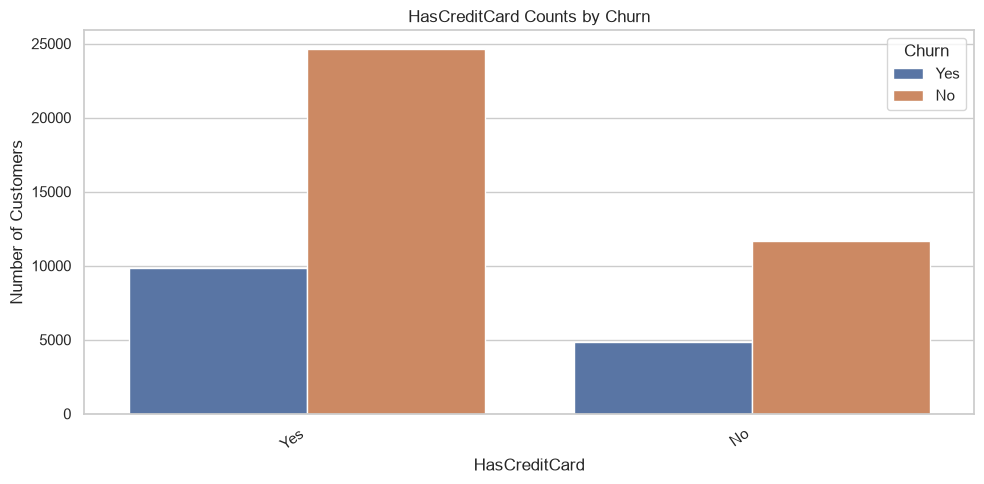

In [109]:
# Step 5: Compare HasCreditCard Counts by Churn
category_order = clean_train['HasCreditCard'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='HasCreditCard', hue="Churn", order=category_order)
plt.title('HasCreditCard Counts by Churn')
plt.xlabel('HasCreditCard')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

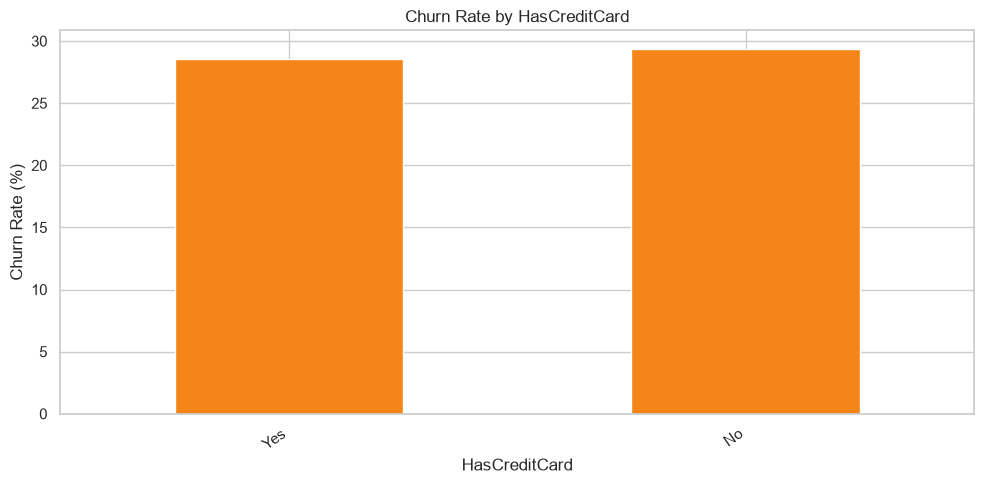

In [110]:
# Step 5: Compare Churn Rates by HasCreditCard
category_churn_rate = clean_train.groupby('HasCreditCard', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by HasCreditCard')
plt.xlabel('HasCreditCard')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

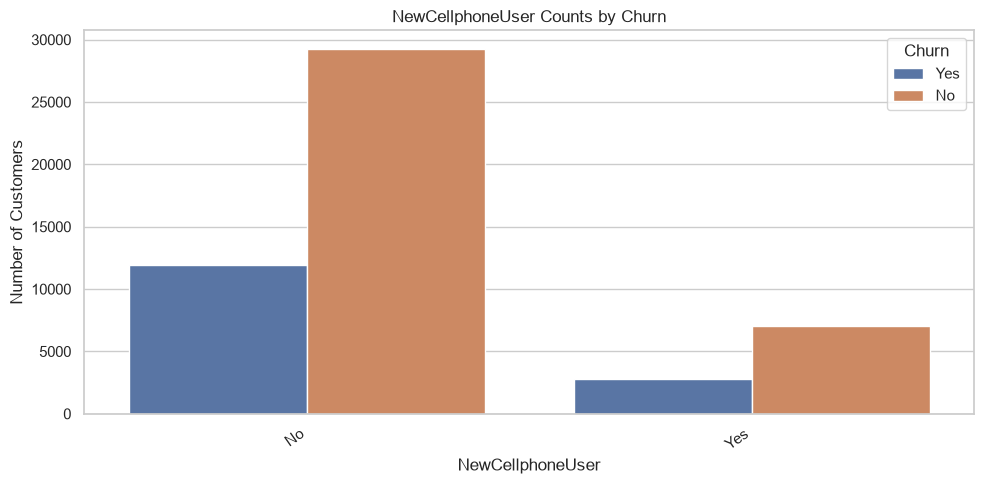

In [111]:
# Step 5: Compare NewCellphoneUser Counts by Churn
category_order = clean_train['NewCellphoneUser'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='NewCellphoneUser', hue="Churn", order=category_order)
plt.title('NewCellphoneUser Counts by Churn')
plt.xlabel('NewCellphoneUser')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

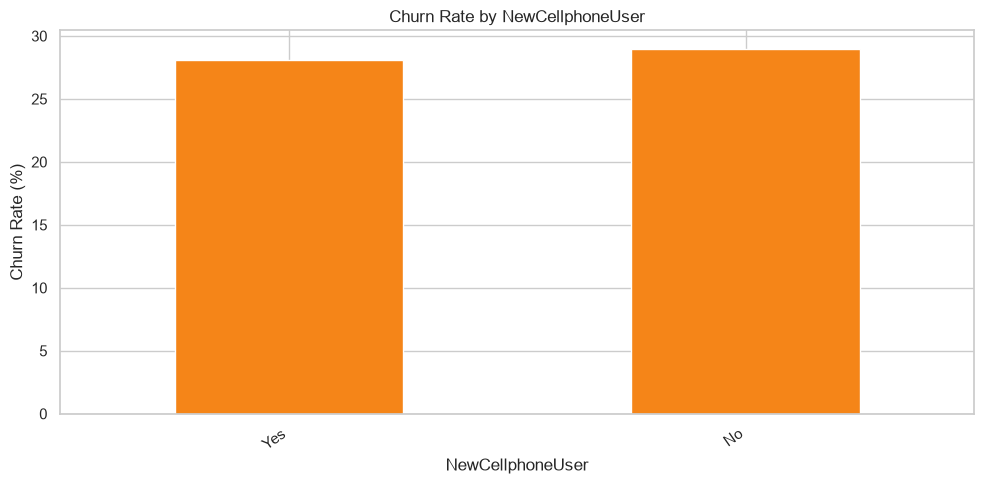

In [112]:
# Step 5: Compare Churn Rates by NewCellphoneUser
category_churn_rate = clean_train.groupby('NewCellphoneUser', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by NewCellphoneUser')
plt.xlabel('NewCellphoneUser')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

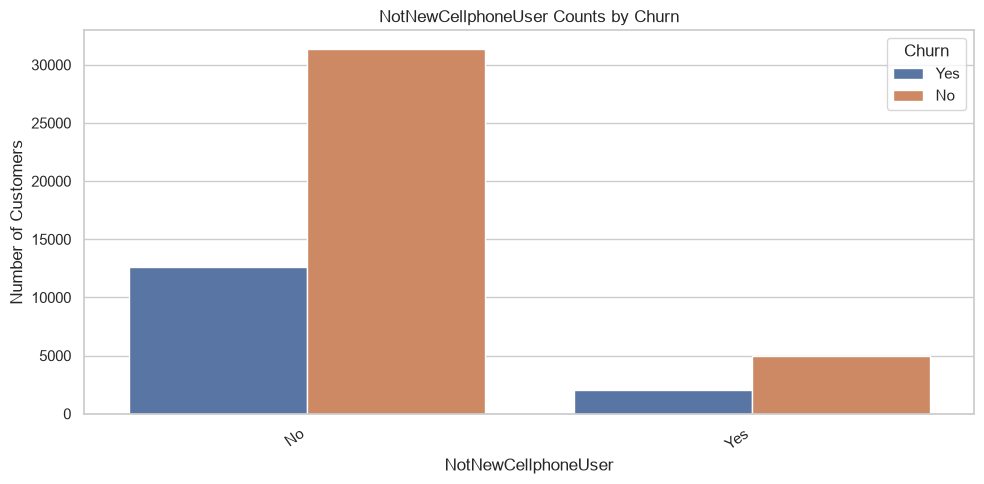

In [113]:
# Step 5: Compare NotNewCellphoneUser Counts by Churn
category_order = clean_train['NotNewCellphoneUser'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='NotNewCellphoneUser', hue="Churn", order=category_order)
plt.title('NotNewCellphoneUser Counts by Churn')
plt.xlabel('NotNewCellphoneUser')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

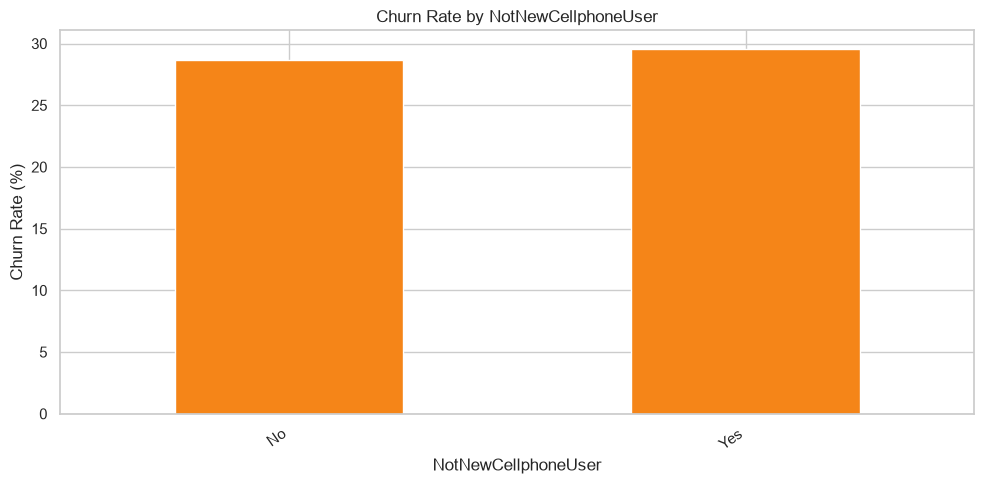

In [114]:
# Step 5: Compare Churn Rates by NotNewCellphoneUser
category_churn_rate = clean_train.groupby('NotNewCellphoneUser', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by NotNewCellphoneUser')
plt.xlabel('NotNewCellphoneUser')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

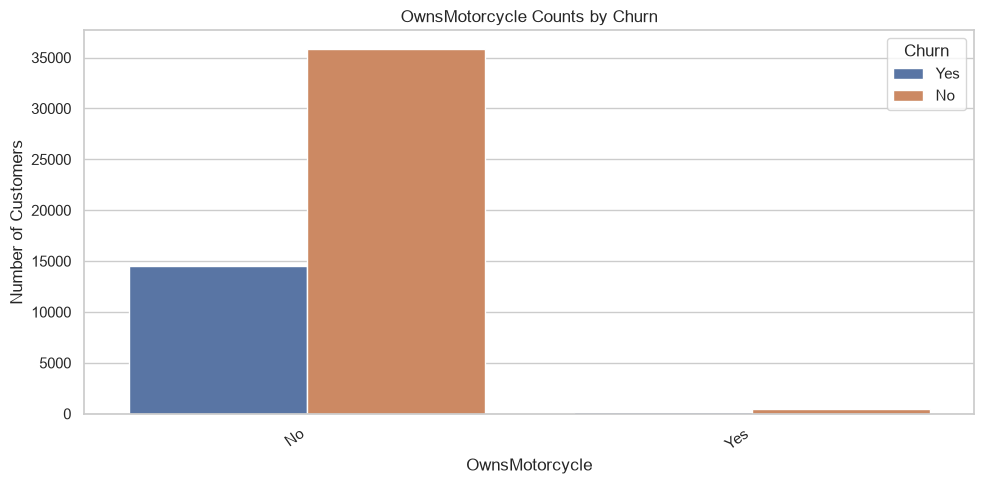

In [115]:
# Step 5: Compare OwnsMotorcycle Counts by Churn
category_order = clean_train['OwnsMotorcycle'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='OwnsMotorcycle', hue="Churn", order=category_order)
plt.title('OwnsMotorcycle Counts by Churn')
plt.xlabel('OwnsMotorcycle')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

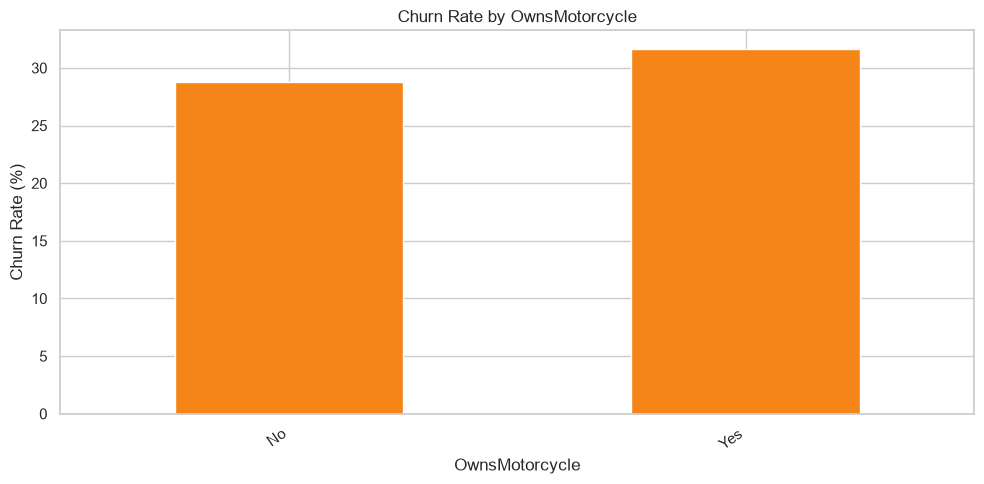

In [116]:
# Step 5: Compare Churn Rates by OwnsMotorcycle
category_churn_rate = clean_train.groupby('OwnsMotorcycle', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by OwnsMotorcycle')
plt.xlabel('OwnsMotorcycle')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

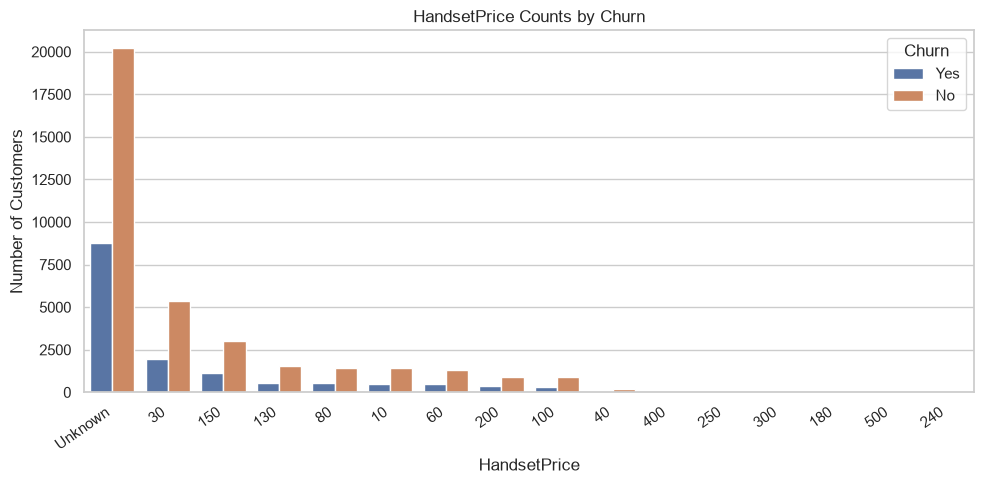

In [117]:
# Step 5: Compare HandsetPrice Counts by Churn
category_order = clean_train['HandsetPrice'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='HandsetPrice', hue="Churn", order=category_order)
plt.title('HandsetPrice Counts by Churn')
plt.xlabel('HandsetPrice')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

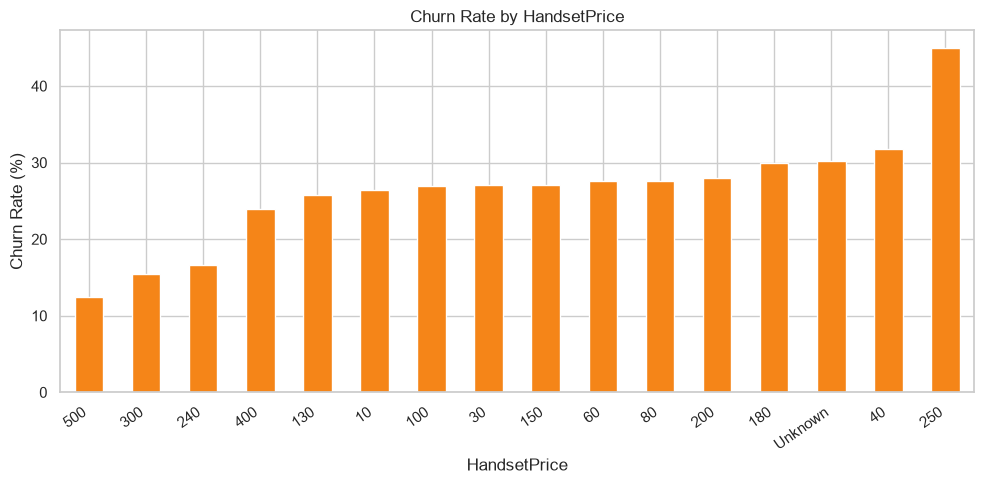

In [118]:
# Step 5: Compare Churn Rates by HandsetPrice
category_churn_rate = clean_train.groupby('HandsetPrice', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by HandsetPrice')
plt.xlabel('HandsetPrice')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

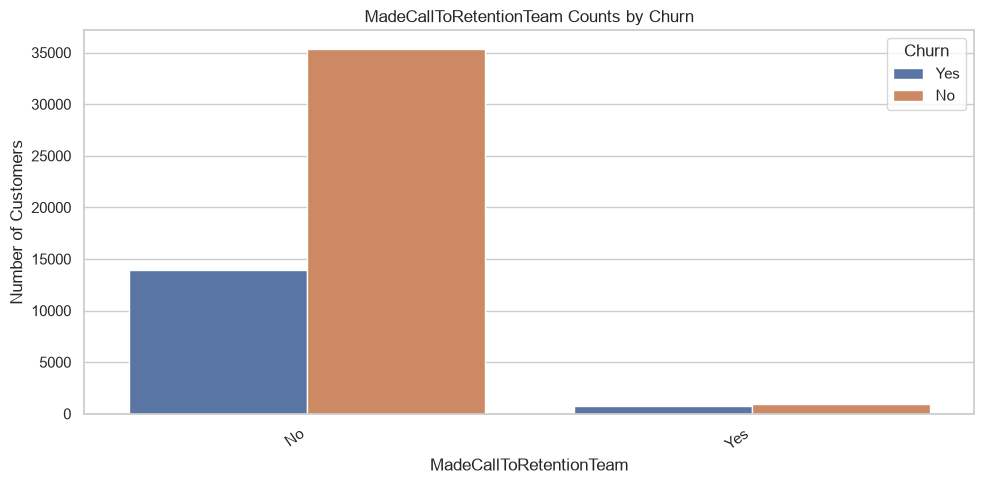

In [119]:
# Step 5: Compare MadeCallToRetentionTeam Counts by Churn
category_order = clean_train['MadeCallToRetentionTeam'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='MadeCallToRetentionTeam', hue="Churn", order=category_order)
plt.title('MadeCallToRetentionTeam Counts by Churn')
plt.xlabel('MadeCallToRetentionTeam')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

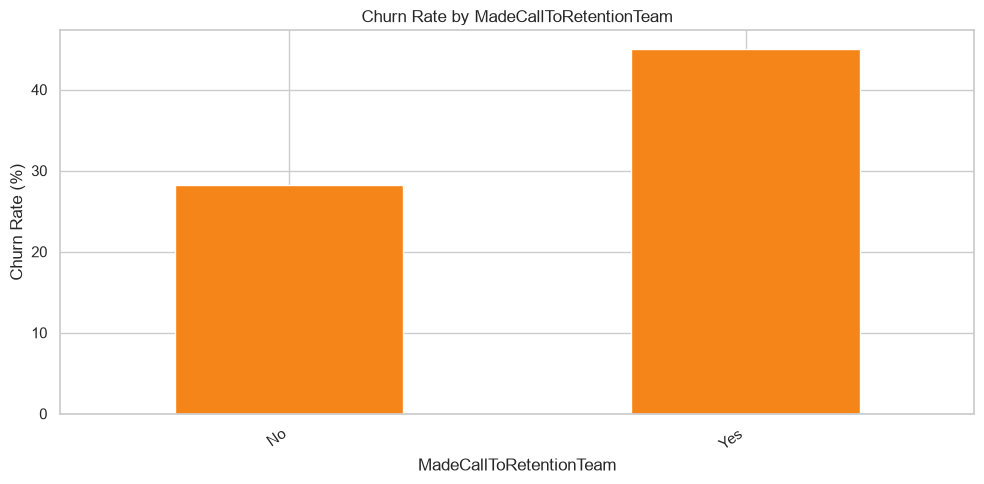

In [120]:
# Step 5: Compare Churn Rates by MadeCallToRetentionTeam
category_churn_rate = clean_train.groupby('MadeCallToRetentionTeam', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by MadeCallToRetentionTeam')
plt.xlabel('MadeCallToRetentionTeam')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

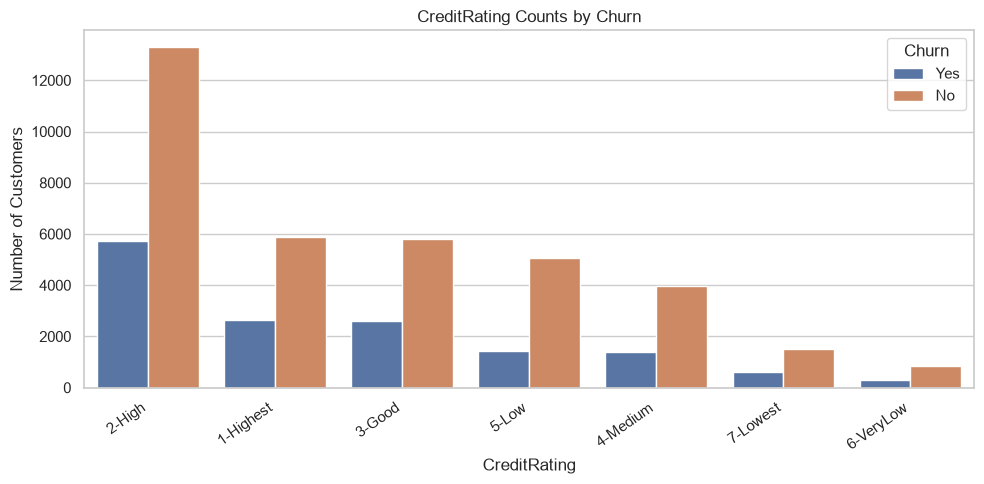

In [121]:
# Step 5: Compare CreditRating Counts by Churn
category_order = clean_train['CreditRating'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='CreditRating', hue="Churn", order=category_order)
plt.title('CreditRating Counts by Churn')
plt.xlabel('CreditRating')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

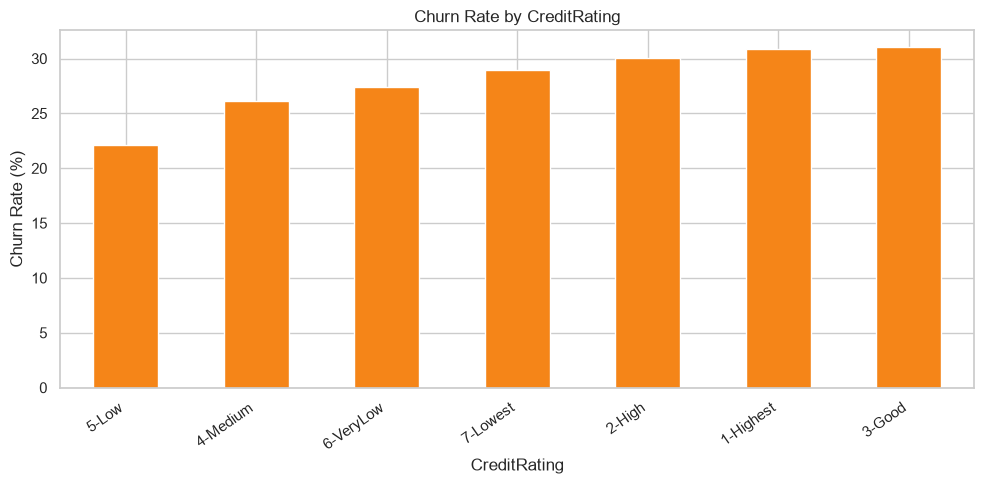

In [122]:
# Step 5: Compare Churn Rates by CreditRating
category_churn_rate = clean_train.groupby('CreditRating', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by CreditRating')
plt.xlabel('CreditRating')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

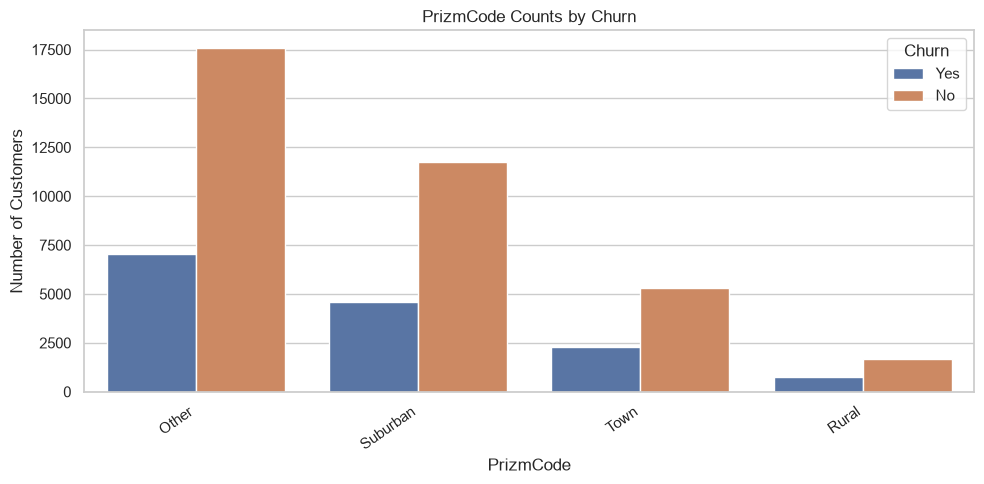

In [123]:
# Step 5: Compare PrizmCode Counts by Churn
category_order = clean_train['PrizmCode'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='PrizmCode', hue="Churn", order=category_order)
plt.title('PrizmCode Counts by Churn')
plt.xlabel('PrizmCode')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

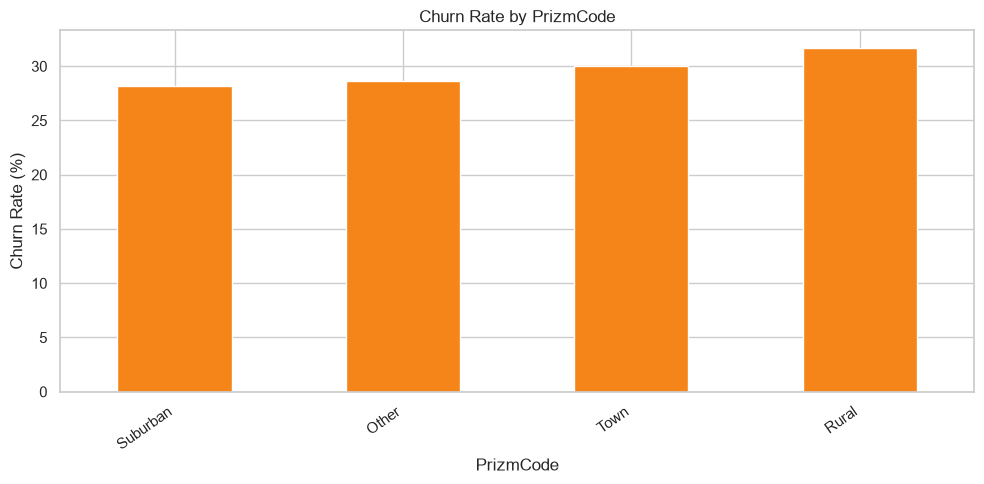

In [124]:
# Step 5: Compare Churn Rates by PrizmCode
category_churn_rate = clean_train.groupby('PrizmCode', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by PrizmCode')
plt.xlabel('PrizmCode')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

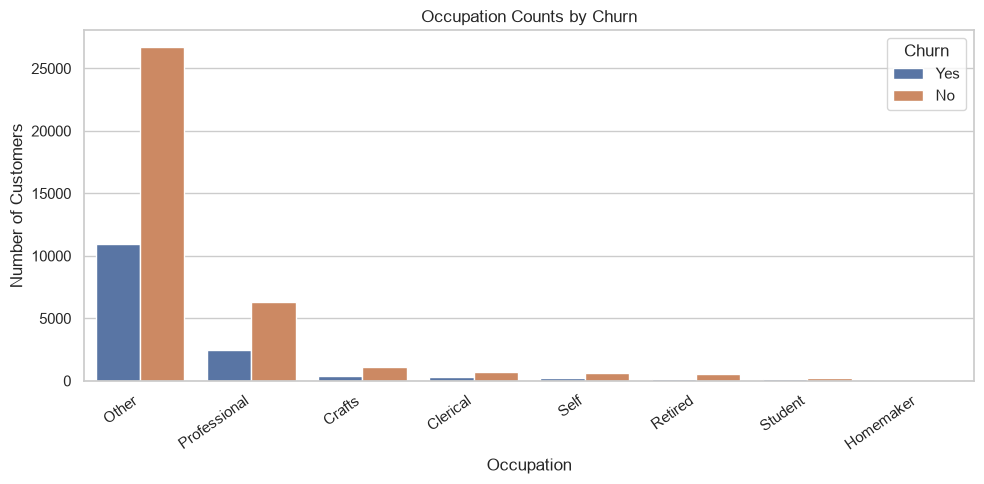

In [125]:
# Step 5: Compare Occupation Counts by Churn
category_order = clean_train['Occupation'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='Occupation', hue="Churn", order=category_order)
plt.title('Occupation Counts by Churn')
plt.xlabel('Occupation')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

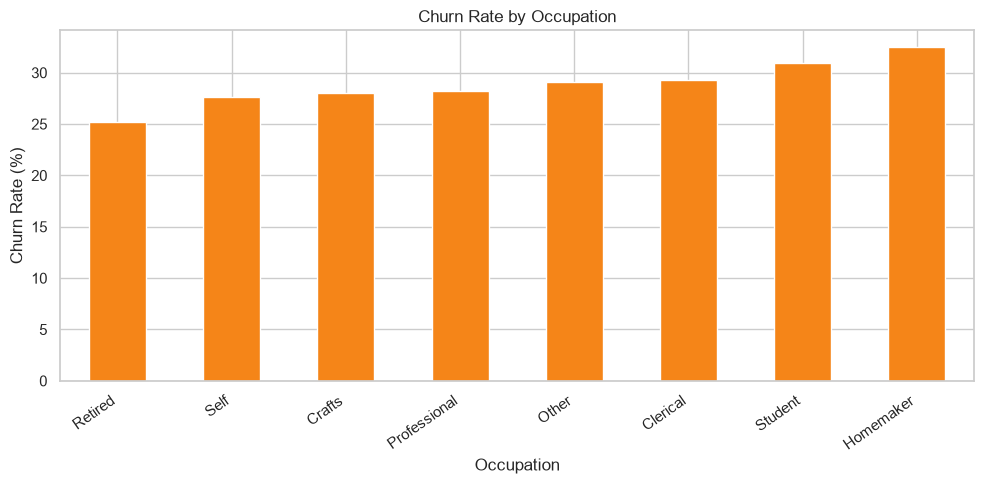

In [126]:
# Step 5: Compare Churn Rates by Occupation
category_churn_rate = clean_train.groupby('Occupation', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by Occupation')
plt.xlabel('Occupation')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

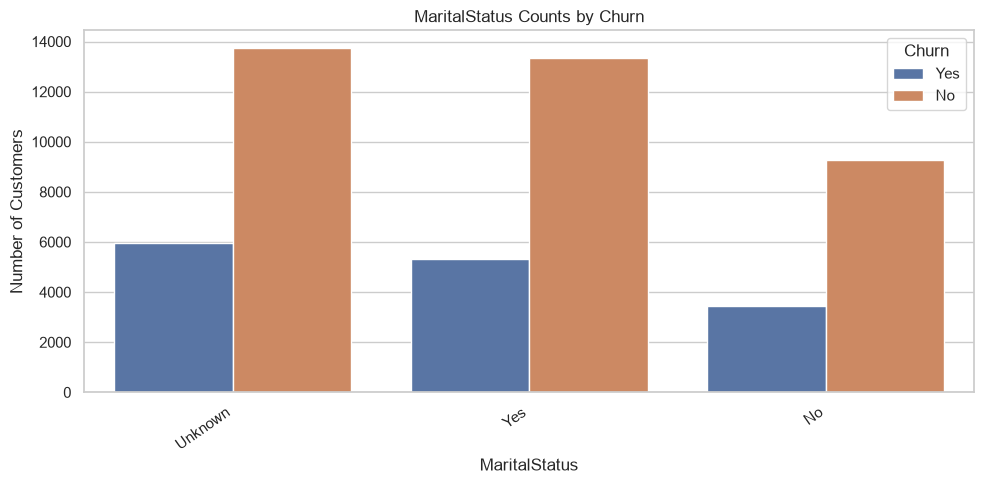

In [127]:
# Step 5: Compare MaritalStatus Counts by Churn
category_order = clean_train['MaritalStatus'].value_counts().index
plt.figure(figsize=(10, 5))
sns.countplot(data=clean_train, x='MaritalStatus', hue="Churn", order=category_order)
plt.title('MaritalStatus Counts by Churn')
plt.xlabel('MaritalStatus')
plt.ylabel("Number of Customers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

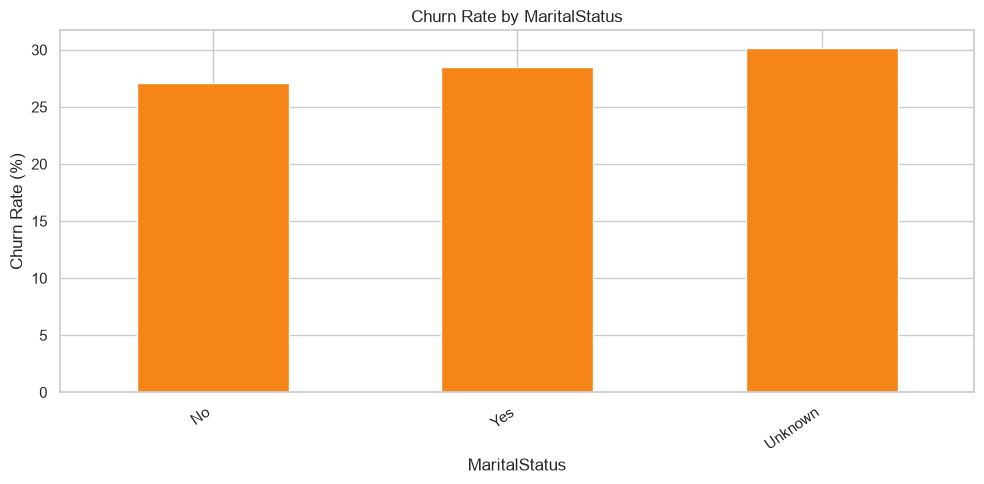

In [128]:
# Step 5: Compare Churn Rates by MaritalStatus
category_churn_rate = clean_train.groupby('MaritalStatus', dropna=False, observed=True)["Churn"].apply(
    lambda values: values.eq("Yes").mean() * 100
).sort_values()
plt.figure(figsize=(10, 5))
category_churn_rate.plot(kind="bar", color="#F58518")
plt.title('Churn Rate by MaritalStatus')
plt.xlabel('MaritalStatus')
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [129]:
# Step 5: Calculate Numeric Feature Correlations
numeric_correlations = clean_train[eda_numeric_features].corr()
numeric_correlations.head()

,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,DroppedCalls,BlockedCalls,...,Handsets,HandsetModels,CurrentEquipmentDays,AgeHH1,AgeHH2,RetentionCalls,RetentionOffersAccepted,ReferralsMadeBySubscriber,IncomeGroup,AdjustmentsToCreditRating
MonthlyRevenue,1.000000,0.712912,0.629838,0.407252,0.787834,0.303581,-0.027399,-0.016547,0.430426,0.231992,...,0.243333,0.236318,-0.217887,-0.108160,-0.105379,0.011405,0.015509,0.018848,-0.081701,0.034453
MonthlyMinutes,0.712912,1.000000,0.584030,0.392215,0.571437,0.112624,-0.045151,-0.040726,0.593881,0.317812,...,0.302872,0.292816,-0.310949,-0.163206,-0.142859,0.009874,0.015000,0.067360,-0.144560,0.045545
TotalRecurringCharge,0.629838,0.584030,1.000000,0.311052,0.202908,0.073740,-0.016084,-0.025497,0.352852,0.178843,...,0.234399,0.225654,-0.249098,-0.105305,-0.100373,-0.022073,-0.002288,0.036694,-0.077136,0.043630
DirectorAssistedCalls,0.407252,0.392215,0.311052,1.000000,0.287128,0.069990,-0.026047,-0.016009,0.263693,0.139692,...,0.185223,0.172646,-0.121433,-0.058719,-0.057438,0.008776,0.013430,-0.001197,-0.017404,0.022697
OverageMinutes,0.787834,0.571437,0.202908,0.287128,1.000000,0.063954,-0.028417,-0.018631,0.332012,0.190198,...,0.143397,0.143874,-0.123869,-0.064919,-0.062053,0.015227,0.009416,0.009935,-0.050045,0.020785


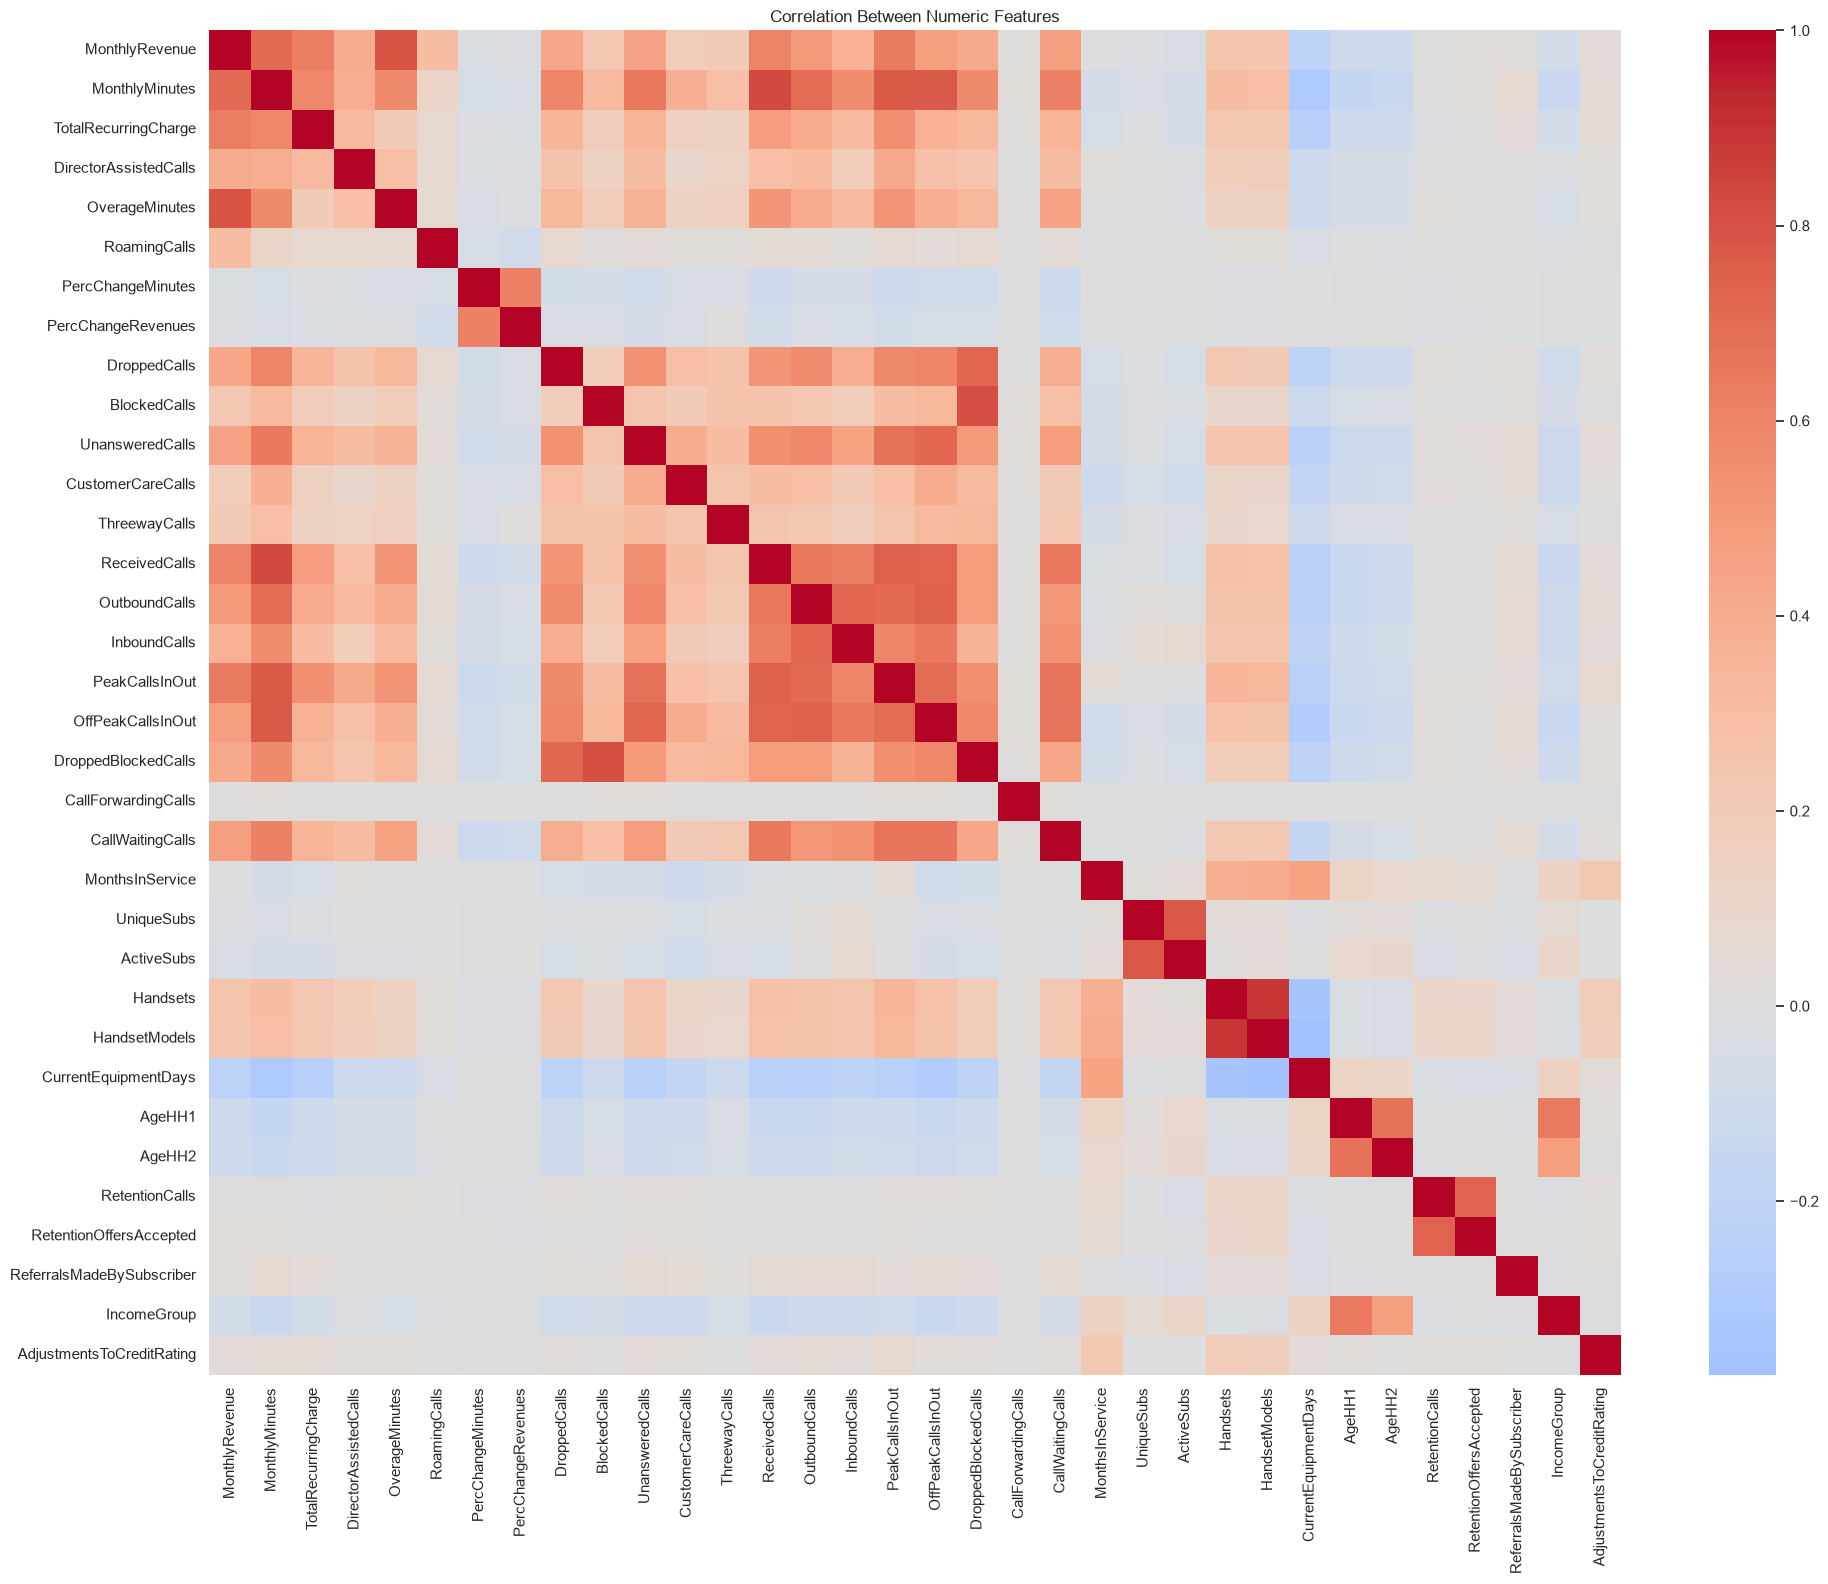

In [130]:
# Step 5: Plot Correlations Between Numeric Features
plt.figure(figsize=(20, 16))
sns.heatmap(numeric_correlations, cmap="coolwarm", center=0)
plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

In [131]:
# Step 5: Find Numeric Features Most Related to Churn
correlation_data = clean_train[eda_numeric_features].copy()
correlation_data["ChurnBinary"] = clean_train["Churn"].map({"No": 0, "Yes": 1})
churn_correlations = correlation_data.corr()["ChurnBinary"].drop("ChurnBinary")
churn_correlations = churn_correlations.reindex(churn_correlations.abs().sort_values(ascending=False).index)
print(churn_correlations.head(10).round(3))

CurrentEquipmentDays       0.104
RetentionCalls             0.065
TotalRecurringCharge      -0.061
MonthlyMinutes            -0.050
OffPeakCallsInOut         -0.041
HandsetModels             -0.040
PeakCallsInOut            -0.040
ReceivedCalls             -0.037
CustomerCareCalls         -0.036
RetentionOffersAccepted    0.035
Name: ChurnBinary, dtype: float64


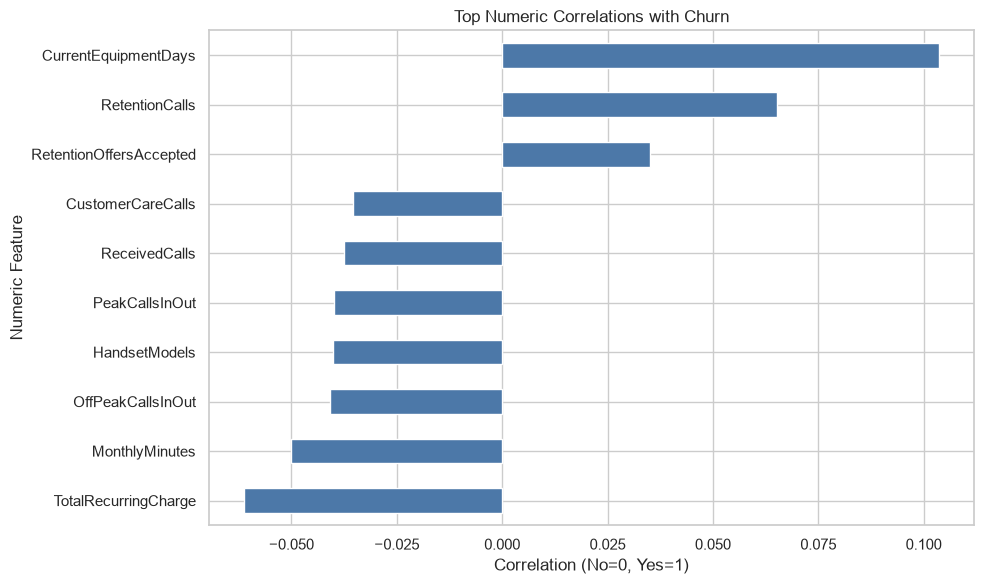

In [132]:
# Step 5: Plot Numeric Features Most Related to Churn
plt.figure(figsize=(10, 6))
churn_correlations.head(10).sort_values().plot(kind="barh", color="#4C78A8")
plt.title("Top Numeric Correlations with Churn")
plt.xlabel("Correlation (No=0, Yes=1)")
plt.ylabel("Numeric Feature")
plt.tight_layout()
plt.show()

In [133]:
# Step 6: Prepare Features

In [134]:
target_map = {"No": 0, "Yes": 1}
X = clean_train.drop(columns=["Churn", "CustomerID"], errors="ignore").copy()
y = clean_train["Churn"].map(target_map).astype("int8")
if "Churn" in X.columns or "CustomerID" in X.columns:
    raise AssertionError("Target leakage or identifier leakage detected in X.")

numeric_features = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c].dtype)]
categorical_features = [c for c in X.columns if c not in numeric_features]
if set(numeric_features).union(categorical_features) != set(X.columns):
    raise AssertionError("Every model feature must be assigned to exactly one preprocessing branch.")
print(f"Final modeling matrix before encoding: {X.shape}")
print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print(f"Target counts (0=No, 1=Yes): {y.value_counts().sort_index().to_dict()}")
print(f"Majority/minority ratio: {y.value_counts().max() / y.value_counts().min():.2f}:1")

Final modeling matrix before encoding: (51047, 56)
Numeric features (34): ['MonthlyRevenue', 'MonthlyMinutes', 'TotalRecurringCharge', 'DirectorAssistedCalls', 'OverageMinutes', 'RoamingCalls', 'PercChangeMinutes', 'PercChangeRevenues', 'DroppedCalls', 'BlockedCalls', 'UnansweredCalls', 'CustomerCareCalls', 'ThreewayCalls', 'ReceivedCalls', 'OutboundCalls', 'InboundCalls', 'PeakCallsInOut', 'OffPeakCallsInOut', 'DroppedBlockedCalls', 'CallForwardingCalls', 'CallWaitingCalls', 'MonthsInService', 'UniqueSubs', 'ActiveSubs', 'Handsets', 'HandsetModels', 'CurrentEquipmentDays', 'AgeHH1', 'AgeHH2', 'RetentionCalls', 'RetentionOffersAccepted', 'ReferralsMadeBySubscriber', 'IncomeGroup', 'AdjustmentsToCreditRating']
Categorical features (22): ['ServiceArea', 'ChildrenInHH', 'HandsetRefurbished', 'HandsetWebCapable', 'TruckOwner', 'RVOwner', 'Homeownership', 'BuysViaMailOrder', 'RespondsToMailOffers', 'OptOutMailings', 'NonUSTravel', 'OwnsComputer', 'HasCreditCard', 'NewCellphoneUser', 'NotNew

In [135]:
# Step 7: Split Data

In [136]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")
print("Training target proportions:", y_train.value_counts(normalize=True).sort_index().round(4).to_dict())
print("Test target proportions:", y_test.value_counts(normalize=True).sort_index().round(4).to_dict())

Training rows: 40,837; test rows: 10,210
Training target proportions: {0: 0.7118, 1: 0.2882}
Test target proportions: {0: 0.7119, 1: 0.2881}


In [137]:
# Step 8: Train Baseline Models

In [138]:
# Step 8: Create the Preprocessing Pipelines
def make_preprocessor(numeric_scaler):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", numeric_scaler),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20)),
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ])



In [139]:
# Step 8: Set Up the Baseline Classifiers
positive_weight = float((y_train == 0).sum() / (y_train == 1).sum())
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=250, max_depth=18, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=11, weights="distance", algorithm="brute", n_jobs=-1),
    "Naive Bayes (Complement)": ComplementNB(),
    "Support Vector Machine (linear, calibrated)": CalibratedClassifierCV(
        estimator=LinearSVC(class_weight="balanced", max_iter=5000, dual="auto", random_state=SEED),
        method="sigmoid", cv=3, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        objective="binary:logistic", eval_metric="logloss", n_estimators=250,
        max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=positive_weight, tree_method="hist", n_jobs=4,
        random_state=SEED,
    ),
}



In [140]:
# Step 8: Combine Preprocessing and Classifiers
pipelines = {}
for name, classifier in classifiers.items():
    scaler = MinMaxScaler() if name == "Naive Bayes (Complement)" else StandardScaler()
    pipelines[name] = Pipeline([
        ("preprocessor", make_preprocessor(scaler)),
        ("classifier", classifier),
    ])
print(f"Prepared {len(pipelines)} model Pipelines; positive-class weight for XGBoost: {positive_weight:.3f}")

Prepared 7 model Pipelines; positive-class weight for XGBoost: 2.470


In [141]:
metric_rows = []
confusion_matrices = {}
for name, pipeline in pipelines.items():
    print(f"Fitting {name}...")
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    metric_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    })
    confusion_matrices[name] = confusion_matrix(y_test, predictions, labels=[0, 1])

# Keep a neutral ordering; the test set is for reporting, not model selection.
metrics = pd.DataFrame(metric_rows).set_index("Model").sort_index()
print("Default-threshold comparison on the common held-out test split; not used to select the final model.")
display(metrics.style.format("{:.3f}"))

Fitting Logistic Regression...


Fitting Decision Tree...


Fitting Random Forest...


Fitting K-Nearest Neighbours...


Fitting Naive Bayes (Complement)...


Fitting Support Vector Machine (linear, calibrated)...


Fitting XGBoost...


Default-threshold comparison on the common held-out test split; not used to select the final model.


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Decision Tree,0.587,0.363,0.571,0.444,0.608
K-Nearest Neighbours,0.693,0.375,0.099,0.157,0.571
Logistic Regression,0.579,0.356,0.574,0.440,0.611
Naive Bayes (Complement),0.568,0.337,0.516,0.408,0.576
Random Forest,0.658,0.418,0.478,0.446,0.659
"Support Vector Machine (linear, calibrated)",0.713,0.549,0.017,0.033,0.610
XGBoost,0.626,0.405,0.635,0.494,0.677


In [142]:
# Step 9: Compare Baseline Models

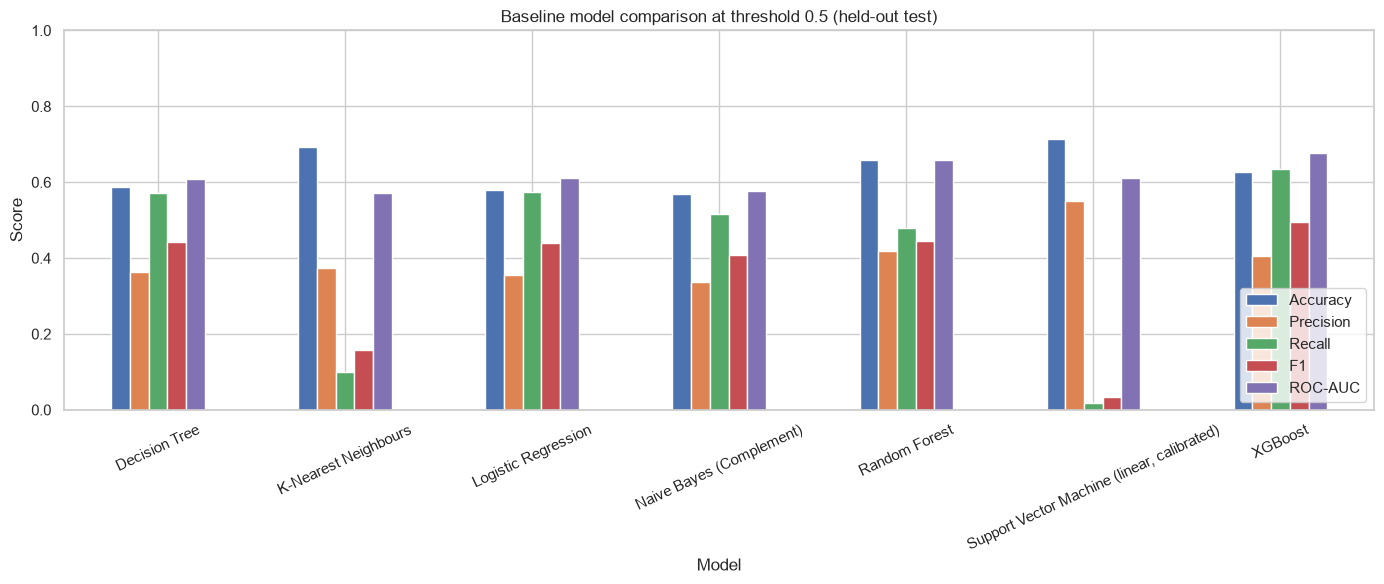

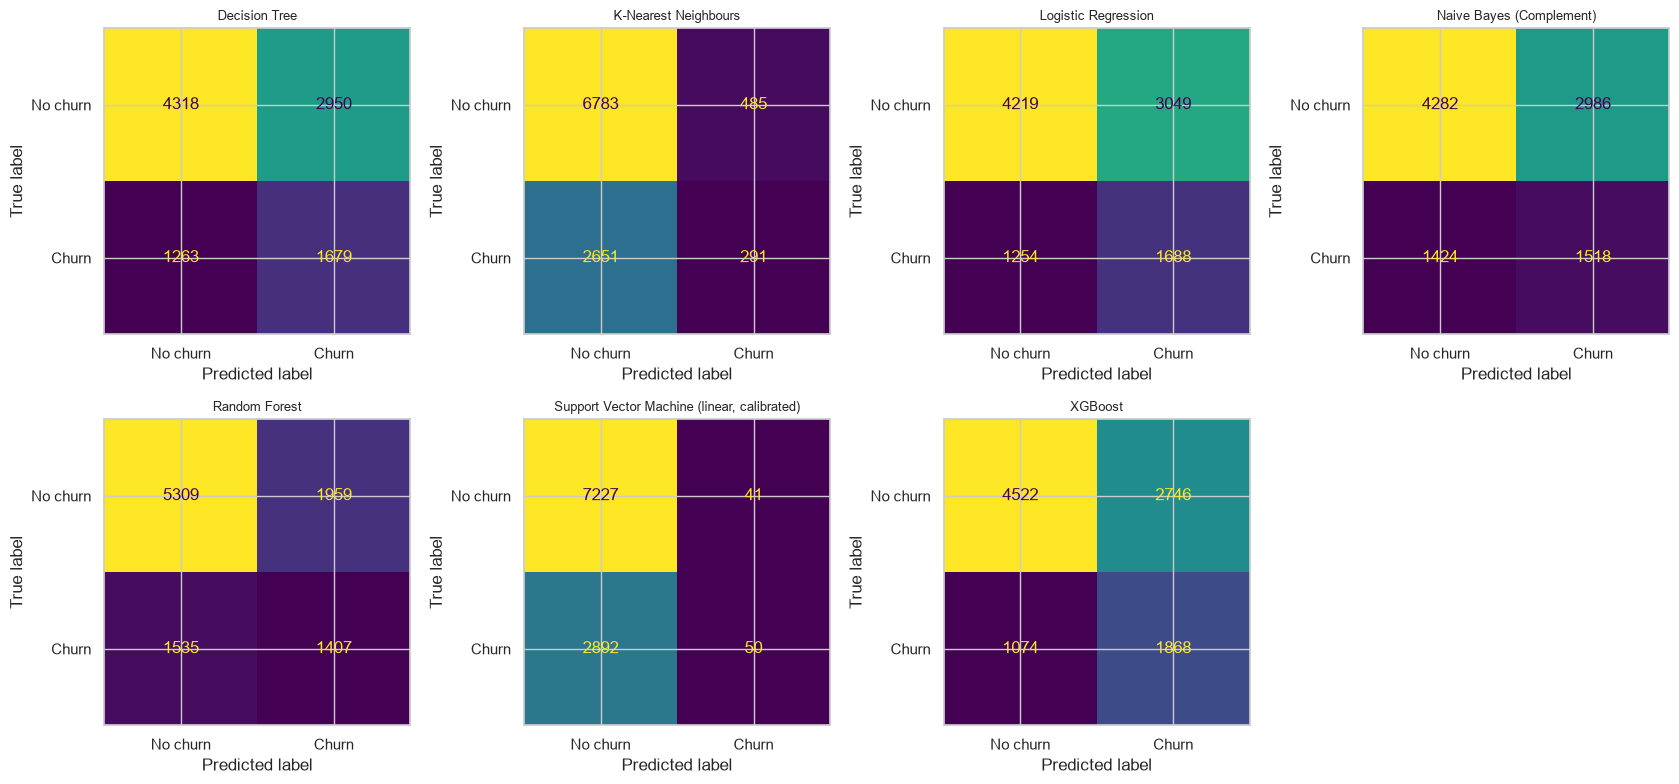

In [143]:
metrics[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(
    kind="bar", figsize=(14, 6), ylim=(0, 1), rot=25
)
plt.title("Baseline model comparison at threshold 0.5 (held-out test)")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, name in zip(axes.flat, metrics.index):
    ConfusionMatrixDisplay(confusion_matrix=confusion_matrices[name], display_labels=["No churn", "Churn"]).plot(
        ax=ax, colorbar=False, values_format="d"
    )
    ax.set_title(name, fontsize=9)
for ax in axes.flat[len(metrics):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [144]:
# Step 10: Set Up Validation Models

In [145]:
X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train, y_train, test_size=0.20, random_state=43, stratify=y_train
)

validation_class_weight = float((y_fit == 0).sum() / (y_fit == 1).sum())
candidate_estimators = {
    "Logistic Regression (unweighted)": LogisticRegression(
        max_iter=1500, class_weight=None, random_state=SEED
    ),
    "Logistic Regression (balanced)": LogisticRegression(
        max_iter=1500, class_weight="balanced", random_state=SEED
    ),
    "Random Forest (unweighted)": RandomForestClassifier(
        n_estimators=250, max_depth=18, min_samples_leaf=5,
        class_weight=None, n_jobs=-1, random_state=SEED
    ),
    "Random Forest (balanced)": RandomForestClassifier(
        n_estimators=250, max_depth=18, min_samples_leaf=5,
        class_weight="balanced_subsample", n_jobs=-1, random_state=SEED
    ),
    "XGBoost (unweighted)": XGBClassifier(
        objective="binary:logistic", eval_metric="logloss", n_estimators=300,
        max_depth=4, learning_rate=0.04, subsample=0.85, colsample_bytree=0.85,
        scale_pos_weight=1, tree_method="hist", n_jobs=4, random_state=SEED
    ),
    "XGBoost (weighted)": XGBClassifier(
        objective="binary:logistic", eval_metric="logloss", n_estimators=300,
        max_depth=4, learning_rate=0.04, subsample=0.85, colsample_bytree=0.85,
        scale_pos_weight=validation_class_weight, tree_method="hist",
        n_jobs=4, random_state=SEED
    ),
}

In [146]:
# Step 11: Tune Validation Thresholds

In [147]:
# Step 11: Fit Candidate Models on the Validation Split
threshold_grid = np.linspace(0.0, 1.0, 201)
validation_summaries = {}
validation_pipelines = {}
validation_probabilities = {}

for candidate_name, estimator in candidate_estimators.items():
    validation_pipeline = Pipeline([
        ("preprocessor", make_preprocessor(StandardScaler())),
        ("classifier", clone(estimator)),
    ])
    validation_pipeline.fit(X_fit, y_fit)
    validation_pipelines[candidate_name] = validation_pipeline
    validation_probabilities[candidate_name] = validation_pipeline.predict_proba(X_validation)[:, 1]
    print("Finished:", candidate_name)

Finished: Logistic Regression (unweighted)


Finished: Logistic Regression (balanced)


Finished: Random Forest (unweighted)


Finished: Random Forest (balanced)


Finished: XGBoost (unweighted)


Finished: XGBoost (weighted)


In [148]:
# Step 11: Compare Candidate Thresholds on Validation Data
for candidate_name, probabilities in validation_probabilities.items():
    threshold_scores = []

    for threshold in threshold_grid:
        predictions = (probabilities >= threshold).astype("int8")
        threshold_scores.append({
            "threshold": float(threshold),
            "accuracy": accuracy_score(y_validation, predictions),
            "precision": precision_score(y_validation, predictions, zero_division=0),
            "recall": recall_score(y_validation, predictions, zero_division=0),
            "f1": f1_score(y_validation, predictions, zero_division=0),
        })

    best_f1 = max(
        threshold_scores,
        key=lambda row: (row["f1"], row["recall"], row["precision"], row["accuracy"]),
    )
    best_accuracy = max(
        threshold_scores,
        key=lambda row: (row["accuracy"], row["f1"], row["recall"], row["precision"]),
    )
    default_threshold = next(row for row in threshold_scores if row["threshold"] == 0.5)
    validation_summaries[candidate_name] = {
        "default_threshold": default_threshold,
        "f1_threshold": best_f1,
        "accuracy_threshold": best_accuracy,
    }

print("Validation threshold comparison is complete.")

Validation threshold comparison is complete.


In [149]:
# Step 11: Display the Validation Model Comparison
validation_results = pd.DataFrame([
    {
        "Candidate": name,
        "Threshold": summary["accuracy_threshold"]["threshold"],
        "Accuracy": summary["accuracy_threshold"]["accuracy"],
        "Precision": summary["accuracy_threshold"]["precision"],
        "Recall": summary["accuracy_threshold"]["recall"],
        "F1": summary["accuracy_threshold"]["f1"],
    }
    for name, summary in validation_summaries.items()
]).sort_values("Accuracy", ascending=False)
display(validation_results.style.format({
    column: "{:.3f}"
    for column in validation_results.select_dtypes(include="number").columns
}))

,Candidate,Threshold,Accuracy,Precision,Recall,F1
4,XGBoost (unweighted),0.495,0.723,0.619,0.103,0.176
5,XGBoost (weighted),0.700,0.721,0.611,0.091,0.159
2,Random Forest (unweighted),0.425,0.721,0.607,0.091,0.159
3,Random Forest (balanced),0.620,0.718,0.641,0.052,0.097
0,Logistic Regression (unweighted),0.665,0.712,0.591,0.006,0.011
1,Logistic Regression (balanced),0.820,0.712,0.528,0.008,0.016


In [150]:
# Step 11: Select a Model Using Validation Accuracy
selected_candidate = max(
    validation_summaries,
    key=lambda name: (
        validation_summaries[name]["accuracy_threshold"]["accuracy"],
        validation_summaries[name]["accuracy_threshold"]["f1"],
        validation_summaries[name]["accuracy_threshold"]["recall"],
        validation_summaries[name]["accuracy_threshold"]["precision"],
    ),
)
final_threshold = validation_summaries[selected_candidate]["accuracy_threshold"]["threshold"]
print("Selected using validation data:", selected_candidate)
print("Selected threshold:", round(final_threshold, 3))
print("Validation scores:", validation_summaries[selected_candidate]["accuracy_threshold"])

Selected using validation data: XGBoost (unweighted)
Selected threshold: 0.495
Validation scores: {'threshold': 0.495, 'accuracy': 0.7231880509304603, 'precision': 0.618925831202046, 'recall': 0.102803738317757, 'f1': 0.17632058287795993}


In [151]:
# Step 12: Evaluate Candidates

In [152]:
# Step 12: Fit Candidate Models on All Training Rows
# Refit each candidate on all training rows. Thresholds remain those selected on validation.
paired_test_pipelines = {}
paired_test_probabilities = {}


In [153]:
# Step 12: Compare the Candidates on the Untouched Test Set
paired_rows = []
for candidate_name, estimator in candidate_estimators.items():
    test_pipeline = Pipeline([
        ("preprocessor", make_preprocessor(StandardScaler())),
        ("classifier", clone(estimator)),
    ])
    test_pipeline.fit(X_train, y_train)
    probabilities = test_pipeline.predict_proba(X_test)[:, 1]
    paired_test_pipelines[candidate_name] = test_pipeline
    paired_test_probabilities[candidate_name] = probabilities

    threshold_options = [
        ("Default 0.5", validation_summaries[candidate_name]["default_threshold"]),
        ("Validation F1", validation_summaries[candidate_name]["f1_threshold"]),
        ("Validation accuracy", validation_summaries[candidate_name]["accuracy_threshold"]),
    ]
    for threshold_name, validation_metrics in threshold_options:
        threshold = validation_metrics["threshold"]
        predictions = (probabilities >= threshold).astype("int8")
        paired_rows.append({
            "Candidate": candidate_name,
            "Threshold choice": threshold_name,
            "Threshold": threshold,
            "Validation accuracy": validation_metrics["accuracy"],
            "Validation precision": validation_metrics["precision"],
            "Validation recall": validation_metrics["recall"],
            "Validation F1": validation_metrics["f1"],
            "Test accuracy": accuracy_score(y_test, predictions),
            "Test precision": precision_score(y_test, predictions, zero_division=0),
            "Test recall": recall_score(y_test, predictions, zero_division=0),
            "Test F1": f1_score(y_test, predictions, zero_division=0),
            "Test ROC-AUC": roc_auc_score(y_test, probabilities),
        })

paired_results = pd.DataFrame(paired_rows)
print("Weighted and unweighted candidates; all test metrics use the same untouched test rows.")
display(paired_results.style.format({column: "{:.3f}" for column in paired_results.select_dtypes(include="number").columns}))

Weighted and unweighted candidates; all test metrics use the same untouched test rows.


,Candidate,Threshold choice,Threshold,Validation accuracy,Validation precision,Validation recall,Validation F1,Test accuracy,Test precision,Test recall,Test F1,Test ROC-AUC
0,Logistic Regression (unweighted),Default 0.5,0.500,0.707,0.422,0.044,0.079,0.711,0.479,0.052,0.093,0.611
1,Logistic Regression (unweighted),Validation F1,0.255,0.524,0.347,0.740,0.473,0.515,0.339,0.717,0.460,0.611
2,Logistic Regression (unweighted),Validation accuracy,0.665,0.712,0.591,0.006,0.011,0.713,0.684,0.004,0.009,0.611
3,Logistic Regression (balanced),Default 0.5,0.500,0.583,0.362,0.586,0.448,0.579,0.356,0.574,0.440,0.611
4,Logistic Regression (balanced),Validation F1,0.420,0.465,0.330,0.832,0.473,0.460,0.325,0.809,0.463,0.611
5,Logistic Regression (balanced),Validation accuracy,0.820,0.712,0.528,0.008,0.016,0.713,0.700,0.007,0.014,0.611
6,Random Forest (unweighted),Default 0.5,0.500,0.716,0.667,0.026,0.051,0.716,0.669,0.032,0.060,0.661
7,Random Forest (unweighted),Validation F1,0.260,0.530,0.361,0.817,0.501,0.522,0.353,0.793,0.489,0.661
8,Random Forest (unweighted),Validation accuracy,0.425,0.721,0.607,0.091,0.159,0.718,0.577,0.079,0.139,0.661
9,Random Forest (balanced),Default 0.5,0.500,0.671,0.433,0.455,0.444,0.658,0.418,0.478,0.446,0.659


In [154]:
# Step 13: Select the Final Model

In [155]:
print("Selected using the validation split only:")
print(f"Model: {selected_candidate}")
print(f"Validation accuracy: {validation_summaries[selected_candidate]['accuracy_threshold']['accuracy']:.4f}")
print(f"Decision threshold: {final_threshold:.3f}")

Selected using the validation split only:
Model: XGBoost (unweighted)
Validation accuracy: 0.7232
Decision threshold: 0.495


In [156]:
# Step 14: Final Evaluation

In [157]:
final_pipeline = paired_test_pipelines[selected_candidate]
final_pipeline.decision_threshold = final_threshold
final_probabilities = paired_test_probabilities[selected_candidate]
final_predictions = (final_probabilities >= final_threshold).astype("int8")
final_matrix = confusion_matrix(y_test, final_predictions, labels=[0, 1])
baseline_accuracy = accuracy_score(y_test, np.zeros(len(y_test), dtype="int8"))

final_metric_row = paired_results[
    (paired_results["Candidate"] == selected_candidate)
    & (paired_results["Threshold"] == final_threshold)
].iloc[0]
final_metrics = final_metric_row[[
    "Test accuracy", "Test precision", "Test recall", "Test F1", "Test ROC-AUC"
]]
print(f"Selected model: {selected_candidate}")
print(f"Validation-selected threshold: {final_threshold:.3f}")
print(final_metrics.to_string(float_format=lambda value: f"{value:.4f}"))
print(f"Always-predict-No test baseline accuracy: {baseline_accuracy:.4f}")
print("Confusion matrix [rows=true, columns=predicted; labels 0=No, 1=Yes]:")
print(final_matrix)
print(f"False negatives (missed churners): {final_matrix[1, 0]:,}")
print(f"False positives: {final_matrix[0, 1]:,}")

Selected model: XGBoost (unweighted)
Validation-selected threshold: 0.495
Test accuracy    0.7193
Test precision   0.5779
Test recall      0.0959
Test F1          0.1644
Test ROC-AUC     0.6774
Always-predict-No test baseline accuracy: 0.7119
Confusion matrix [rows=true, columns=predicted; labels 0=No, 1=Yes]:
[[7062  206]
 [2660  282]]
False negatives (missed churners): 2,660
False positives: 206


In [158]:
# Step 15: Save Final Model

In [159]:
if MODEL_PATH.exists() and not MODEL_BACKUP_PATH.exists():
    shutil.copy2(MODEL_PATH, MODEL_BACKUP_PATH)
    print(f"Backed up the previous model to {MODEL_BACKUP_PATH}")

joblib.dump(final_pipeline, MODEL_PATH)
print(f"Saved complete fitted Pipeline: {MODEL_PATH}")
print(f"Expected input feature count: {len(final_pipeline.feature_names_in_)}")
print(f"Saved decision threshold: {final_pipeline.decision_threshold:.3f}")
print("Target mapping: No -> 0, Yes -> 1")

Saved complete fitted Pipeline: C:\Users\dell\Downloads\Customer-Churn-Prediction\models\churn_model.pkl
Expected input feature count: 56
Saved decision threshold: 0.495
Target mapping: No -> 0, Yes -> 1


In [160]:
# Step 16: Predict Holdout Customers

In [161]:
holdout_X = clean_holdout.drop(columns=["Churn", "CustomerID"], errors="ignore")
if list(holdout_X.columns) != list(final_pipeline.feature_names_in_):
    raise ValueError("Holdout feature order/schema does not match the saved model.")
holdout_probabilities = final_pipeline.predict_proba(holdout_X)[:, 1]
holdout_classes = (holdout_probabilities >= final_pipeline.decision_threshold).astype("int8")
holdout_predictions = pd.DataFrame({
    "CustomerID": clean_holdout["CustomerID"].to_numpy() if "CustomerID" in clean_holdout else np.arange(len(clean_holdout)),
    "PredictedChurn": holdout_classes,
    "ChurnProbability": holdout_probabilities,
})
holdout_predictions["PredictedChurn"] = holdout_predictions["PredictedChurn"].map({0: "No", 1: "Yes"})
print(f"Generated predictions for {len(holdout_predictions):,} unlabeled holdout rows; no holdout metric was calculated.")
display(holdout_predictions.head())

Generated predictions for 20,000 unlabeled holdout rows; no holdout metric was calculated.


,CustomerID,PredictedChurn,ChurnProbability
0,3000006,No,0.117126
1,3000018,No,0.210734
2,3000034,No,0.323665
3,3000070,No,0.148748
4,3000074,No,0.151934


In [162]:
# Step 17: Conclusion